# Weather & Time Contextual Recommendation

### This notebook looks at the weather and time components to determine suitabilityfor our egocentric activity recommendation system 

### Weather Context

The weather component will look at aspects such as temperature, precipitation, and other weather conditions to see how they affect the suitably of different activities.

### Time Context

The time component will look at the time of day it is and see how suitable an activity is based on the activity's operating hours.

## Load Dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project directory
project = Path(
    "/Users/ogechikaesedebe/Downloads/Activity-Recommendation-System"
)

# Existing activity dataset
activity_path = (
    project / "data" / "processed" / "activity_dataset.csv"
)

# Load dataset
activity_df = pd.read_csv(
    activity_path,
    low_memory=False
)

print("Dataset shape:", activity_df.shape)

print("\nAvailable columns:")
print(activity_df.columns.tolist())

print("\nFirst five rows:")
display(activity_df.head())

Dataset shape: (86577, 17)

Available columns:
['name', 'address', 'gmap_id', 'description', 'latitude', 'longitude', 'category', 'avg_rating', 'num_of_reviews', 'price', 'hours', 'MISC', 'state', 'relative_results', 'url', 'is_activity', 'activity_groups']

First five rows:


,name,address,gmap_id,description,latitude,longitude,category,avg_rating,num_of_reviews,price,hours,MISC,state,relative_results,url,is_activity,activity_groups
0,Chef Chucks Table,"Chef Chucks Table, 6128 NY-89, Ovid, NY 14521",0x89d0be3bcc338707:0x3e3d9bf1247ba191,NaN,42.727924,-76.765099,['Diner'],4.7,3,NaN,"[['Thursday', 'Closed'], ['Friday', 'Closed'],...","{'Service options': ['Delivery'], 'Amenities':...",Permanently closed,"['0x89d0eba9d9c0f817:0x1f127a3049db854d', '0x8...",https://www.google.com/maps/place//data=!4m2!3...,True,['Food & Drink']
1,Arcana Juventa Anti-Aging Spa,"Arcana Juventa Anti-Aging Spa, 14 Brighton 11t...",0x89c244688b7609cd:0x205e2d8d173dd35e,NaN,40.582130,-73.956333,"['Spa', 'Waterproofing company']",4.1,15,NaN,"[['Thursday', '10AM–8PM'], ['Friday', '10AM–8P...",NaN,Permanently closed,"['0x89c2446bdf00743d:0x1a016c5e3c603c88', '0x8...",https://www.google.com/maps/place//data=!4m2!3...,True,['Sports & Recreation']
2,Honeoye Creek Wildlife Management Area,"Honeoye Creek Wildlife Management Area, 9033 A...",0x89d13fd0bc4468e1:0x1a81c620f5086b11,NaN,42.806571,-77.525743,"['Nature preserve', 'Park']",4.7,7,NaN,NaN,NaN,NaN,"['0x89d113b7ef15c121:0xe71429a0a567a625', '0x8...",https://www.google.com/maps/place//data=!4m2!3...,True,['Outdoor & Nature']
3,VeganPro Sweets NYC,NaN,0x89c25923cbb1c20d:0xd9edcb0a146ba104,NaN,40.705649,-73.977940,"['Dessert shop', 'Service establishment']",5.0,13,NaN,"[['Thursday', 'Open 24 hours'], ['Friday', 'Op...",{'From the business': ['Identifies as women-le...,Open 24 hours,NaN,https://www.google.com/maps/place//data=!4m2!3...,True,['Food & Drink']
4,Dunkin',"Dunkin', 4008 Bell Blvd, Queens, NY 11361",0x89c261f60bdf13db:0x38da730e4687a97b,Long-running chain serving signature breakfast...,40.763985,-73.771430,"['Coffee shop', 'Bagel shop', 'Bakery', 'Break...",3.5,8,$,"[['Thursday', '6AM–7PM'], ['Friday', '6AM–7PM'...","{'Service options': ['Delivery', 'Takeout', 'D...",Open ⋅ Closes 7PM,"['0x89c3ab9229879ec3:0x3f4b2b46d7d2c503', '0x8...",https://www.google.com/maps/place//data=!4m2!3...,True,['Food & Drink']


In [2]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3.12
Python version: 3.12.1 (v3.12.1:2305ca5144, Dec  7 2023, 17:23:39) [Clang 13.0.0 (clang-1300.0.29.30)]


## Analyzing the available contextual metadata

In [3]:
# Columns needed for weather and time suitability
context_columns = [
    "name",
    "category",
    "activity_groups",
    "latitude",
    "longitude",
    "hours",
    "is_activity"
]

# Check missing values
metadata_summary = pd.DataFrame({
    "Non-Missing": activity_df[context_columns].notna().sum(),
    "Missing": activity_df[context_columns].isna().sum(),
    "Missing (%)": (
        activity_df[context_columns].isna().mean() * 100
    ).round(2)
})

print("CONTEXTUAL METADATA COMPLETENESS")
display(metadata_summary)

# Examine activity group distribution
print("\nACTIVITY GROUP DISTRIBUTION")
display(
    activity_df["activity_groups"]
    .value_counts(dropna=False)
    .head(20)
)

# Inspect sample category and hours values
print("\nSAMPLE ACTIVITY METADATA")
display(
    activity_df[
        ["name", "category", "activity_groups", "hours"]
    ].head(10)
)


CONTEXTUAL METADATA COMPLETENESS


,Non-Missing,Missing,Missing (%)
name,86577,0,0.00
category,86577,0,0.00
activity_groups,86577,0,0.00
latitude,86577,0,0.00
longitude,86577,0,0.00
hours,74039,12538,14.48
is_activity,86577,0,0.00



ACTIVITY GROUP DISTRIBUTION


activity_groups
['Food & Drink']                                                                                  65823
['Sports & Recreation']                                                                            4551
['Outdoor & Nature']                                                                               4464
['Arts & Culture']                                                                                 2580
['Outdoor & Nature', 'Sightseeing & Attractions']                                                  2327
['Food & Drink', 'Nightlife & Live Entertainment']                                                 1348
['Arts & Culture', 'Sightseeing & Attractions']                                                    1252
['Sightseeing & Attractions']                                                                      1162
['Games & Activities']                                                                              847
['Nightlife & Live Entertainment']              


SAMPLE ACTIVITY METADATA


,name,category,activity_groups,hours
0,Chef Chucks Table,['Diner'],['Food & Drink'],"[['Thursday', 'Closed'], ['Friday', 'Closed'],..."
1,Arcana Juventa Anti-Aging Spa,"['Spa', 'Waterproofing company']",['Sports & Recreation'],"[['Thursday', '10AM–8PM'], ['Friday', '10AM–8P..."
2,Honeoye Creek Wildlife Management Area,"['Nature preserve', 'Park']",['Outdoor & Nature'],NaN
3,VeganPro Sweets NYC,"['Dessert shop', 'Service establishment']",['Food & Drink'],"[['Thursday', 'Open 24 hours'], ['Friday', 'Op..."
4,Dunkin',"['Coffee shop', 'Bagel shop', 'Bakery', 'Break...",['Food & Drink'],"[['Thursday', '6AM–7PM'], ['Friday', '6AM–7PM'..."
5,Driscoll RD Kayak Access point,['Nature preserve'],['Outdoor & Nature'],NaN
6,Viele Pond,['Lake'],['Outdoor & Nature'],NaN
7,Tivoli Bays Management Area Parking,['Park'],['Outdoor & Nature'],NaN
8,Raffaello Kosher Pizza,['Restaurant'],['Food & Drink'],NaN
9,Casa Malinche,['Mexican restaurant'],['Food & Drink'],"[['Thursday', '11AM–9:30PM'], ['Friday', '11AM..."


## Preparing Activity Groups for Weather Context

In [4]:
import ast
from collections import Counter

# Convert string representations of lists into Python lists
def parse_activity_groups(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

activity_df["parsed_activity_groups"] = (
    activity_df["activity_groups"].apply(parse_activity_groups)
)

# Count each individual activity group
group_counts = Counter(
    group
    for groups in activity_df["parsed_activity_groups"]
    for group in groups
)

group_summary = pd.DataFrame(
    group_counts.items(),
    columns=["Activity Group", "Number of Activities"]
).sort_values(
    "Number of Activities",
    ascending=False
).reset_index(drop=True)

print("INDIVIDUAL ACTIVITY GROUP DISTRIBUTION")
display(group_summary)

print("\nSAMPLE PARSED ACTIVITY GROUPS")
display(
    activity_df[
        ["name", "activity_groups", "parsed_activity_groups"]
    ].head(10)
)

print(
    "\nActivities with no parsed groups:",
    (activity_df["parsed_activity_groups"].str.len() == 0).sum()
)

INDIVIDUAL ACTIVITY GROUP DISTRIBUTION


,Activity Group,Number of Activities
0,Food & Drink,67820
1,Outdoor & Nature,7423
2,Sightseeing & Attractions,5478
3,Sports & Recreation,5196
4,Arts & Culture,4120
5,Nightlife & Live Entertainment,2086
6,Games & Activities,1650



SAMPLE PARSED ACTIVITY GROUPS


,name,activity_groups,parsed_activity_groups
0,Chef Chucks Table,['Food & Drink'],[Food & Drink]
1,Arcana Juventa Anti-Aging Spa,['Sports & Recreation'],[Sports & Recreation]
2,Honeoye Creek Wildlife Management Area,['Outdoor & Nature'],[Outdoor & Nature]
3,VeganPro Sweets NYC,['Food & Drink'],[Food & Drink]
4,Dunkin',['Food & Drink'],[Food & Drink]
5,Driscoll RD Kayak Access point,['Outdoor & Nature'],[Outdoor & Nature]
6,Viele Pond,['Outdoor & Nature'],[Outdoor & Nature]
7,Tivoli Bays Management Area Parking,['Outdoor & Nature'],[Outdoor & Nature]
8,Raffaello Kosher Pizza,['Food & Drink'],[Food & Drink]
9,Casa Malinche,['Food & Drink'],[Food & Drink]



Activities with no parsed groups: 0


## Examining Detailed Activity Categories

In [5]:
# Reuse the list-parsing function from Step 3
activity_df["parsed_categories"] = (
    activity_df["category"].apply(parse_activity_groups)
)

# Count individual detailed categories
category_counts = Counter(
    category
    for categories in activity_df["parsed_categories"]
    for category in categories
)

category_summary = pd.DataFrame(
    category_counts.items(),
    columns=["Category", "Number of Activities"]
).sort_values(
    "Number of Activities",
    ascending=False
).reset_index(drop=True)

print("TOTAL UNIQUE DETAILED CATEGORIES:")
print(len(category_summary))

print("\nTOP 40 DETAILED CATEGORIES:")
display(category_summary.head(40))

print("\nSAMPLE ACTIVITIES WITH DETAILED CATEGORIES:")
display(
    activity_df[
        ["name", "parsed_categories", "parsed_activity_groups"]
    ].sample(15, random_state=42)
)

TOTAL UNIQUE DETAILED CATEGORIES:
1604

TOP 40 DETAILED CATEGORIES:


,Category,Number of Activities
0,Restaurant,18828
1,Bar,7704
2,Fast food restaurant,6437
3,Pizza restaurant,5996
4,Delivery Restaurant,5754
5,Coffee shop,5582
6,Takeout Restaurant,5370
7,American restaurant,5163
8,Bakery,4854
9,Tourist attraction,4715



SAMPLE ACTIVITIES WITH DETAILED CATEGORIES:


,name,parsed_categories,parsed_activity_groups
67915,Atlantic Diner,[Diner],[Food & Drink]
62777,Helium Comedy Club,"[Comedy club, Bar, Night club, Performing arts...","[Food & Drink, Arts & Culture, Nightlife & Liv..."
48973,Oslo Coffee Roasters,"[Coffee shop, Cafe, Espresso bar]",[Food & Drink]
81010,Popeyes Louisiana Kitchen,"[Chicken restaurant, Cajun restaurant, Fast fo...",[Food & Drink]
58893,Mumbai Place,[Indian restaurant],[Food & Drink]
52040,Monks on the Commons,"[American restaurant, Bar]",[Food & Drink]
80398,Mokum,[Restaurant],[Food & Drink]
35841,Cheri's Bedstuy,[Southern restaurant (US)],[Food & Drink]
66161,Good Eats,"[Diner, American restaurant, Hamburger restaur...",[Food & Drink]
6748,Pizza Plus,"[Pizza restaurant, Restaurant]",[Food & Drink]


## Initial Weather Exposure Classification

In [6]:
# Initial category keywords indicating outdoor activities
outdoor_keywords = [
    "park",
    "hiking",
    "trail",
    "nature preserve",
    "beach",
    "botanical garden",
    "campground",
    "outdoor swimming",
    "kayak",
    "marina",
    "golf course",
    "playground"
]

# Initial category keywords indicating indoor activities
indoor_keywords = [
    "museum",
    "art gallery",
    "spa",
    "movie theater",
    "cinema",
    "bowling alley",
    "indoor playground",
    "fitness center",
    "gym",
    "library",
    "aquarium",
    "escape room",
    "comedy club"
]

def classify_weather_exposure(categories):
    category_text = [
        str(category).lower()
        for category in categories
    ]

    outdoor_match = any(
        keyword in category
        for category in category_text
        for keyword in outdoor_keywords
    )

    indoor_match = any(
        keyword in category
        for category in category_text
        for keyword in indoor_keywords
    )

    if outdoor_match and not indoor_match:
        return "outdoor"

    if indoor_match and not outdoor_match:
        return "indoor"

    return "unknown"


activity_df["weather_exposure"] = (
    activity_df["parsed_categories"]
    .apply(classify_weather_exposure)
)

print("INITIAL WEATHER EXPOSURE DISTRIBUTION")
display(
    activity_df["weather_exposure"]
    .value_counts()
    .to_frame("Number of Activities")
)

print("\nWEATHER EXPOSURE PERCENTAGES")
display(
    activity_df["weather_exposure"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage (%)")
)

print("\nSAMPLE CLASSIFIED ACTIVITIES")
display(
    activity_df[
        ["name", "parsed_categories", "weather_exposure"]
    ].sample(20, random_state=42)
)

INITIAL WEATHER EXPOSURE DISTRIBUTION


,Number of Activities
weather_exposure,
unknown,72775
outdoor,8185
indoor,5617



WEATHER EXPOSURE PERCENTAGES


,Percentage (%)
weather_exposure,
unknown,84.06
outdoor,9.45
indoor,6.49



SAMPLE CLASSIFIED ACTIVITIES


,name,parsed_categories,weather_exposure
67915,Atlantic Diner,[Diner],unknown
62777,Helium Comedy Club,"[Comedy club, Bar, Night club, Performing arts...",indoor
48973,Oslo Coffee Roasters,"[Coffee shop, Cafe, Espresso bar]",unknown
81010,Popeyes Louisiana Kitchen,"[Chicken restaurant, Cajun restaurant, Fast fo...",unknown
58893,Mumbai Place,[Indian restaurant],unknown
52040,Monks on the Commons,"[American restaurant, Bar]",unknown
80398,Mokum,[Restaurant],unknown
35841,Cheri's Bedstuy,[Southern restaurant (US)],unknown
66161,Good Eats,"[Diner, American restaurant, Hamburger restaur...",unknown
6748,Pizza Plus,"[Pizza restaurant, Restaurant]",unknown


## Validating Weather Exposure Classification

In [7]:
# Inspect a reproducible sample of outdoor activities
outdoor_sample = (
    activity_df[
        activity_df["weather_exposure"] == "outdoor"
    ][["name", "parsed_categories", "parsed_activity_groups"]]
    .sample(15, random_state=42)
)

print("SAMPLE OUTDOOR ACTIVITIES")
display(outdoor_sample)

# Inspect a reproducible sample of indoor activities
indoor_sample = (
    activity_df[
        activity_df["weather_exposure"] == "indoor"
    ][["name", "parsed_categories", "parsed_activity_groups"]]
    .sample(15, random_state=42)
)

print("\nSAMPLE INDOOR ACTIVITIES")
display(indoor_sample)

SAMPLE OUTDOOR ACTIVITIES


,name,parsed_categories,parsed_activity_groups
46030,Horace Harding Playground,[Playground],[Games & Activities]
55737,Kennedy Memorial Park,"[Park, Tourist attraction]","[Outdoor & Nature, Sightseeing & Attractions]"
25999,Calvin Engle Park,[Park],[Outdoor & Nature]
26388,Stehli Town Beach,[Beach],[Outdoor & Nature]
11140,Greens At Beaumont,[Golf course],[Sports & Recreation]
38715,Triborough Bridge Playground A,[Park],[Outdoor & Nature]
25012,Spaulding Lake Club,[Park],[Outdoor & Nature]
70073,Ashokan Rail Trail- Ashokan Station Trailhead,[Hiking area],[Sports & Recreation]
60668,Cooney Grauer Field,"[Park, Baseball field, Tourist attraction]","[Outdoor & Nature, Sports & Recreation, Sights..."
29335,MacDonough Park,[Park],[Outdoor & Nature]



SAMPLE INDOOR ACTIVITIES


,name,parsed_categories,parsed_activity_groups
49893,Sangarita's Tapas Wine,"[Spanish restaurant, Bar, Lounge, Tapas bar, T...","[Food & Drink, Nightlife & Live Entertainment]"
32989,PRESS Massage Williamsburg,"[Massage spa, Massage therapist, Wellness center]",[Sports & Recreation]
611,Red Sun Foot Spa L&C,[Massage spa],[Sports & Recreation]
17938,Parking lot,[Museum],[Arts & Culture]
82823,Museum of American Armor,"[Museum, Tourist attraction]","[Arts & Culture, Sightseeing & Attractions]"
2661,Nunda Historical Society,"[Local history museum, Art gallery, Tourist at...","[Arts & Culture, Sightseeing & Attractions]"
53751,New Attitude Salon and Wellness Spa,"[Massage therapist, Facial spa, Hair salon, Ma...",[Sports & Recreation]
17121,Brennan & Griffin,[Art gallery],[Arts & Culture]
15438,Newman Plastic Surgery & Laser Center: Scott N...,"[Plastic surgeon, Laser hair removal service, ...",[Sports & Recreation]
6932,Jose Luis,"[Italian restaurant, Mediterranean restaurant,...",[Food & Drink]


### Notes:

##### Weather exposure classification: Our keyword matching is too broad. For example, "park" matches "business park".



##### Activity relevance: Some records may not be appropriate recreational recommendations, even when their indoor/outdoor classification is technically correct.

## Refining Weather Exposure Classification

In [8]:
# Specific outdoor category labels
outdoor_categories = {
    "park",
    "playground",
    "beach",
    "nature preserve",
    "hiking area",
    "campground",
    "golf course",
    "botanical garden",
    "marina",
    "kayak rental service",
    "baseball field",
    "basketball court",
    "soccer field",
    "tennis court",
    "state park",
    "national park",
    "wildlife refuge"
}

# Specific indoor category labels
indoor_categories = {
    "museum",
    "art museum",
    "history museum",
    "art gallery",
    "spa",
    "day spa",
    "massage spa",
    "movie theater",
    "cinema",
    "bowling alley",
    "gym",
    "fitness center",
    "library",
    "aquarium",
    "escape room center",
    "comedy club"
}

def classify_weather_exposure_v2(categories):
    normalized = {
        str(category).strip().lower()
        for category in categories
    }

    outdoor_match = bool(normalized & outdoor_categories)
    indoor_match = bool(normalized & indoor_categories)

    if outdoor_match and not indoor_match:
        return "outdoor"

    if indoor_match and not outdoor_match:
        return "indoor"

    return "unknown"


activity_df["weather_exposure_v2"] = (
    activity_df["parsed_categories"]
    .apply(classify_weather_exposure_v2)
)

print("REVISED WEATHER EXPOSURE DISTRIBUTION")
display(
    activity_df["weather_exposure_v2"]
    .value_counts()
    .to_frame("Number of Activities")
)

print("\nCLASSIFICATION CHANGES")
display(
    pd.crosstab(
        activity_df["weather_exposure"],
        activity_df["weather_exposure_v2"],
        rownames=["Original"],
        colnames=["Revised"]
    )
)

print("\nSAMPLE REVISED CLASSIFICATIONS")
display(
    activity_df[
        ["name", "parsed_categories", "weather_exposure_v2"]
    ].sample(20, random_state=42)
)

REVISED WEATHER EXPOSURE DISTRIBUTION


,Number of Activities
weather_exposure_v2,
unknown,74484
outdoor,7620
indoor,4473



CLASSIFICATION CHANGES


Revised,indoor,outdoor,unknown
Original,,,
indoor,4456,1,1160
outdoor,0,7161,1024
unknown,17,458,72300



SAMPLE REVISED CLASSIFICATIONS


,name,parsed_categories,weather_exposure_v2
67915,Atlantic Diner,[Diner],unknown
62777,Helium Comedy Club,"[Comedy club, Bar, Night club, Performing arts...",indoor
48973,Oslo Coffee Roasters,"[Coffee shop, Cafe, Espresso bar]",unknown
81010,Popeyes Louisiana Kitchen,"[Chicken restaurant, Cajun restaurant, Fast fo...",unknown
58893,Mumbai Place,[Indian restaurant],unknown
52040,Monks on the Commons,"[American restaurant, Bar]",unknown
80398,Mokum,[Restaurant],unknown
35841,Cheri's Bedstuy,[Southern restaurant (US)],unknown
66161,Good Eats,"[Diner, American restaurant, Hamburger restaur...",unknown
6748,Pizza Plus,"[Pizza restaurant, Restaurant]",unknown


## Initial Weather Suitability Scoring

In [9]:
# Initial heuristic weather suitability scores
weather_score_rules = {
    "clear": {
        "outdoor": 1.0,
        "indoor": 0.9,
        "unknown": 0.7
    },
    "rain": {
        "outdoor": 0.2,
        "indoor": 1.0,
        "unknown": 0.7
    }
}

def calculate_weather_score(exposure, weather_condition):
    if weather_condition not in weather_score_rules:
        raise ValueError(
            f"Unsupported weather condition: {weather_condition}"
        )

    return weather_score_rules[weather_condition].get(
        exposure, 0.7
    )


# Calculate scores for two weather scenarios
activity_df["weather_score_clear"] = (
    activity_df["weather_exposure_v2"]
    .apply(lambda x: calculate_weather_score(x, "clear"))
)

activity_df["weather_score_rain"] = (
    activity_df["weather_exposure_v2"]
    .apply(lambda x: calculate_weather_score(x, "rain"))
)

print("WEATHER SUITABILITY SCORES BY EXPOSURE")
display(
    activity_df.groupby("weather_exposure_v2")[
        ["weather_score_clear", "weather_score_rain"]
    ].agg(["count", "mean"])
)

print("\nSAMPLE ACTIVITY WEATHER SCORES")
display(
    activity_df[
        [
            "name",
            "weather_exposure_v2",
            "weather_score_clear",
            "weather_score_rain"
        ]
    ].sample(20, random_state=42)
)

WEATHER SUITABILITY SCORES BY EXPOSURE


weather_score_clear      weather_score_rain     
                                  count mean              count mean
weather_exposure_v2                                                 
indoor                             4473  0.9               4473  1.0
outdoor                            7620  1.0               7620  0.2
unknown                           74484  0.7              74484  0.7


SAMPLE ACTIVITY WEATHER SCORES


,name,weather_exposure_v2,weather_score_clear,weather_score_rain
67915,Atlantic Diner,unknown,0.7,0.7
62777,Helium Comedy Club,indoor,0.9,1.0
48973,Oslo Coffee Roasters,unknown,0.7,0.7
81010,Popeyes Louisiana Kitchen,unknown,0.7,0.7
58893,Mumbai Place,unknown,0.7,0.7
52040,Monks on the Commons,unknown,0.7,0.7
80398,Mokum,unknown,0.7,0.7
35841,Cheri's Bedstuy,unknown,0.7,0.7
66161,Good Eats,unknown,0.7,0.7
6748,Pizza Plus,unknown,0.7,0.7


## Incorporating Temperature into Weather Suitability

In [10]:
def calculate_temperature_factor(temperature_c):
    if temperature_c < 0:
        return 0.2
    elif temperature_c < 10:
        return 0.5
    elif temperature_c < 30:
        return 1.0
    elif temperature_c < 35:
        return 0.6
    else:
        return 0.2


def calculate_combined_weather_score(
    exposure,
    weather_condition,
    temperature_c
):
    precipitation_score = calculate_weather_score(
        exposure,
        weather_condition
    )

    if exposure == "outdoor":
        temperature_factor = calculate_temperature_factor(
            temperature_c
        )

        return round(
            precipitation_score * temperature_factor,
            3
        )

    return precipitation_score


# Test the model using different weather scenarios
weather_scenarios = [
    ("Clear, comfortable", "clear", 22),
    ("Clear, freezing", "clear", -5),
    ("Clear, very hot", "clear", 38),
    ("Rainy, comfortable", "rain", 20),
    ("Rainy, cold", "rain", 5)
]

results = []

for scenario_name, condition, temperature in weather_scenarios:
    for exposure in ["outdoor", "indoor", "unknown"]:
        score = calculate_combined_weather_score(
            exposure,
            condition,
            temperature
        )

        results.append({
            "Scenario": scenario_name,
            "Exposure": exposure,
            "Temperature (°C)": temperature,
            "Weather Score": score
        })

weather_scenario_df = pd.DataFrame(results)

print("WEATHER SUITABILITY ACROSS SCENARIOS")
display(
    weather_scenario_df.pivot(
        index="Scenario",
        columns="Exposure",
        values="Weather Score"
    )
)

WEATHER SUITABILITY ACROSS SCENARIOS


Exposure,indoor,outdoor,unknown
Scenario,,,
"Clear, comfortable",0.9,1.0,0.7
"Clear, freezing",0.9,0.2,0.7
"Clear, very hot",0.9,0.2,0.7
"Rainy, cold",1.0,0.1,0.7
"Rainy, comfortable",1.0,0.2,0.7


## Examining Operating Hours for Time Context

In [11]:
# Select activities with available operating hours
hours_available = activity_df[
    activity_df["hours"].notna()
]

print("ACTIVITIES WITH OPERATING HOURS:")
print(len(hours_available))

print("\nSAMPLE OPERATING HOURS:")
for _, row in hours_available[
    ["name", "hours"]
].sample(10, random_state=42).iterrows():
    print(f"\nActivity: {row['name']}")
    print(f"Hours: {row['hours']}")

print("\nACTIVITIES WITH MISSING OPERATING HOURS:")
display(
    activity_df[
        activity_df["hours"].isna()
    ][
        ["name", "parsed_categories", "parsed_activity_groups"]
    ].head(10)
)

ACTIVITIES WITH OPERATING HOURS:
74039

SAMPLE OPERATING HOURS:

Activity: Corner Deli
Hours: [['Saturday', '6AM–4PM'], ['Sunday', '7AM–4PM'], ['Monday', '6AM–5PM'], ['Tuesday', '6AM–5PM'], ['Wednesday', '6AM–5PM'], ['Thursday', '6AM–5PM'], ['Friday', '6AM–5PM']]

Activity: Veterans Memorial Park
Hours: [['Tuesday', 'Open 24 hours'], ['Wednesday', 'Open 24 hours'], ['Thursday', 'Open 24 hours'], ['Friday', 'Open 24 hours'], ['Saturday', 'Open 24 hours'], ['Sunday', 'Open 24 hours'], ['Monday', 'Open 24 hours']]

Activity: Mini Market Best Way Deli
Hours: [['Thursday', 'Open 24 hours'], ['Friday', 'Open 24 hours'], ['Saturday', 'Open 24 hours'], ['Sunday', '8AM–12AM'], ['Monday', 'Open 24 hours'], ['Tuesday', 'Open 24 hours'], ['Wednesday', 'Open 24 hours']]

Activity: Antique Carousel
Hours: [['Friday', '4–9PM'], ['Saturday', '10AM–6PM'], ['Sunday', '10AM–6PM'], ['Monday', 'Closed'], ['Tuesday', 'Closed'], ['Wednesday', 'Closed'], ['Thursday', 'Closed']]

Activity: Food King
Hours: [['

,name,parsed_categories,parsed_activity_groups
2,Honeoye Creek Wildlife Management Area,"[Nature preserve, Park]",[Outdoor & Nature]
5,Driscoll RD Kayak Access point,[Nature preserve],[Outdoor & Nature]
6,Viele Pond,[Lake],[Outdoor & Nature]
7,Tivoli Bays Management Area Parking,[Park],[Outdoor & Nature]
8,Raffaello Kosher Pizza,[Restaurant],[Food & Drink]
12,Claudio's Lounge,[Cocktail bar],[Food & Drink]
14,Cafe Kristall,"[Cafe, Restaurant]",[Food & Drink]
15,Liberty Theater,[Movie theater],[Arts & Culture]
19,Fairmount Playground,"[Park, Tourist attraction]","[Outdoor & Nature, Sightseeing & Attractions]"
20,Lackawanna Steel Company,[Historical landmark],"[Arts & Culture, Sightseeing & Attractions]"


## Parsing Weekly Operating Hours

In [12]:
import ast

WEEKDAYS = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

def parse_weekly_hours(value):
    if isinstance(value, str):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return {}

    if not isinstance(value, list):
        return {}

    weekly_hours = {}

    for entry in value:
        if (
            isinstance(entry, (list, tuple))
            and len(entry) == 2
        ):
            day, hours = entry

            if (
                isinstance(day, str)
                and day in WEEKDAYS
                and isinstance(hours, str)
            ):
                weekly_hours[day] = hours.strip()

    return weekly_hours


activity_df["parsed_hours"] = (
    activity_df["hours"].apply(parse_weekly_hours)
)

print("OPERATING HOURS PARSING SUMMARY")

print(
    "Activities with parsed schedules:",
    (activity_df["parsed_hours"].apply(len) > 0).sum()
)

print(
    "Activities without parsed schedules:",
    (activity_df["parsed_hours"].apply(len) == 0).sum()
)

print("\nSAMPLE PARSED SCHEDULES")

display(
    activity_df[
        ["name", "parsed_hours"]
    ].sample(10, random_state=42)
)

print("\nEXAMPLE: ANTIQUE CAROUSEL")

display(
    activity_df[
        activity_df["name"] == "Antique Carousel"
    ][["name", "parsed_hours"]].head()
)

OPERATING HOURS PARSING SUMMARY
Activities with parsed schedules: 74039
Activities without parsed schedules: 12538

SAMPLE PARSED SCHEDULES


,name,parsed_hours
67915,Atlantic Diner,"{'Sunday': 'Open 24 hours', 'Monday': 'Open 24..."
62777,Helium Comedy Club,"{'Thursday': 'Closed', 'Friday': '5–11:30PM', ..."
48973,Oslo Coffee Roasters,"{'Sunday': '8AM–3PM', 'Monday': '8AM–3PM', 'Tu..."
81010,Popeyes Louisiana Kitchen,"{'Sunday': '10:30AM–8PM', 'Monday': '10:30AM–8..."
58893,Mumbai Place,"{'Monday': '12–10:15PM', 'Tuesday': '12–10:15P..."
52040,Monks on the Commons,"{'Friday': '3–11PM', 'Saturday': '9AM–11PM', '..."
80398,Mokum,{}
35841,Cheri's Bedstuy,"{'Tuesday': 'Closed', 'Wednesday': '11:30AM–10..."
66161,Good Eats,"{'Monday': '8AM–8:30PM', 'Tuesday': '8AM–8:30P..."
6748,Pizza Plus,"{'Monday': '4–6PM', 'Tuesday': '11AM–8PM', 'We..."



EXAMPLE: ANTIQUE CAROUSEL


,name,parsed_hours
76604,Antique Carousel,"{'Friday': '4–9PM', 'Saturday': '10AM–6PM', 'S..."


##  Converting Operating Hours into Numerical Time Intervals


In [13]:
import re

def parse_clock_time(time_text, default_meridiem=None):
    """Convert a 12-hour clock time to minutes after midnight."""
    match = re.fullmatch(
        r"\s*(1[0-2]|[1-9])(?::([0-5]\d))?\s*(AM|PM)?\s*",
        time_text,
        flags=re.IGNORECASE
    )

    if not match:
        return None

    hour = int(match.group(1))
    minute = int(match.group(2) or 0)
    meridiem = (match.group(3) or default_meridiem)

    if meridiem is None:
        return None

    meridiem = meridiem.upper()

    hour = hour % 12
    if meridiem == "PM":
        hour += 12

    return hour * 60 + minute


def parse_time_range(hours_text):
    """Return (opening_minute, closing_minute) or a status."""
    text = hours_text.strip()

    if text.lower() == "closed":
        return "closed"

    if text.lower() == "open 24 hours":
        return (0, 1440)

    parts = re.split(r"\s*[–—-]\s*", text)

    if len(parts) != 2:
        return "unknown"

    start_text, end_text = parts

    end_match = re.search(
        r"(AM|PM)\s*$", end_text, flags=re.IGNORECASE
    )

    if not end_match:
        return "unknown"

    end_meridiem = end_match.group(1).upper()

    # If the opening time has no AM/PM, infer it from
    # the closing time, then adjust if necessary.
    start_has_meridiem = bool(
        re.search(r"(AM|PM)\s*$", start_text, flags=re.IGNORECASE)
    )

    end_minute = parse_clock_time(end_text)

    if start_has_meridiem:
        start_minute = parse_clock_time(start_text)
    else:
        start_minute = parse_clock_time(
            start_text, default_meridiem=end_meridiem
        )

        # Example: 11–2PM means 11AM–2PM.
        if (
            start_minute is not None
            and end_minute is not None
            and start_minute >= end_minute
        ):
            opposite = "AM" if end_meridiem == "PM" else "PM"
            alternative = parse_clock_time(
                start_text, default_meridiem=opposite
            )

            if alternative is not None and alternative < end_minute:
                start_minute = alternative

    if start_minute is None or end_minute is None:
        return "unknown"

    # Closing at or before opening means the interval
    # extends into the following day.
    if end_minute <= start_minute:
        end_minute += 1440

    return (start_minute, end_minute)


# Test the parser on representative examples
test_hours = [
    "10AM–6PM",
    "4–9PM",
    "11AM–9:30PM",
    "8AM–12AM",
    "11–2PM",
    "5:30–11PM",
    "12–10PM",
    "Closed",
    "Open 24 hours"
]

test_results = pd.DataFrame({
    "Original Hours": test_hours,
    "Parsed Result": [
        str(parse_time_range(value))
        for value in test_hours
    ]
})

display(test_results)

,Original Hours,Parsed Result
0,10AM–6PM,"(600, 1080)"
1,4–9PM,"(960, 1260)"
2,11AM–9:30PM,"(660, 1290)"
3,8AM–12AM,"(480, 1440)"
4,11–2PM,"(660, 840)"
5,5:30–11PM,"(1050, 1380)"
6,12–10PM,"(720, 1320)"
7,Closed,closed
8,Open 24 hours,"(0, 1440)"


## Time-Based Activity Availability

In [14]:
def check_activity_availability(weekly_hours, day, hour, minute=0):
    if day not in WEEKDAYS:
        raise ValueError(f"Invalid weekday: {day}")

    if not (0 <= hour <= 23 and 0 <= minute <= 59):
        raise ValueError("Invalid time")

    if not weekly_hours:
        return "unknown"

    requested_minute = hour * 60 + minute
    day_index = WEEKDAYS.index(day)
    previous_day = WEEKDAYS[(day_index - 1) % 7]

    # Check today's schedule
    today_hours = weekly_hours.get(day)

    if today_hours is None:
        today_status = "unknown"
    else:
        today_interval = parse_time_range(today_hours)

        if today_interval == "closed":
            today_status = "closed"
        elif today_interval == "unknown":
            today_status = "unknown"
        elif (
            today_interval[0]
            <= requested_minute
            < today_interval[1]
        ):
            return "open"
        else:
            today_status = "closed"

    # Check overnight opening hours from the previous day
    previous_hours = weekly_hours.get(previous_day)

    if previous_hours is not None:
        previous_interval = parse_time_range(previous_hours)

        if isinstance(previous_interval, tuple):
            if (
                previous_interval[1] > 1440
                and requested_minute
                < previous_interval[1] - 1440
            ):
                return "open"

        elif previous_interval == "unknown":
            if today_status != "closed":
                return "unknown"

    return today_status


# Test cases
test_schedules = [
    (
        "Standard opening",
        {"Monday": "9AM–5PM"},
        "Monday", 11, 0
    ),
    (
        "After closing",
        {"Monday": "9AM–5PM"},
        "Monday", 19, 0
    ),
    (
        "Closed day",
        {"Monday": "Closed"},
        "Monday", 12, 0
    ),
    (
        "24-hour opening",
        {"Monday": "Open 24 hours"},
        "Monday", 23, 0
    ),
    (
        "Overnight opening",
        {"Friday": "8PM–2AM", "Saturday": "Closed"},
        "Saturday", 1, 0
    ),
    (
        "Missing hours",
        {},
        "Monday", 12, 0
    )
]

test_results = []

for name, schedule, day, hour, minute in test_schedules:
    result = check_activity_availability(
        schedule, day, hour, minute
    )

    test_results.append({
        "Test Case": name,
        "Requested Day": day,
        "Requested Time": f"{hour:02d}:{minute:02d}",
        "Availability": result
    })

display(pd.DataFrame(test_results))

,Test Case,Requested Day,Requested Time,Availability
0,Standard opening,Monday,11:00,open
1,After closing,Monday,19:00,closed
2,Closed day,Monday,12:00,closed
3,24-hour opening,Monday,23:00,open
4,Overnight opening,Saturday,01:00,open
5,Missing hours,Monday,12:00,unknown


## Numerical Time Availability Scoring

In [15]:
# Convert availability status into a numerical score
time_score_rules = {
    "open": 1.0,
    "closed": 0.0,
    "unknown": 0.5
}

def calculate_time_score(weekly_hours, day, hour, minute=0):
    availability = check_activity_availability(
        weekly_hours,
        day,
        hour,
        minute
    )

    return time_score_rules[availability]


# Test using a hypothetical recommendation context
requested_day = "Saturday"
requested_hour = 14
requested_minute = 0

# Calculate availability and time scores for all activities
activity_df["time_availability"] = (
    activity_df["parsed_hours"].apply(
        lambda hours: check_activity_availability(
            hours,
            requested_day,
            requested_hour,
            requested_minute
        )
    )
)

activity_df["time_score"] = (
    activity_df["time_availability"].map(time_score_rules)
)

print("TIME AVAILABILITY DISTRIBUTION")
display(
    activity_df["time_availability"]
    .value_counts()
    .to_frame("Number of Activities")
)

print("\nTIME SCORE DISTRIBUTION")
display(
    activity_df["time_score"]
    .value_counts()
    .sort_index()
    .to_frame("Number of Activities")
)

print("\nSAMPLE ACTIVITY TIME SCORES")
display(
    activity_df[
        ["name", "time_availability", "time_score"]
    ].sample(20, random_state=42)
)

TIME AVAILABILITY DISTRIBUTION


,Number of Activities
time_availability,
open,62643
unknown,12538
closed,11396



TIME SCORE DISTRIBUTION


,Number of Activities
time_score,
0.0,11396
0.5,12538
1.0,62643



SAMPLE ACTIVITY TIME SCORES


,name,time_availability,time_score
67915,Atlantic Diner,open,1.0
62777,Helium Comedy Club,closed,0.0
48973,Oslo Coffee Roasters,open,1.0
81010,Popeyes Louisiana Kitchen,open,1.0
58893,Mumbai Place,open,1.0
52040,Monks on the Commons,open,1.0
80398,Mokum,unknown,0.5
35841,Cheri's Bedstuy,open,1.0
66161,Good Eats,open,1.0
6748,Pizza Plus,open,1.0


## Auditing Operating-Hours Parsing

In [16]:
from collections import Counter

# Collect every operating-hours description
all_hour_descriptions = [
    description
    for schedule in activity_df["parsed_hours"]
    for description in schedule.values()
]

# Count parser results
parse_status_counts = Counter()
unrecognized_hours = Counter()

for description in all_hour_descriptions:
    result = parse_time_range(description)

    if result == "unknown":
        parse_status_counts["unknown"] += 1
        unrecognized_hours[description] += 1

    elif result == "closed":
        parse_status_counts["closed"] += 1

    elif isinstance(result, tuple):
        parse_status_counts["parsed_interval"] += 1


print("OPERATING-HOURS PARSING AUDIT")
display(
    pd.DataFrame(
        parse_status_counts.items(),
        columns=["Parsing Status", "Number of Day Entries"]
    )
)

print("\nTOP 20 UNRECOGNIZED HOUR FORMATS")
display(
    pd.DataFrame(
        unrecognized_hours.most_common(20),
        columns=["Hours Description", "Frequency"]
    )
)

print("\nTOTAL UNRECOGNIZED DAY ENTRIES:")
print(sum(unrecognized_hours.values()))

print("\nUNIQUE UNRECOGNIZED FORMATS:")
print(len(unrecognized_hours))

OPERATING-HOURS PARSING AUDIT


,Parsing Status,Number of Day Entries
0,closed,39479
1,parsed_interval,478794



TOP 20 UNRECOGNIZED HOUR FORMATS


,Hours Description,Frequency



TOTAL UNRECOGNIZED DAY ENTRIES:
0

UNIQUE UNRECOGNIZED FORMATS:
0


## Combining Weather and Time Suitability

In [17]:
# Hypothetical recommendation scenario
scenario_weather = "clear"
scenario_temperature = 22

# Calculate weather suitability
activity_df["scenario_weather_score"] = (
    activity_df["weather_exposure_v2"].apply(
        lambda exposure: calculate_combined_weather_score(
            exposure,
            scenario_weather,
            scenario_temperature
        )
    )
)

# Combine weather and time scores
weather_weight = 0.5
time_weight = 0.5

activity_df["context_score"] = (
    weather_weight * activity_df["scenario_weather_score"]
    + time_weight * activity_df["time_score"]
)

# Keep confirmed closure separate from the weighted score
activity_df["context_eligible"] = (
    activity_df["time_availability"] != "closed"
)

print("CONTEXT SCORE SUMMARY")
display(activity_df["context_score"].describe())

print("\nELIGIBILITY DISTRIBUTION")
display(
    activity_df["context_eligible"]
    .value_counts()
    .to_frame("Number of Activities")
)

print("\nSAMPLE COMBINED CONTEXT SCORES")
display(
    activity_df[
        [
            "name",
            "weather_exposure_v2",
            "scenario_weather_score",
            "time_availability",
            "time_score",
            "context_score",
            "context_eligible"
        ]
    ].sample(20, random_state=42)
)

CONTEXT SCORE SUMMARY


count    86577.000000
mean         0.766350
std          0.180562
min          0.350000
25%          0.750000
50%          0.850000
75%          0.850000
max          1.000000
Name: context_score, dtype: float64


ELIGIBILITY DISTRIBUTION


,Number of Activities
context_eligible,
True,75181
False,11396



SAMPLE COMBINED CONTEXT SCORES


,name,weather_exposure_v2,scenario_weather_score,time_availability,time_score,context_score,context_eligible
67915,Atlantic Diner,unknown,0.7,open,1.0,0.85,True
62777,Helium Comedy Club,indoor,0.9,closed,0.0,0.45,False
48973,Oslo Coffee Roasters,unknown,0.7,open,1.0,0.85,True
81010,Popeyes Louisiana Kitchen,unknown,0.7,open,1.0,0.85,True
58893,Mumbai Place,unknown,0.7,open,1.0,0.85,True
52040,Monks on the Commons,unknown,0.7,open,1.0,0.85,True
80398,Mokum,unknown,0.7,unknown,0.5,0.60,True
35841,Cheri's Bedstuy,unknown,0.7,open,1.0,0.85,True
66161,Good Eats,unknown,0.7,open,1.0,0.85,True
6748,Pizza Plus,unknown,0.7,open,1.0,0.85,True


## Comparing Contextual Rankings Across Weather Scenarios

In [18]:
# Compare two weather scenarios
scenarios = {
    "clear_comfortable": ("clear", 22),
    "rainy_cold": ("rain", 5)
}

for scenario_name, (condition, temperature) in scenarios.items():

    weather_scores = activity_df["weather_exposure_v2"].apply(
        lambda exposure: calculate_combined_weather_score(
            exposure,
            condition,
            temperature
        )
    )

    activity_df[f"context_{scenario_name}"] = (
        0.5 * weather_scores
        + 0.5 * activity_df["time_score"]
    )

# Select illustrative activities from different exposure groups
example_names = [
    "Indian Head Trailhead",
    "Helium Comedy Club",
    "Oslo Coffee Roasters",
    "Kennedy Memorial Park",
    "Museum of American Armor",
    "Atlantic Diner"
]

comparison_df = activity_df[
    activity_df["name"].isin(example_names)
][
    [
        "name",
        "weather_exposure_v2",
        "time_availability",
        "context_eligible",
        "context_clear_comfortable",
        "context_rainy_cold"
    ]
].copy()

# Exclude confirmed-closed activities
comparison_df = comparison_df[
    comparison_df["context_eligible"]
]

comparison_df["score_change"] = (
    comparison_df["context_rainy_cold"]
    - comparison_df["context_clear_comfortable"]
)

print("CONTEXTUAL SUITABILITY COMPARISON")
display(
    comparison_df.sort_values(
        "context_clear_comfortable",
        ascending=False
    )
)

CONTEXTUAL SUITABILITY COMPARISON


,name,weather_exposure_v2,time_availability,context_eligible,context_clear_comfortable,context_rainy_cold,score_change
55737,Kennedy Memorial Park,outdoor,open,True,1.00,0.55,-0.45
82823,Museum of American Armor,indoor,open,True,0.95,1.00,0.05
60351,Oslo Coffee Roasters,unknown,open,True,0.85,0.85,0.00
48973,Oslo Coffee Roasters,unknown,open,True,0.85,0.85,0.00
73409,Oslo Coffee Roasters,unknown,open,True,0.85,0.85,0.00
67915,Atlantic Diner,unknown,open,True,0.85,0.85,0.00
84432,Oslo Coffee Roasters,unknown,open,True,0.85,0.85,0.00
38520,Indian Head Trailhead,outdoor,unknown,True,0.75,0.30,-0.45


## Verifying Contextual Scores and Activity Identifiers

In [19]:
# Check activity identifier uniqueness
print("TOTAL ACTIVITIES:", len(activity_df))
print("UNIQUE GMAP IDs:", activity_df["gmap_id"].nunique())
print("DUPLICATED GMAP IDs:", activity_df["gmap_id"].duplicated().sum())

# Verify scores remain within [0, 1]
score_columns = [
    "context_clear_comfortable",
    "context_rainy_cold"
]

for column in score_columns:
    print(
        f"{column}:",
        "Min =", activity_df[column].min(),
        "Max =", activity_df[column].max(),
        "Missing =", activity_df[column].isna().sum()
    )

# Inspect the trailhead record
print("\nINDIAN HEAD TRAILHEAD SCORES")

display(
    activity_df.loc[
        activity_df["name"] == "Indian Head Trailhead",
        [
            "gmap_id",
            "name",
            "weather_exposure_v2",
            "time_score",
            "context_clear_comfortable",
            "context_rainy_cold"
        ]
    ]
)

# Verify scores for eligible activities
eligible_df = activity_df[
    activity_df["context_eligible"]
]

print("\nELIGIBLE ACTIVITY SCORE SUMMARY")

display(
    eligible_df[score_columns].describe()
)

TOTAL ACTIVITIES: 86577
UNIQUE GMAP IDs: 86354
DUPLICATED GMAP IDs: 223
context_clear_comfortable: Min = 0.35 Max = 1.0 Missing = 0
context_rainy_cold: Min = 0.05 Max = 1.0 Missing = 0

INDIAN HEAD TRAILHEAD SCORES


,gmap_id,name,weather_exposure_v2,time_score,context_clear_comfortable,context_rainy_cold
38520,0x4ccae9f589e59185:0x90880f88ae33e85a,Indian Head Trailhead,outdoor,0.5,0.75,0.3



ELIGIBLE ACTIVITY SCORE SUMMARY


,context_clear_comfortable,context_rainy_cold
count,75181.000000,75181.000000
mean,0.828558,0.786422
std,0.089695,0.153582
min,0.600000,0.300000
25%,0.850000,0.850000
50%,0.850000,0.850000
75%,0.850000,0.850000
max,1.000000,1.000000


## Investigating Duplicate Activity Identifiers

In [20]:
# Find all records sharing a gmap_id
duplicate_activities = activity_df[
    activity_df["gmap_id"].duplicated(keep=False)
].copy()

print("TOTAL RECORDS WITH DUPLICATED GMAP IDs:")
print(len(duplicate_activities))

print("\nNUMBER OF DISTINCT DUPLICATED GMAP IDs:")
print(duplicate_activities["gmap_id"].nunique())

print("\nDUPLICATE GROUP SIZES:")
display(
    duplicate_activities.groupby("gmap_id")
    .size()
    .value_counts()
    .sort_index()
    .to_frame("Number of IDs")
)

# Check whether duplicate IDs have different names or coordinates
duplicate_summary = (
    duplicate_activities.groupby("gmap_id")
    .agg(
        record_count=("name", "size"),
        unique_names=("name", "nunique"),
        unique_latitudes=("latitude", "nunique"),
        unique_longitudes=("longitude", "nunique"),
        unique_hours=("hours", "nunique")
    )
    .reset_index()
)

print("\nDUPLICATE METADATA CONSISTENCY")
display(
    duplicate_summary[
        [
            "record_count",
            "unique_names",
            "unique_latitudes",
            "unique_longitudes",
            "unique_hours"
        ]
    ].describe()
)

print("\nSAMPLE DUPLICATE RECORDS")
display(
    duplicate_activities[
        [
            "gmap_id",
            "name",
            "latitude",
            "longitude",
            "hours",
            "weather_exposure_v2"
        ]
    ].sort_values("gmap_id").head(12)
)

TOTAL RECORDS WITH DUPLICATED GMAP IDs:
446

NUMBER OF DISTINCT DUPLICATED GMAP IDs:
223

DUPLICATE GROUP SIZES:


,Number of IDs
2,223



DUPLICATE METADATA CONSISTENCY


,record_count,unique_names,unique_latitudes,unique_longitudes,unique_hours
count,223.0,223.0,223.0,223.0,223.00000
mean,2.0,1.0,1.0,1.0,0.77130
std,0.0,0.0,0.0,0.0,0.42094
min,2.0,1.0,1.0,1.0,0.00000
25%,2.0,1.0,1.0,1.0,1.00000
50%,2.0,1.0,1.0,1.0,1.00000
75%,2.0,1.0,1.0,1.0,1.00000
max,2.0,1.0,1.0,1.0,1.00000



SAMPLE DUPLICATE RECORDS


,gmap_id,name,latitude,longitude,hours,weather_exposure_v2
260,0x4ccab4b3af9c7c85:0x9defa19fe4e295c,Alpine Pizza,43.837433,-73.761254,"[['Wednesday', '4–9PM'], ['Thursday', '4–9PM']...",unknown
37,0x4ccab4b3af9c7c85:0x9defa19fe4e295c,Alpine Pizza,43.837433,-73.761254,"[['Wednesday', '4–9PM'], ['Thursday', '4–9PM']...",unknown
293,0x4ccab4b3e72035e7:0x736a2307cb7b17af,Schroon Lake Camps,43.855169,-73.759335,NaN,outdoor
70,0x4ccab4b3e72035e7:0x736a2307cb7b17af,Schroon Lake Camps,43.855169,-73.759335,NaN,outdoor
38,0x4ccab7755367e6b3:0xfb5438273acb64bc,North Hudson Beach Park,43.959307,-73.724186,"[['Wednesday', '6AM–9PM'], ['Thursday', '6AM–9...",outdoor
261,0x4ccab7755367e6b3:0xfb5438273acb64bc,North Hudson Beach Park,43.959307,-73.724186,"[['Wednesday', '6AM–9PM'], ['Thursday', '6AM–9...",outdoor
417,0x4ccaf93f0974c325:0x236fd0ed8e84c49f,Wilmington Recreation Park,44.386957,-73.814043,"[['Wednesday', '7AM–9:30PM'], ['Thursday', '7A...",outdoor
194,0x4ccaf93f0974c325:0x236fd0ed8e84c49f,Wilmington Recreation Park,44.386957,-73.814043,"[['Wednesday', '7AM–9:30PM'], ['Thursday', '7A...",outdoor
418,0x4ccb056a335054c9:0x2a41677a9e9a9002,Mt. Pisgah Recreation Center,44.345443,-74.125165,"[['Wednesday', 'Open 24 hours'], ['Thursday', ...",outdoor
195,0x4ccb056a335054c9:0x2a41677a9e9a9002,Mt. Pisgah Recreation Center,44.345443,-74.125165,"[['Wednesday', 'Open 24 hours'], ['Thursday', ...",outdoor


## Checking Duplicate Record Consistency

In [21]:
# Check only original dataset columns, excluding derived columns
original_columns = [
    "name", "address", "gmap_id", "description",
    "latitude", "longitude", "category", "avg_rating",
    "num_of_reviews", "price", "hours", "MISC",
    "state", "relative_results", "url",
    "is_activity", "activity_groups"
]

# Count exact duplicate rows
exact_duplicates = duplicate_activities[
    original_columns
].duplicated().sum()

print("EXACT DUPLICATE ROWS:", exact_duplicates)

# Check differences within each duplicate ID
metadata_columns = [
    col for col in original_columns
    if col != "gmap_id"
]

conflicting_fields = {}

for column in metadata_columns:
    unique_counts = (
        duplicate_activities.groupby("gmap_id")[column]
        .nunique(dropna=False)
    )

    conflicting_fields[column] = int(
        (unique_counts > 1).sum()
    )

print("\nNUMBER OF DUPLICATE IDs WITH DIFFERENCES BY FIELD:")

display(
    pd.DataFrame(
        conflicting_fields.items(),
        columns=["Field", "IDs With Differences"]
    ).sort_values(
        "IDs With Differences",
        ascending=False
    )
)

print("\nTOTAL DUPLICATE ID GROUPS WITH ANY DIFFERENCES:")

print(
    sum(
        any(
            group[column].nunique(dropna=False) > 1
            for column in metadata_columns
        )
        for _, group in duplicate_activities.groupby("gmap_id")
    )
)

EXACT DUPLICATE ROWS: 223

NUMBER OF DUPLICATE IDs WITH DIFFERENCES BY FIELD:


,Field,IDs With Differences
0,name,0
1,address,0
2,description,0
3,latitude,0
4,longitude,0
5,category,0
6,avg_rating,0
7,num_of_reviews,0
8,price,0
9,hours,0



TOTAL DUPLICATE ID GROUPS WITH ANY DIFFERENCES:
0


## Preparing the Context-Scoring Dataset



In [22]:
# Select columns needed for context integration
context_columns = [
    "gmap_id",
    "name",
    "latitude",
    "longitude",
    "weather_exposure_v2",
    "time_availability",
    "time_score",
    "context_clear_comfortable",
    "context_rainy_cold",
    "context_eligible"
]

# Create a separate context-scoring table
context_df = (
    activity_df[context_columns]
    .drop_duplicates(subset="gmap_id")
    .reset_index(drop=True)
    .copy()
)

print("ORIGINAL DATASET SHAPE:")
print(activity_df.shape)

print("\nCONTEXT DATASET SHAPE:")
print(context_df.shape)

print("\nUNIQUE ACTIVITY IDs:")
print(context_df["gmap_id"].nunique())

print("\nDUPLICATED ACTIVITY IDs:")
print(context_df["gmap_id"].duplicated().sum())

print("\nMISSING VALUES:")
display(context_df.isna().sum().to_frame("Missing Values"))

print("\nSAMPLE CONTEXT RECORDS:")
display(context_df.sample(10, random_state=42))

ORIGINAL DATASET SHAPE:
(86577, 31)

CONTEXT DATASET SHAPE:
(86354, 10)

UNIQUE ACTIVITY IDs:
86354

DUPLICATED ACTIVITY IDs:
0

MISSING VALUES:


,Missing Values
gmap_id,0
name,0
latitude,0
longitude,0
weather_exposure_v2,0
time_availability,0
time_score,0
context_clear_comfortable,0
context_rainy_cold,0
context_eligible,0



SAMPLE CONTEXT RECORDS:


,gmap_id,name,latitude,longitude,weather_exposure_v2,time_availability,time_score,context_clear_comfortable,context_rainy_cold,context_eligible
36804,0x89c258f0a0dc2135:0xcd7579aa07e83618,Sothys Spa,40.764038,-73.976077,indoor,open,1.0,0.95,1.00,True
81551,0x89d190a683c01dad:0xc20199267c8bd708,Applebee's Grill + Bar,42.348298,-77.668242,unknown,open,1.0,0.85,0.85,True
56735,0x89d04271b483c8fd:0x8f6fdbc5fa67f61f,Mark Twain,42.136039,-76.829707,unknown,open,1.0,0.85,0.85,True
67287,0x89d9f38e6be378a5:0x95da939988de43f8,KFC,43.031130,-76.148288,unknown,open,1.0,0.85,0.85,True
60579,0x89e894db3b0de1c3:0x6c46d3f9982aa327,Southampton History Museum,40.884731,-72.388603,indoor,open,1.0,0.95,1.00,True
38442,0x89c260d1bcd9726f:0xa42056ec25e3fdc3,Shake n Burger,40.696417,-73.804503,unknown,open,1.0,0.85,0.85,True
18473,0x89c258bf356f6ff9:0x3f244f67282bd373,Eastside Massage Therapy,40.772098,-73.953646,unknown,open,1.0,0.85,0.85,True
48132,0x89d7432eb17a0f29:0x6181c5cc211d5be6,The Got Away,43.320102,-76.726265,outdoor,unknown,0.5,0.75,0.30,True
14767,0x89dd376199214921:0xd3238ad9432a3a25,Fun Central Inc,41.600218,-73.910487,unknown,unknown,0.5,0.60,0.60,True
72565,0x89daef147ccfe38f:0x2a5f5c32653d0aac,Paul & Sons Pizza,42.095646,-75.926244,unknown,open,1.0,0.85,0.85,True


## Dynamic Weather and Time Context Scoring



In [23]:
def generate_context_scores(
    activities,
    weather_condition,
    temperature_c,
    day,
    hour,
    minute=0
):
    # Work on a separate DataFrame
    result = activities[
        [
            "gmap_id",
            "name",
            "latitude",
            "longitude",
            "weather_exposure_v2",
            "parsed_hours"
        ]
    ].drop_duplicates(subset="gmap_id").copy()

    # Calculate weather suitability
    result["weather_score"] = (
        result["weather_exposure_v2"].apply(
            lambda exposure: calculate_combined_weather_score(
                exposure,
                weather_condition,
                temperature_c
            )
        )
    )

    # Determine operating-hour availability
    result["time_availability"] = (
        result["parsed_hours"].apply(
            lambda hours: check_activity_availability(
                hours, day, hour, minute
            )
        )
    )

    # Convert availability to a numerical score
    result["time_score"] = (
        result["time_availability"].map(time_score_rules)
    )

    # Combine weather and time
    result["context_score"] = (
        0.5 * result["weather_score"]
        + 0.5 * result["time_score"]
    )

    # Exclude confirmed-closed activities
    result["context_eligible"] = (
        result["time_availability"] != "closed"
    )

    return result.reset_index(drop=True)


# Test the function with a different scenario
dynamic_context_df = generate_context_scores(
    activities=activity_df,
    weather_condition="rain",
    temperature_c=12,
    day="Friday",
    hour=19
)

print("DYNAMIC CONTEXT DATASET SHAPE:")
print(dynamic_context_df.shape)

print("\nDUPLICATED ACTIVITY IDs:")
print(dynamic_context_df["gmap_id"].duplicated().sum())

print("\nCONTEXT SCORE SUMMARY:")
display(dynamic_context_df["context_score"].describe())

print("\nTIME AVAILABILITY DISTRIBUTION:")
display(
    dynamic_context_df["time_availability"]
    .value_counts()
    .to_frame("Number of Activities")
)

print("\nSAMPLE DYNAMIC CONTEXT SCORES:")
display(dynamic_context_df.sample(10, random_state=42))

DYNAMIC CONTEXT DATASET SHAPE:
(86354, 11)

DUPLICATED ACTIVITY IDs:
0

CONTEXT SCORE SUMMARY:


count    86354.000000
mean         0.696717
std          0.219802
min          0.100000
25%          0.500000
50%          0.850000
75%          0.850000
max          1.000000
Name: context_score, dtype: float64


TIME AVAILABILITY DISTRIBUTION:


,Number of Activities
time_availability,
open,56102
closed,17765
unknown,12487



SAMPLE DYNAMIC CONTEXT SCORES:


,gmap_id,name,latitude,longitude,weather_exposure_v2,parsed_hours,weather_score,time_availability,time_score,context_score,context_eligible
36804,0x89c258f0a0dc2135:0xcd7579aa07e83618,Sothys Spa,40.764038,-73.976077,indoor,"{'Monday': '10AM–7PM', 'Tuesday': '9AM–8PM', '...",1.0,open,1.0,1.00,True
81551,0x89d190a683c01dad:0xc20199267c8bd708,Applebee's Grill + Bar,42.348298,-77.668242,unknown,"{'Saturday': '11AM–11PM', 'Sunday': '11AM–10PM...",0.7,open,1.0,0.85,True
56735,0x89d04271b483c8fd:0x8f6fdbc5fa67f61f,Mark Twain,42.136039,-76.829707,unknown,"{'Tuesday': '7:30AM–8PM', 'Wednesday': '7:30AM...",0.7,open,1.0,0.85,True
67287,0x89d9f38e6be378a5:0x95da939988de43f8,KFC,43.031130,-76.148288,unknown,"{'Sunday': '10:30AM–10PM', 'Monday': '10:30AM–...",0.7,open,1.0,0.85,True
60579,0x89e894db3b0de1c3:0x6c46d3f9982aa327,Southampton History Museum,40.884731,-72.388603,indoor,"{'Saturday': '11AM–4PM', 'Sunday': 'Closed', '...",1.0,closed,0.0,0.50,False
38442,0x89c260d1bcd9726f:0xa42056ec25e3fdc3,Shake n Burger,40.696417,-73.804503,unknown,"{'Sunday': 'Open 24 hours', 'Monday': 'Open 24...",0.7,open,1.0,0.85,True
18473,0x89c258bf356f6ff9:0x3f244f67282bd373,Eastside Massage Therapy,40.772098,-73.953646,unknown,"{'Sunday': '10AM–3PM', 'Monday': '11:15AM–4:30...",0.7,open,1.0,0.85,True
48132,0x89d7432eb17a0f29:0x6181c5cc211d5be6,The Got Away,43.320102,-76.726265,outdoor,{},0.2,unknown,0.5,0.35,True
14767,0x89dd376199214921:0xd3238ad9432a3a25,Fun Central Inc,41.600218,-73.910487,unknown,{},0.7,unknown,0.5,0.60,True
72565,0x89daef147ccfe38f:0x2a5f5c32653d0aac,Paul & Sons Pizza,42.095646,-75.926244,unknown,"{'Monday': 'Closed', 'Tuesday': 'Closed', 'Wed...",0.7,open,1.0,0.85,True


 ## Testing the OpenWeatherMap API Connection



In [27]:
import requests
from getpass import getpass

# Enter your API key securely
api_key = getpass("Enter your OpenWeatherMap API key: ")

# Sample location: New York City
latitude = 40.7128
longitude = -74.0060

api_url = "https://api.openweathermap.org/data/2.5/weather"

params = {
    "lat": latitude,
    "lon": longitude,
    "appid": api_key,
    "units": "metric"
}

response = requests.get(
    api_url,
    params=params,
    timeout=15
)

print("API RESPONSE STATUS:", response.status_code)

if response.status_code == 200:
    weather_data = response.json()

    print("\nCURRENT WEATHER DATA:")
    print("Location:", weather_data["name"])
    print("Temperature (°C):", weather_data["main"]["temp"])
    print("Weather Condition:", weather_data["weather"][0]["main"])
    print("Description:", weather_data["weather"][0]["description"])
    print("Rainfall (last hour, mm):",
          weather_data.get("rain", {}).get("1h", 0))

else:
    print("API request failed.")
    print("Error code:", response.status_code)
    print("Check that your API key is active and authorized.")

Enter your OpenWeatherMap API key:  ········


API RESPONSE STATUS: 200

CURRENT WEATHER DATA:
Location: New York
Temperature (°C): 11.9
Weather Condition: Clear
Description: clear sky
Rainfall (last hour, mm): 0


## Converting OpenWeatherMap Data into Weather Scoring Inputs

In [28]:
def map_openweather_condition(weather_main):
    condition = weather_main.strip().lower()

    adverse_conditions = {
        "rain",
        "drizzle",
        "thunderstorm",
        "snow"
    }

    if condition in adverse_conditions:
        return "rain"

    return "clear"


# Extract weather information from the API response
api_weather_condition = weather_data["weather"][0]["main"]
api_temperature = weather_data["main"]["temp"]

# Convert to the format used by our scoring function
mapped_weather_condition = map_openweather_condition(
    api_weather_condition
)

print("ORIGINAL API WEATHER:", api_weather_condition)
print("MAPPED WEATHER CONDITION:", mapped_weather_condition)
print("TEMPERATURE (°C):", api_temperature)

# Test the existing weather suitability function
print("\nWEATHER SUITABILITY SCORES")

for exposure in ["indoor", "outdoor", "unknown"]:
    score = calculate_combined_weather_score(
        exposure,
        mapped_weather_condition,
        api_temperature
    )

    print(f"{exposure.capitalize()}: {score}")

ORIGINAL API WEATHER: Clear
MAPPED WEATHER CONDITION: clear
TEMPERATURE (°C): 11.9

WEATHER SUITABILITY SCORES
Indoor: 0.9
Outdoor: 1.0
Unknown: 0.7


## Generating Context Scores Using Live Weather Data

In [29]:
from datetime import datetime
from zoneinfo import ZoneInfo

# Extract current weather from the API response
live_weather = map_openweather_condition(
    weather_data["weather"][0]["main"]
)

live_temperature = weather_data["main"]["temp"]

# Use the API observation timestamp, converted to New York time
observation_time = datetime.fromtimestamp(
    weather_data["dt"],
    tz=ZoneInfo("America/New_York")
)

live_day = observation_time.strftime("%A")
live_hour = observation_time.hour
live_minute = observation_time.minute

print("LIVE WEATHER SCENARIO")
print("Location:", weather_data["name"])
print("Observation time:", observation_time)
print("Weather:", live_weather)
print("Temperature (°C):", live_temperature)

# Generate contextual scores for all unique activities
live_context_df = generate_context_scores(
    activities=activity_df,
    weather_condition=live_weather,
    temperature_c=live_temperature,
    day=live_day,
    hour=live_hour,
    minute=live_minute
)

print("\nLIVE CONTEXT DATASET SHAPE:")
print(live_context_df.shape)

print("\nDUPLICATED ACTIVITY IDs:")
print(live_context_df["gmap_id"].duplicated().sum())

print("\nTIME AVAILABILITY DISTRIBUTION:")
display(
    live_context_df["time_availability"]
    .value_counts()
    .to_frame("Number of Activities")
)

print("\nCONTEXT SCORE SUMMARY:")
display(live_context_df["context_score"].describe())

print("\nSAMPLE LIVE CONTEXT SCORES:")
display(
    live_context_df[
        [
            "name",
            "weather_exposure_v2",
            "weather_score",
            "time_availability",
            "time_score",
            "context_score",
            "context_eligible"
        ]
    ].sample(10, random_state=42)
)

LIVE WEATHER SCENARIO
Location: New York
Observation time: 2026-11-17 19:31:51-05:00
Weather: clear
Temperature (°C): 11.9

LIVE CONTEXT DATASET SHAPE:
(86354, 11)

DUPLICATED ACTIVITY IDs:
0

TIME AVAILABILITY DISTRIBUTION:


,Number of Activities
time_availability,
open,51741
closed,22126
unknown,12487



CONTEXT SCORE SUMMARY:


count    86354.000000
mean         0.704082
std          0.214545
min          0.350000
25%          0.500000
50%          0.850000
75%          0.850000
max          1.000000
Name: context_score, dtype: float64


SAMPLE LIVE CONTEXT SCORES:


,name,weather_exposure_v2,weather_score,time_availability,time_score,context_score,context_eligible
36804,Sothys Spa,indoor,0.9,open,1.0,0.95,True
81551,Applebee's Grill + Bar,unknown,0.7,open,1.0,0.85,True
56735,Mark Twain,unknown,0.7,open,1.0,0.85,True
67287,KFC,unknown,0.7,open,1.0,0.85,True
60579,Southampton History Museum,indoor,0.9,closed,0.0,0.45,False
38442,Shake n Burger,unknown,0.7,open,1.0,0.85,True
18473,Eastside Massage Therapy,unknown,0.7,open,1.0,0.85,True
48132,The Got Away,outdoor,1.0,unknown,0.5,0.75,True
14767,Fun Central Inc,unknown,0.7,unknown,0.5,0.60,True
72565,Paul & Sons Pizza,unknown,0.7,closed,0.0,0.35,False


## Validating Live Weather and Time Context Scores



In [30]:
import numpy as np

# 1. Check score range and missing values
score_range_valid = live_context_df["context_score"].between(0, 1).all()

missing_scores = live_context_df[
    ["weather_score", "time_score", "context_score"]
].isna().sum()

# 2. Verify the weighted aggregation
expected_scores = (
    0.5 * live_context_df["weather_score"]
    + 0.5 * live_context_df["time_score"]
)

aggregation_valid = np.allclose(
    live_context_df["context_score"],
    expected_scores
)

# 3. Verify closed activities are ineligible
closed_activities = live_context_df[
    live_context_df["time_availability"] == "closed"
]

closed_filter_valid = (
    ~closed_activities["context_eligible"]
).all()

# 4. Verify eligible activities are not classified as closed
eligible_activities = live_context_df[
    live_context_df["context_eligible"]
]

eligibility_valid = (
    eligible_activities["time_availability"] != "closed"
).all()

print("LIVE CONTEXT VALIDATION RESULTS")
print("Scores within [0, 1]:", score_range_valid)
print("Weighted aggregation correct:", aggregation_valid)
print("Closed activities excluded:", closed_filter_valid)
print("Eligible activities not closed:", eligibility_valid)

print("\nMISSING SCORES:")
display(missing_scores.to_frame("Missing Values"))

print("\nELIGIBLE ACTIVITIES:")
print(len(eligible_activities))

print("\nINELIGIBLE ACTIVITIES:")
print(len(closed_activities))

LIVE CONTEXT VALIDATION RESULTS
Scores within [0, 1]: True
Weighted aggregation correct: True
Closed activities excluded: True
Eligible activities not closed: True

MISSING SCORES:


,Missing Values
weather_score,0
time_score,0
context_score,0



ELIGIBLE ACTIVITIES:
64228

INELIGIBLE ACTIVITIES:
22126


## Exporting Weather and Time Context Scores


In [31]:
from pathlib import Path

# Select fields needed for recommendation integration
export_columns = [
    "gmap_id",
    "weather_exposure_v2",
    "weather_score",
    "time_availability",
    "time_score",
    "context_score",
    "context_eligible"
]

context_export_df = live_context_df[export_columns].copy()

# Create a dedicated output directory
output_dir = Path("../data/context")
output_dir.mkdir(parents=True, exist_ok=True)

# Include the observation timestamp in the filename
timestamp_label = observation_time.strftime("%Y%m%d_%H%M")

output_path = (
    output_dir / f"weather_time_context_{timestamp_label}.csv"
)

# Save the context scores
context_export_df.to_csv(output_path, index=False)

print("EXPORTED FILE:")
print(output_path.resolve())

print("\nEXPORTED DATASET SHAPE:")
print(context_export_df.shape)

print("\nUNIQUE ACTIVITY IDs:")
print(context_export_df["gmap_id"].nunique())

print("\nMISSING VALUES:")
display(context_export_df.isna().sum().to_frame("Missing Values"))

print("\nFIRST FIVE ROWS:")
display(context_export_df.head())

EXPORTED FILE:
/Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/context/weather_time_context_20261117_1931.csv

EXPORTED DATASET SHAPE:
(86354, 7)

UNIQUE ACTIVITY IDs:
86354

MISSING VALUES:


,Missing Values
gmap_id,0
weather_exposure_v2,0
weather_score,0
time_availability,0
time_score,0
context_score,0
context_eligible,0



FIRST FIVE ROWS:


,gmap_id,weather_exposure_v2,weather_score,time_availability,time_score,context_score,context_eligible
0,0x89d0be3bcc338707:0x3e3d9bf1247ba191,unknown,0.7,closed,0.0,0.35,False
1,0x89c244688b7609cd:0x205e2d8d173dd35e,indoor,0.9,open,1.0,0.95,True
2,0x89d13fd0bc4468e1:0x1a81c620f5086b11,outdoor,1.0,unknown,0.5,0.75,True
3,0x89c25923cbb1c20d:0xd9edcb0a146ba104,unknown,0.7,open,1.0,0.85,True
4,0x89c261f60bdf13db:0x38da730e4687a97b,unknown,0.7,closed,0.0,0.35,False


## Verifying the Exported Context Data



In [32]:
# Reload the exported CSV
reloaded_context_df = pd.read_csv(output_path)

print("RELOADED DATASET SHAPE:")
print(reloaded_context_df.shape)

print("\nCOLUMN DATA TYPES:")
print(reloaded_context_df.dtypes)

print("\nDUPLICATED ACTIVITY IDs:")
print(reloaded_context_df["gmap_id"].duplicated().sum())

print("\nMISSING VALUES:")
print(reloaded_context_df.isna().sum().sum())

print("\nDATA MATCHES ORIGINAL EXPORT:")
print(reloaded_context_df.equals(context_export_df))

RELOADED DATASET SHAPE:
(86354, 7)

COLUMN DATA TYPES:
gmap_id                    str
weather_exposure_v2        str
weather_score          float64
time_availability          str
time_score             float64
context_score          float64
context_eligible          bool
dtype: object

DUPLICATED ACTIVITY IDs:
0

MISSING VALUES:
0

DATA MATCHES ORIGINAL EXPORT:
True


## Supporting User-Based Weather Retrieval

In [33]:
def get_weather_for_location(latitude, longitude, api_key):
    """
    Retrieve current weather for user-provided coordinates.

    Coordinates may come from automatic location detection
    or manual location selection.
    """

    response = requests.get(
        "https://api.openweathermap.org/data/2.5/weather",
        params={
            "lat": latitude,
            "lon": longitude,
            "appid": api_key,
            "units": "metric"
        },
        timeout=15
    )

    response.raise_for_status()
    data = response.json()

    return {
        "location": data.get("name"),
        "latitude": latitude,
        "longitude": longitude,
        "weather_condition": map_openweather_condition(
            data["weather"][0]["main"]
        ),
        "temperature_c": data["main"]["temp"],
        "observation_timestamp": data["dt"]
    }


# Test with New York City coordinates
test_weather = get_weather_for_location(
    latitude=40.7128,
    longitude=-74.0060,
    api_key=api_key
)

print("LOCATION-BASED WEATHER TEST")

for key, value in test_weather.items():
    print(f"{key}: {value}")

LOCATION-BASED WEATHER TEST
location: New York
latitude: 40.7128
longitude: -74.006
weather_condition: clear
temperature_c: 11.9
observation_timestamp: 1794961911


## Integrating User Location with Dynamic Context Scoring



In [34]:
def generate_location_context_scores(
    activities,
    latitude,
    longitude,
    api_key
):
    # Retrieve current weather for the user's location
    weather_info = get_weather_for_location(
        latitude=latitude,
        longitude=longitude,
        api_key=api_key
    )

    # Convert API observation time to New York local time
    local_time = datetime.fromtimestamp(
        weather_info["observation_timestamp"],
        tz=ZoneInfo("America/New_York")
    )

    # Generate context scores using existing function
    scores = generate_context_scores(
        activities=activities,
        weather_condition=weather_info["weather_condition"],
        temperature_c=weather_info["temperature_c"],
        day=local_time.strftime("%A"),
        hour=local_time.hour,
        minute=local_time.minute
    )

    return weather_info, scores


# Test using New York City coordinates
location_weather, location_context_df = (
    generate_location_context_scores(
        activities=activity_df,
        latitude=40.7128,
        longitude=-74.0060,
        api_key=api_key
    )
)

print("USER LOCATION WEATHER:")
print(location_weather)

print("\nCONTEXT DATASET SHAPE:")
print(location_context_df.shape)

print("\nDUPLICATED ACTIVITY IDs:")
print(location_context_df["gmap_id"].duplicated().sum())

print("\nTIME AVAILABILITY:")
print(location_context_df["time_availability"].value_counts())

print("\nELIGIBLE ACTIVITIES:")
print(location_context_df["context_eligible"].sum())

print("\nAVERAGE CONTEXT SCORE:")
print(round(location_context_df["context_score"].mean(), 4))

USER LOCATION WEATHER:
{'location': 'New York', 'latitude': 40.7128, 'longitude': -74.006, 'weather_condition': 'clear', 'temperature_c': 11.9, 'observation_timestamp': 1794961911}

CONTEXT DATASET SHAPE:
(86354, 11)

DUPLICATED ACTIVITY IDs:
0

TIME AVAILABILITY:
time_availability
open       51741
closed     22126
unknown    12487
Name: count, dtype: int64

ELIGIBLE ACTIVITIES:
64228

AVERAGE CONTEXT SCORE:
0.7041


## Testing Weather Retrieval Across New York Locations

In [35]:
# Brooklyn test coordinates
brooklyn_lat = 40.6782
brooklyn_lon = -73.9442

# Retrieve weather for Brooklyn
brooklyn_weather = get_weather_for_location(
    latitude=brooklyn_lat,
    longitude=brooklyn_lon,
    api_key=api_key
)

print("BROOKLYN WEATHER TEST")

for key, value in brooklyn_weather.items():
    print(f"{key}: {value}")

print("\nCOORDINATE VALIDATION:")
print(
    "Requested coordinates match:",
    brooklyn_weather["latitude"] == brooklyn_lat
    and brooklyn_weather["longitude"] == brooklyn_lon
)

BROOKLYN WEATHER TEST
location: Brooklyn
latitude: 40.6782
longitude: -73.9442
weather_condition: clear
temperature_c: 11.77
observation_timestamp: 1794962208

COORDINATE VALIDATION:
Requested coordinates match: True


## Converting Manual Location Input into Coordinates

In [36]:
def geocode_location(location_name, api_key):
    """
    Convert a manually entered location into coordinates
    using OpenWeatherMap's Geocoding API.
    """

    response = requests.get(
        "https://api.openweathermap.org/geo/1.0/direct",
        params={
            "q": f"{location_name},US",
            "limit": 5,
            "appid": api_key
        },
        timeout=15
    )

    response.raise_for_status()
    results = response.json()

    if not results:
        raise ValueError(
            f"No location found for: {location_name}"
        )

    # Prefer a New York State result
    ny_results = [
        result for result in results
        if result.get("state") == "New York"
    ]

    if not ny_results:
        raise ValueError(
            "No matching location found in New York State."
        )

    location = ny_results[0]

    return {
        "name": location["name"],
        "state": location.get("state"),
        "country": location.get("country"),
        "latitude": location["lat"],
        "longitude": location["lon"]
    }


# Test manual location entry
manual_location = geocode_location(
    location_name="Brooklyn",
    api_key=api_key
)

print("MANUAL LOCATION TEST")

for key, value in manual_location.items():
    print(f"{key}: {value}")

MANUAL LOCATION TEST
name: Brooklyn
state: New York
country: US
latitude: 40.6526006
longitude: -73.9497211


## Integrating Manual Location Entry with Context Scoring

In [37]:
def generate_context_from_location_name(
    activities,
    location_name,
    api_key
):
    # Convert manually entered location to coordinates
    resolved_location = geocode_location(
        location_name=location_name,
        api_key=api_key
    )

    # Retrieve weather and generate context scores
    weather_info, context_scores = generate_location_context_scores(
        activities=activities,
        latitude=resolved_location["latitude"],
        longitude=resolved_location["longitude"],
        api_key=api_key
    )

    return resolved_location, weather_info, context_scores


# Test with a manually entered location
resolved_location, manual_weather, manual_context_df = (
    generate_context_from_location_name(
        activities=activity_df,
        location_name="Brooklyn",
        api_key=api_key
    )
)

print("RESOLVED USER LOCATION:")
print(resolved_location)

print("\nRETRIEVED WEATHER:")
print(manual_weather)

print("\nCONTEXT DATASET SHAPE:")
print(manual_context_df.shape)

print("\nDUPLICATED ACTIVITY IDs:")
print(manual_context_df["gmap_id"].duplicated().sum())

print("\nELIGIBLE ACTIVITIES:")
print(manual_context_df["context_eligible"].sum())

print("\nAVERAGE CONTEXT SCORE:")
print(round(manual_context_df["context_score"].mean(), 4))

RESOLVED USER LOCATION:
{'name': 'Brooklyn', 'state': 'New York', 'country': 'US', 'latitude': 40.6526006, 'longitude': -73.9497211}

RETRIEVED WEATHER:
{'location': 'Brooklyn', 'latitude': 40.6526006, 'longitude': -73.9497211, 'weather_condition': 'clear', 'temperature_c': 11.74, 'observation_timestamp': 1794962309}

CONTEXT DATASET SHAPE:
(86354, 11)

DUPLICATED ACTIVITY IDs:
0

ELIGIBLE ACTIVITIES:
64228

AVERAGE CONTEXT SCORE:
0.7041


### Weather-Exposure Classification Improvement (Version 3)

The existing weather-exposure classification assigns approximately 86% of activities to the unknown category. This analysis examines the categories of these activities to identify opportunities for improving classification accuracy and reducing the number of unknown classifications.

In [38]:

import pandas as pd

from collections import Counter
import ast

# Find the existing activity DataFrame and classification column.
dataframes = {
    name: value
    for name, value in globals().items()
    if isinstance(value, pd.DataFrame)
    and "category" in value.columns
    and "weather_exposure_v2" in value.columns
}

print("Matching DataFrames:")
for name, df in dataframes.items():
    print(f"{name}: {len(df):,} rows")

# Select the largest matching DataFrame.
if not dataframes:
    raise ValueError(
        "No DataFrame found with category and weather_exposure_v2 columns."
    )

df_name = max(dataframes, key=lambda name: len(dataframes[name]))
df = dataframes[df_name]

unknown = df[df["weather_exposure_v2"] == "unknown"]

def parse_categories(value):
    if isinstance(value, list):
        return value
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            return parsed if isinstance(parsed, list) else []
        except (ValueError, SyntaxError):
            return []
    return []

category_counts = Counter()

for value in unknown["category"]:
    category_counts.update(parse_categories(value))

print(f"\nUsing DataFrame: {df_name}")
print(f"Total unknown activities: {len(unknown):,}")
print("\nTop 30 categories among unknown activities:\n")

for category, count in category_counts.most_common(30):
    print(f"{category}: {count:,}")


Matching DataFrames:
activity_df: 86,577 rows
hours_available: 74,039 rows
eligible_df: 75,181 rows
duplicate_activities: 446 rows

Using DataFrame: activity_df
Total unknown activities: 74,484

Top 30 categories among unknown activities:

Restaurant: 18,710
Bar: 7,615
Fast food restaurant: 6,437
Pizza restaurant: 5,990
Delivery Restaurant: 5,751
Coffee shop: 5,564
Takeout Restaurant: 5,368
American restaurant: 5,141
Bakery: 4,852
Cafe: 4,662
Deli: 4,434
Breakfast restaurant: 4,254
Italian restaurant: 4,219
Sandwich shop: 4,125
Chinese restaurant: 3,821
Caterer: 2,747
Mexican restaurant: 2,728
Bar & grill: 2,428
Hamburger restaurant: 2,423
Bagel shop: 2,338
Ice cream shop: 2,279
Seafood restaurant: 1,788
Asian restaurant: 1,677
Donut shop: 1,629
Diner: 1,600
Japanese restaurant: 1,571
Pizza delivery: 1,543
Tourist attraction: 1,468
Dessert shop: 1,394
Sushi restaurant: 1,385


In [39]:

dining_categories = {
    "Restaurant",
    "Bar",
    "Fast food restaurant",
    "Pizza restaurant",
    "Coffee shop",
    "Bakery",
    "Cafe",
    "Deli",
    "Breakfast restaurant",
    "Italian restaurant",
    "Sandwich shop",
    "Chinese restaurant",
    "Mexican restaurant",
    "Bar & grill",
    "Hamburger restaurant",
    "Bagel shop",
    "Ice cream shop",
    "Seafood restaurant",
    "Asian restaurant",
    "Donut shop",
    "Diner",
    "Japanese restaurant",
    "Dessert shop",
    "Sushi restaurant"
}

unknown_with_dining = unknown[
    unknown["category"].apply(
        lambda value: bool(
            set(parse_categories(value)) & dining_categories
        )
    )
]

print(f"Total unknown activities: {len(unknown):,}")
print(f"Unknown activities with dining categories: {len(unknown_with_dining):,}")
print(
    "Percentage of unknown activities with dining categories: "
    f"{len(unknown_with_dining) / len(unknown) * 100:.2f}%"
)


Total unknown activities: 74,484
Unknown activities with dining categories: 56,541
Percentage of unknown activities with dining categories: 75.91%


### Examining Dining Establishments for Weather Exposure

Dining-related categories account for approximately 75.91% of activities currently classified as unknown. Before assigning indoor classifications, a sample of these establishments will be examined to identify evidence of indoor or outdoor settings and determine whether additional classification rules are appropriate.

In [40]:

# Examine a reproducible sample of unknown dining establishments.
sample_dining = unknown_with_dining.sample(
    n=min(25, len(unknown_with_dining)),
    random_state=42
)

display(
    sample_dining[
        ["name", "category", "description"]
    ]
)


,name,category,description
46380,230 Elm Event Space and Caterers,['Bar & grill'],NaN
44518,Bruno's,"['Restaurant', 'Market']",NaN
77913,Hau Sing Kitchen,"['Chinese restaurant', 'Delivery Restaurant']",NaN
84006,Dunkin',"['Coffee shop', 'Bagel shop', 'Bakery', 'Break...","Long-running chain serving signature donuts, b..."
76788,Bada Bing,"['Bar & grill', 'Sports bar']",Sports bar & grill boasting a deep lineup of A...
51880,Round K,['Cafe'],"Narrow, offbeat cafe with a vintage ambiance p..."
17199,"L a Golf Club, Wings & More Restaurant & Bar","['Public golf course', 'Bar', 'Golf driving ra...",NaN
12221,Emeralds II,['Restaurant'],NaN
67269,La Sirena- Bar Room,['Italian restaurant'],Maritime Hotel magnet from Bastianich hospital...
17533,Tops Friendly Markets Bakery,['Bakery'],NaN


In [41]:

outdoor_clues = [
    "outdoor",
    "golf course",
    "golf driving range",
    "food truck",
    "beer garden",
    "rooftop",
    "campground",
    "park",
    "marina",
    "beach"
]

def has_outdoor_clue(value):
    categories = parse_categories(value)

    return any(
        clue in str(category).lower()
        for category in categories
        for clue in outdoor_clues
    )

dining_outdoor_clues = unknown_with_dining[
    unknown_with_dining["category"].apply(has_outdoor_clue)
]

print(
    "Dining activities with possible outdoor clues:",
    len(dining_outdoor_clues)
)

print(
    "Percentage of unknown dining activities:",
    f"{len(dining_outdoor_clues) / len(unknown_with_dining) * 100:.2f}%"
)

display(
    dining_outdoor_clues[
        ["name", "category", "description"]
    ].head(20)
)


Dining activities with possible outdoor clues: 154
Percentage of unknown dining activities: 0.27%


,name,category,description
3338,"Somewhere Nowhere NYC - Lounge, Nightclub & Ro...","['Night club', 'Bar', 'Event venue', 'Outdoor ...",NaN
4622,The Meadows Golf Center and All American BBQ,"['Public golf course', 'Barbecue restaurant', ...",NaN
5538,Caffe Valencia,"['Coffee shop', 'Beer garden', 'Cafe', 'French...",NaN
9396,Skinny's Cantina On The Hudson,"['Mexican restaurant', 'Bar', 'Beer garden', '...",NaN
9874,Troy Beer Garden,"['Beer garden', 'Cocktail bar', 'Event venue',...",NaN
10146,Southern Meadows Golf Club,"['Public golf course', 'Bar & grill', 'Golf cl...",NaN
11687,Somers National Golf Club,"['Public golf course', 'Bar', 'Country club', ...",NaN
12189,Tanner Valley Golf Course,"['Public golf course', 'Golf driving range', '...",NaN
13153,Five Iron Golf,"['Golf driving range', 'Bar', 'Event venue', '...",NaN
13808,Sweet Genevieve's,"['Ice cream shop', 'Event venue', 'Movie theat...",NaN


In [42]:

print("Sample of dining activities with outdoor clues:\n")

display(
    dining_outdoor_clues[
        ["name", "category", "description"]
    ].sample(
        n=min(20, len(dining_outdoor_clues)),
        random_state=42
    )
)


Sample of dining activities with outdoor clues:



,name,category,description
18511,Livingston Country Club,"['Country club', 'Bar & grill', 'Public golf c...",NaN
65063,Tuttles,"['Bar & grill', 'American restaurant', 'Bar', ...",Brick walls set the scene for American grill f...
86330,Broadway Driving Range & Miniature Golf,"['Miniature golf course', 'Golf driving range'...",Farm-themed destination in a rural setting wit...
69822,Food & Fire BBQ-Taphouse,"['Barbecue restaurant', 'Bar', 'Beer garden', ...",Many draft beers served with wood-fired BBQ & ...
70694,Huckleberry,"['Restaurant', 'Bar', 'Beer garden', 'Cocktail...",Relaxed bar/eatery serving elevated pub food &...
54767,Tradesman,"['Bar', 'Beer garden', 'Brunch restaurant', 'C...","Quaint, rustic pub with intricate wood decor o..."
24360,Santiago’s Beer Garden,"['Beer garden', 'Bar', 'Restaurant']",Cool locale dishing up finger foods & Dominica...
45006,Ida's Nearabout,"['Gastropub', 'Bar', 'Beer garden', 'Cocktail ...",Neighborhood hangout with a leafy patio servin...
38135,Emblem,"['Bar', 'Beer garden', 'Restaurant', 'Sports b...",Brick- & tile-walled hangout featuring sports ...
50976,Tom Thumb Drive In,"['Ice cream shop', 'Miniature golf course', 'R...",NaN


In [43]:

# Outdoor-related phrases to look for in descriptions
outdoor_description_clues = [
    "outdoor seating",
    "outdoor dining",
    "open-air",
    "open air",
    "patio",
    "rooftop",
    "terrace",
    "beer garden",
    "garden seating",
    "sidewalk seating"
]

def find_outdoor_description_clues(value):
    if pd.isna(value):
        return []

    description = str(value).lower()

    return [
        clue for clue in outdoor_description_clues
        if clue in description
    ]

dining_description_check = unknown_with_dining.copy()

dining_description_check["outdoor_description_clues"] = (
    dining_description_check["description"].apply(
        find_outdoor_description_clues
    )
)

outdoor_description_matches = dining_description_check[
    dining_description_check["outdoor_description_clues"].apply(bool)
]

print("Dining activities with outdoor description clues:",
      len(outdoor_description_matches))

print("Percentage of unknown dining activities:",
      f"{len(outdoor_description_matches) / len(unknown_with_dining) * 100:.2f}%")

display(
    outdoor_description_matches[
        ["name", "category", "description", "outdoor_description_clues"]
    ].head(20)
)


Dining activities with outdoor description clues: 1073
Percentage of unknown dining activities: 1.90%


,name,category,description,outdoor_description_clues
31,Caliente Cab Co,"['Restaurant', 'Mexican restaurant']",Potent drinks & a spacious patio are the main ...,[patio]
136,The Ledge,['Bar'],Monochromatic bar with a patio above Gemelli s...,[patio]
137,O'Flaherty's Ale House,['Bar'],"Irish sports-bar with a pool table, rear patio...",[patio]
254,Caliente Cab Co,"['Restaurant', 'Mexican restaurant']",Potent drinks & a spacious patio are the main ...,[patio]
359,The Ledge,['Bar'],Monochromatic bar with a patio above Gemelli s...,[patio]
360,O'Flaherty's Ale House,['Bar'],"Irish sports-bar with a pool table, rear patio...",[patio]
474,5 Ninth,"['American restaurant', 'Restaurant']","Vintage townhouse with a romantic dining room,...",[patio]
560,Parkside Cafe,"['Seafood restaurant', 'Restaurant']",Tranquil waterside seafood eatery with casual ...,[outdoor seating]
1308,Misdemeanor,"['Bar', 'Hotel', 'Restaurant']",Hotel venue offering seasonal cocktails & ecle...,[outdoor seating]
1486,Main Streett,"['Italian restaurant', 'Bar', 'Restaurant']","Cozy, easygoing trattoria with a patio, offeri...",[patio]


### Checking Unique Activities and Overlapping Outdoor Evidence

Outdoor-related information appears in both activity categories and descriptions. This analysis measures the overlap between these sources using unique activity identifiers to avoid duplicate counting. The results will help determine how much additional evidence descriptions provide for improving weather-exposure classification.

In [44]:

# Deduplicate using the unique Google Maps activity identifier.
unique_dining = dining_description_check.drop_duplicates(
    subset="gmap_id"
).copy()

# Check outdoor clues in categories and descriptions.
unique_dining["category_outdoor_clue"] = (
    unique_dining["category"].apply(has_outdoor_clue)
)

unique_dining["description_outdoor_clue"] = (
    unique_dining["outdoor_description_clues"].apply(bool)
)

category_only = (
    unique_dining["category_outdoor_clue"]
    & ~unique_dining["description_outdoor_clue"]
).sum()

description_only = (
    ~unique_dining["category_outdoor_clue"]
    & unique_dining["description_outdoor_clue"]
).sum()

both = (
    unique_dining["category_outdoor_clue"]
    & unique_dining["description_outdoor_clue"]
).sum()

neither = (
    ~unique_dining["category_outdoor_clue"]
    & ~unique_dining["description_outdoor_clue"]
).sum()

print(f"Unique unknown dining activities: {len(unique_dining):,}")
print(f"Outdoor clues in categories only: {category_only:,}")
print(f"Outdoor clues in descriptions only: {description_only:,}")
print(f"Outdoor clues in both: {both:,}")
print(f"No outdoor clues detected: {neither:,}")

total_clues = category_only + description_only + both

print(
    f"\nUnique dining activities with any outdoor clue: "
    f"{total_clues:,} ({total_clues / len(unique_dining) * 100:.2f}%)"
)


Unique unknown dining activities: 56,424
Outdoor clues in categories only: 132
Outdoor clues in descriptions only: 1,048
Outdoor clues in both: 22
No outdoor clues detected: 55,222

Unique dining activities with any outdoor clue: 1,202 (2.13%)


### Assessing Description Availability

The previous analysis identified outdoor-related evidence in 1,202 unique dining activities. However, the absence of outdoor keywords does not necessarily indicate indoor activity. This step examines description availability to distinguish activities with no descriptive information from those with descriptions that contain no recognized outdoor clues.

In [45]:

# Check whether each unique dining activity has a usable description.
unique_dining["has_description"] = (
    unique_dining["description"].notna()
    & unique_dining["description"].astype(str).str.strip().ne("")
)

with_description = unique_dining["has_description"].sum()
without_description = (~unique_dining["has_description"]).sum()

no_clues = (
    ~unique_dining["category_outdoor_clue"]
    & ~unique_dining["description_outdoor_clue"]
)

print(f"Total unique unknown dining activities: {len(unique_dining):,}")

print(
    f"With descriptions: {with_description:,} "
    f"({with_description / len(unique_dining) * 100:.2f}%)"
)

print(
    f"Without descriptions: {without_description:,} "
    f"({without_description / len(unique_dining) * 100:.2f}%)"
)

print("\nAmong activities with no detected outdoor clues:")

print(
    "With descriptions:",
    (no_clues & unique_dining["has_description"]).sum()
)

print(
    "Without descriptions:",
    (no_clues & ~unique_dining["has_description"]).sum()
)


Total unique unknown dining activities: 56,424
With descriptions: 26,804 (47.50%)
Without descriptions: 29,620 (52.50%)

Among activities with no detected outdoor clues:
With descriptions: 25675
Without descriptions: 29547


### Developing Weather-Exposure Classification Version 3

Version 3 extends the existing weather-exposure classification by incorporating activity categories, names, and descriptions. It introduces a mixed classification for activities with both indoor and outdoor facilities and records the evidence used to make each classification. Conventional dining establishments may be classified as primarily indoor when no conflicting evidence is available, but these classifications will require validation. The original Version 2 classifications will be preserved for comparison.

In [46]:

# Version 3 classification labels
WEATHER_EXPOSURE_LABELS = {
    "indoor",
    "outdoor",
    "mixed",
    "unknown"
}

# Explicit clues suggesting outdoor facilities
V3_OUTDOOR_CLUES = [
    "outdoor seating",
    "outdoor dining",
    "open-air",
    "open air",
    "patio",
    "rooftop",
    "terrace",
    "beer garden",
    "sidewalk seating",
    "garden seating"
]

# Explicit clues suggesting indoor facilities
V3_INDOOR_CLUES = [
    "indoor seating",
    "indoor dining",
    "dining room",
    "inside seating",
    "indoor space",
    "interior"
]

# Categories generally associated with indoor dining
V3_DINING_CATEGORIES = dining_categories.copy()

print("Version 3 classification framework initialized.")
print("Labels:", WEATHER_EXPOSURE_LABELS)
print("Outdoor clues:", len(V3_OUTDOOR_CLUES))
print("Indoor clues:", len(V3_INDOOR_CLUES))
print("Dining categories:", len(V3_DINING_CATEGORIES))


Version 3 classification framework initialized.
Labels: {'mixed', 'indoor', 'unknown', 'outdoor'}
Outdoor clues: 10
Indoor clues: 6
Dining categories: 24


### Implementing the Version 3 Weather-Exposure Classifier

The Version 3 classifier combines existing category-based classifications with additional evidence from activity descriptions. It preserves Version 2 classifications, identifies mixed indoor/outdoor venues when both types of evidence are present, and assigns provisional indoor classifications to conventional dining establishments without conflicting outdoor evidence. Each result includes a classification rule and confidence level for subsequent evaluation.

In [49]:


def classify_weather_exposure_v3(row):
    previous = row["weather_exposure_v2"]

    if previous in {"indoor", "outdoor"}:
        return previous, "v2_preserved", "high"

    categories = set(parse_categories(row["category"]))

    description = row.get("description")
    description = (
        str(description).lower()
        if pd.notna(description)
        else ""
    )

    outdoor_evidence = any(
        clue in description
        for clue in V3_OUTDOOR_CLUES
    )

    indoor_evidence = any(
        clue in description
        for clue in V3_INDOOR_CLUES
    )

    outdoor_category_evidence = has_outdoor_clue(
        row["category"]
    )

    # Improved dining detection
    dining_evidence = is_dining_activity(categories)

    if indoor_evidence and outdoor_evidence:
        return "mixed", "description_indoor_outdoor", "high"

    if dining_evidence and (
        outdoor_evidence or outdoor_category_evidence
    ):
        return "unknown", "dining_outdoor_ambiguous", "low"

    if dining_evidence:
        return "indoor", "dining_category_default", "medium"

    return "unknown", "insufficient_evidence", "low"


# Retest the previously missed activities.
test_names = ["Mumbai Place", "Cheri's Bedstuy"]

test_updated = activity_df[
    activity_df["name"].isin(test_names)
].copy()

test_updated[
    ["weather_exposure_v3", "v3_rule", "v3_confidence"]
] = test_updated.apply(
    classify_weather_exposure_v3,
    axis=1,
    result_type="expand"
)

display(
    test_updated[
        [
            "name",
            "weather_exposure_v2",
            "weather_exposure_v3",
            "v3_rule",
            "v3_confidence"
        ]
    ]
)


,name,weather_exposure_v2,weather_exposure_v3,v3_rule,v3_confidence
35841,Cheri's Bedstuy,unknown,indoor,dining_category_default,medium
58893,Mumbai Place,unknown,indoor,dining_category_default,medium


### Expanding Dining-Category Recognition

The initial Version 3 test revealed that some restaurant types remained unclassified because they were absent from the predefined dining category list. This step introduces broader dining-category recognition to identify additional restaurant types while retaining the existing weather-exposure decision rules.

In [48]:

# Broader terms used to recognize dining categories.
V3_DINING_KEYWORDS = [
    "restaurant",
    "cafe",
    "café",
    "coffee shop",
    "bakery",
    "diner",
    "bar & grill",
    "sandwich shop",
    "bagel shop",
    "ice cream shop",
    "dessert shop"
]

def is_dining_activity(categories):
    for category in categories:
        category_lower = str(category).lower()

        if category in V3_DINING_CATEGORIES:
            return True

        if any(
            keyword in category_lower
            for keyword in V3_DINING_KEYWORDS
        ):
            return True

    return False


# Test previously missed restaurant types.
test_categories = [
    ["Indian restaurant"],
    ["Southern restaurant (US)"],
    ["Italian restaurant"],
    ["Coffee shop"],
    ["Public golf course"],
    ["Art museum"]
]

for categories in test_categories:
    print(categories, "->", is_dining_activity(categories))


['Indian restaurant'] -> True
['Southern restaurant (US)'] -> True
['Italian restaurant'] -> True
['Coffee shop'] -> True
['Public golf course'] -> False
['Art museum'] -> False


### Evaluating Version 3 Classification Coverage

The updated Version 3 classifier is applied to the full activity dataset to compare its classification distribution against Version 2. The evaluation measures changes in indoor, outdoor, mixed, and unknown classifications, while preserving the original labels. These results assess classification coverage rather than accuracy, which will require separate manual validation.

In [50]:

# Deduplicate activities before comparing classifications.
activity_v3 = activity_df.drop_duplicates(
    subset="gmap_id"
).copy()

# Apply the updated Version 3 classifier.
activity_v3[
    ["weather_exposure_v3", "v3_rule", "v3_confidence"]
] = activity_v3.apply(
    classify_weather_exposure_v3,
    axis=1,
    result_type="expand"
)

# Compare classification distributions.
labels = ["indoor", "outdoor", "mixed", "unknown"]

comparison = pd.DataFrame({
    "Version 2": (
        activity_v3["weather_exposure_v2"]
        .value_counts()
        .reindex(labels, fill_value=0)
    ),
    "Version 3": (
        activity_v3["weather_exposure_v3"]
        .value_counts()
        .reindex(labels, fill_value=0)
    )
})

comparison["Change"] = (
    comparison["Version 3"] - comparison["Version 2"]
)

comparison["V2 %"] = (
    comparison["Version 2"] / len(activity_v3) * 100
).round(2)

comparison["V3 %"] = (
    comparison["Version 3"] / len(activity_v3) * 100
).round(2)

print(f"Unique activities: {len(activity_v3):,}")
display(comparison)

print("\nVersion 3 classification rules:")
display(activity_v3["v3_rule"].value_counts())


Unique activities: 86,354


,Version 2,Version 3,Change,V2 %,V3 %
indoor,4446,68086,63640,5.15,78.85
outdoor,7597,7597,0,8.80,8.80
mixed,0,35,35,0.00,0.04
unknown,74311,10636,-63675,86.05,12.32



Version 3 classification rules:


v3_rule
dining_category_default       63640
v2_preserved                  12043
insufficient_evidence          9324
dining_outdoor_ambiguous       1312
description_indoor_outdoor       35
Name: count, dtype: int64

### Reviewing Newly Assigned Indoor Classifications

Version 3 substantially reduced the proportion of unknown activities by assigning provisional indoor labels to dining-related establishments. Because these classifications rely on category-based assumptions, a random sample will be examined for potential misclassifications, particularly activities that combine dining with outdoor recreation or other weather-exposed experiences.

In [51]:

# Review a reproducible sample of newly classified indoor activities.
new_indoor = activity_v3[
    activity_v3["v3_rule"] == "dining_category_default"
]

print(f"New indoor classifications: {len(new_indoor):,}")

sample_new_indoor = new_indoor.sample(
    n=min(30, len(new_indoor)),
    random_state=42
)

display(
    sample_new_indoor[
        [
            "name",
            "category",
            "description",
            "weather_exposure_v2",
            "weather_exposure_v3"
        ]
    ]
)


New indoor classifications: 63,640


,name,category,description,weather_exposure_v2,weather_exposure_v3
63933,Zen Taco,"['Latin American restaurant', 'Asian restaurant']",NaN,unknown,indoor
7130,Asian Fortune,"['Asian restaurant', 'Delivery Restaurant']",NaN,unknown,indoor
9593,Cafe Plus,['Bar'],NaN,unknown,indoor
26587,BK Pizza,"['Pizza restaurant', 'Pizza delivery', 'Pizza ...",NaN,unknown,indoor
43287,Fifi's Ice Cream & Sweets,['Ice cream shop'],NaN,unknown,indoor
24563,Tori's,['Mexican restaurant'],NaN,unknown,indoor
76237,TSQ,"['Brasserie', 'Restaurant']","Vast, bi-level nouvelle brasserie near Times S...",unknown,indoor
55614,Tim Hortons,['Restaurant'],Canadian chain selling signature premium-blend...,unknown,indoor
22693,JBBQ & Shabu Shabu,['Restaurant'],NaN,unknown,indoor
48454,Hui's Garden,['Chinese restaurant'],NaN,unknown,indoor


### Screening Indoor Classifications for Conflicting Activity Categories

The initial sample of newly classified indoor activities showed no obvious outdoor-only venues. However, many classifications relied on dining categories without supporting descriptions. This step screens the newly assigned indoor activities for outdoor-related categories to identify possible classification errors before evaluating the accuracy of Version 3.

In [52]:

# Look for possible outdoor-related categories among
# activities newly classified as indoor.

outdoor_conflicts = new_indoor[
    new_indoor["category"].apply(has_outdoor_clue)
]

print(
    "New indoor classifications:",
    f"{len(new_indoor):,}"
)

print(
    "Indoor classifications with detected outdoor category clues:",
    f"{len(outdoor_conflicts):,}"
)

print(
    "Percentage:",
    f"{len(outdoor_conflicts) / len(new_indoor) * 100:.2f}%"
)

display(
    outdoor_conflicts[
        ["name", "category", "description"]
    ].head(20)
)


New indoor classifications: 63,640
Indoor classifications with detected outdoor category clues: 0
Percentage: 0.00%


,name,category,description


### Manual Validation of Weather-Exposure Classification

To assess the reliability of Version 3, a stratified sample of activities will be selected from the indoor, outdoor, mixed, and unknown classifications. Each activity will be manually reviewed using its available category and description information, with external verification where necessary. The manually assigned labels will be compared with the predicted classifications to identify errors and guide further improvements.

In [53]:

# Create a reproducible stratified validation sample.
validation_labels = ["indoor", "outdoor", "mixed", "unknown"]

validation_parts = []

for label in validation_labels:
    subset = activity_v3[
        activity_v3["weather_exposure_v3"] == label
    ]

    sample = subset.sample(
        n=min(15, len(subset)),
        random_state=42
    )

    validation_parts.append(sample)

validation_sample = pd.concat(
    validation_parts,
    ignore_index=True
)

# Create columns for manual review.
validation_sample = validation_sample[
    [
        "gmap_id",
        "name",
        "category",
        "description",
        "weather_exposure_v3",
        "v3_rule",
        "v3_confidence"
    ]
].copy()

validation_sample["manual_label"] = ""
validation_sample["review_notes"] = ""

print(
    f"Total activities selected for validation: "
    f"{len(validation_sample)}"
)

print("\nSample distribution:")
print(
    validation_sample["weather_exposure_v3"].value_counts()
)

display(validation_sample.head(10))


Total activities selected for validation: 60

Sample distribution:
weather_exposure_v3
indoor     15
outdoor    15
mixed      15
unknown    15
Name: count, dtype: int64


,gmap_id,name,category,description,weather_exposure_v3,v3_rule,v3_confidence,manual_label,review_notes
0,0x89c259ca8a979cbf:0xad86cc60e9cf492,Cambridge Gallery,"['Picture frame shop', 'Art gallery', 'Glass &...",NaN,indoor,v2_preserved,high,,
1,0x89c2617be0905dcd:0xd912a995c9029706,Chingunae,['Korean barbecue restaurant'],NaN,indoor,dining_category_default,medium,,
2,0x89c2599b598e2119:0x3116385a6c1c8194,Cooper's Craft & Kitchen,"['American restaurant', 'Bar']",Artfully distressed gastropub boasting elevate...,indoor,dining_category_default,medium,,
3,0x89e8bd3aff9fb5c3:0x9e0eaf96777664b3,Beacon,"['American restaurant', 'Restaurant']",Refined New American fare arrives in an upscal...,indoor,dining_category_default,medium,,
4,0x89dcd746dfdc8f4d:0xc3beb244aab14538,Antonia's Pizza,['Pizza restaurant'],NaN,indoor,dining_category_default,medium,,
5,0x89d12680cae0cde1:0x1925a265d695ede1,Patty's Place,['Breakfast restaurant'],Casual cash-only morning mainstay for hearty A...,indoor,dining_category_default,medium,,
6,0x89c25981372db407:0xb9af9a3b428e58ec,Piade,['Italian restaurant'],NaN,indoor,dining_category_default,medium,,
7,0x89c2f4874e2d2b87:0xf9604e6d38bf8219,Umberto's Clam House,['Italian restaurant'],NaN,indoor,dining_category_default,medium,,
8,0x89c25989f2aeeae1:0x4c8607a831fc491c,The Blond,"['Bar', 'Night club']","Upscale, stylish nightspot at 11 Howard hotel ...",indoor,dining_category_default,medium,,
9,0x89c25b601907d901:0x46b2277553a47d08,Haru Spa | Massage Spa Downtown NYC-Asian Massage,"['Massage spa', 'Massage therapist']",NaN,indoor,v2_preserved,high,,


In [54]:

# Display the complete validation sample in manageable groups.
for label in ["indoor", "outdoor", "mixed", "unknown"]:
    subset = validation_sample[
        validation_sample["weather_exposure_v3"] == label
    ]

    print(f"\n{'=' * 15} {label.upper()} {'=' * 15}")

    display(
        subset[
            [
                "name",
                "category",
                "description",
                "weather_exposure_v3",
                "v3_rule"
            ]
        ].reset_index(drop=True)
    )



=============== INDOOR ===============


,name,category,description,weather_exposure_v3,v3_rule
0,Cambridge Gallery,"['Picture frame shop', 'Art gallery', 'Glass &...",NaN,indoor,v2_preserved
1,Chingunae,['Korean barbecue restaurant'],NaN,indoor,dining_category_default
2,Cooper's Craft & Kitchen,"['American restaurant', 'Bar']",Artfully distressed gastropub boasting elevate...,indoor,dining_category_default
3,Beacon,"['American restaurant', 'Restaurant']",Refined New American fare arrives in an upscal...,indoor,dining_category_default
4,Antonia's Pizza,['Pizza restaurant'],NaN,indoor,dining_category_default
5,Patty's Place,['Breakfast restaurant'],Casual cash-only morning mainstay for hearty A...,indoor,dining_category_default
6,Piade,['Italian restaurant'],NaN,indoor,dining_category_default
7,Umberto's Clam House,['Italian restaurant'],NaN,indoor,dining_category_default
8,The Blond,"['Bar', 'Night club']","Upscale, stylish nightspot at 11 Howard hotel ...",indoor,dining_category_default
9,Haru Spa | Massage Spa Downtown NYC-Asian Massage,"['Massage spa', 'Massage therapist']",NaN,indoor,v2_preserved



=============== OUTDOOR ===============


,name,category,description,weather_exposure_v3,v3_rule
0,MOSHOLU GATE,['Botanical garden'],NaN,outdoor,v2_preserved
1,Thomas Jefferson Park,"['Park', 'Athletic track', 'Baseball field', '...",City-owned space for indoor & outdoor recreati...,outdoor,v2_preserved
2,Seneca Falls Recreation & Park,['Park'],NaN,outdoor,v2_preserved
3,Strawberry Playground,['Playground'],NaN,outdoor,v2_preserved
4,Old Hickory Playground,"['Playground', 'Park']",NaN,outdoor,v2_preserved
5,The Old Mill,"['Historical place', 'State park']",NaN,outdoor,v2_preserved
6,St. Mary's Playground East,['Playground'],NaN,outdoor,v2_preserved
7,Veterans Memorial Park,"['Park', 'Tourist attraction']",NaN,outdoor,v2_preserved
8,Fellows Falls,['Nature preserve'],NaN,outdoor,v2_preserved
9,Hinckley State Park,"['State park', 'Tourist attraction']",NaN,outdoor,v2_preserved



=============== MIXED ===============


,name,category,description,weather_exposure_v3,v3_rule
0,Le Singe,"['French restaurant', 'Bar']",Bistro serving French fare in a cozy interior ...,mixed,description_indoor_outdoor
1,Scarpetta Beach,['Restaurant'],Upscale option for sophisticated Italian fare ...,mixed,description_indoor_outdoor
2,Top of the Lake,"['American restaurant', 'Bar', 'Restaurant', '...","Steak, pasta & seafood entrees served in a sim...",mixed,description_indoor_outdoor
3,Sabrosura,"['Seafood restaurant', 'Asian restaurant', 'Ja...",Latino-Chinese restaurant with a colorful dini...,mixed,description_indoor_outdoor
4,Brimont Bistro,"['Bistro', 'American restaurant', 'French rest...",Simply appointed French bistro with an upstair...,mixed,description_indoor_outdoor
5,The Tap Room,"['Bar & grill', 'American restaurant', 'Bar']",Tavern with a retro dark-wood interior & patio...,mixed,description_indoor_outdoor
6,Ciminelli's Pizza & Restaurant,"['Pizza restaurant', 'Italian restaurant', 'De...","Longtime pizzeria, since 1988, with a bright d...",mixed,description_indoor_outdoor
7,St Tropez Soho,"['Restaurant', 'French restaurant', 'Small pla...",A menu featuring bistro-style French fare with...,mixed,description_indoor_outdoor
8,Tre,"['Italian restaurant', 'Bar', 'Pasta shop', 'W...",An Italian menu with a creative slant is serve...,mixed,description_indoor_outdoor
9,Tu Casa,['Peruvian restaurant'],A menu of traditional Peruvian small & shared ...,mixed,description_indoor_outdoor



=============== UNKNOWN ===============


,name,category,description,weather_exposure_v3,v3_rule
0,Lake Lonely,['Lake'],NaN,unknown,insufficient_evidence
1,Stillwater Reservoir,['Lake'],NaN,unknown,insufficient_evidence
2,Mini Golf at Eisenhower Park,['Miniature golf course'],NaN,unknown,insufficient_evidence
3,Paul Rudolph Townhouse,['Historical landmark'],NaN,unknown,insufficient_evidence
4,Ledge Hill Brewing Company,['Brewery'],NaN,unknown,insufficient_evidence
5,Karma Triyana Dharmachakra,"['Buddhist temple', 'Meditation center', 'Medi...",Facility for programs & retreats offering teac...,unknown,insufficient_evidence
6,The Gig at Turning Stone Resort Casino,['Night club'],NaN,unknown,insufficient_evidence
7,ROMERO CLINIC,"['Medical clinic', 'Medical spa']",NaN,unknown,insufficient_evidence
8,The Appel Room,['Concert hall'],"Acoustically advanced space hosting jazz, oper...",unknown,insufficient_evidence
9,Parkside Diner,"['Diner', 'Restaurant']","Classic, unpretentious American restaurant wit...",unknown,dining_outdoor_ambiguous


In [55]:

# Investigate outdoor evidence for ambiguous dining venues.
ambiguous_names = [
    "Parkside Diner",
    "Legends",
    "Novitá"
]

ambiguous_activities = validation_sample[
    validation_sample["name"].isin(ambiguous_names)
].copy()

for _, row in ambiguous_activities.iterrows():
    categories = parse_categories(row["category"])

    description = (
        str(row["description"]).lower()
        if pd.notna(row["description"])
        else ""
    )

    category_matches = [
        category
        for category in categories
        if any(
            clue in str(category).lower()
            for clue in outdoor_clues
        )
    ]

    description_matches = [
        clue
        for clue in V3_OUTDOOR_CLUES
        if clue in description
    ]

    print(f"\nActivity: {row['name']}")
    print("Outdoor category matches:", category_matches)
    print("Outdoor description matches:", description_matches)
    print("Description:", row["description"])



Activity: Parkside Diner
Outdoor category matches: []
Outdoor description matches: ['outdoor seating']
Description: Classic, unpretentious American restaurant with outdoor seating & an adjacent mini-golf course.

Activity: Legends
Outdoor category matches: []
Outdoor description matches: ['patio']
Description: Casual hangout for tap beers with burgers, wings & other bar fare, with televised sports & a patio.

Activity: Novitá
Outdoor category matches: []
Outdoor description matches: ['sidewalk seating']
Description: Casual Northern Italian restaurant in a cozy, warm space with sidewalk seating available.


In [56]:

# Examine descriptions of dining venues with outdoor clues.
outdoor_dining_descriptions = unique_dining[
    unique_dining["description_outdoor_clue"]
].copy()

# Find explicit indoor evidence.
outdoor_dining_descriptions["indoor_clues"] = (
    outdoor_dining_descriptions["description"].apply(
        lambda value: [
            clue
            for clue in V3_INDOOR_CLUES
            if pd.notna(value)
            and clue in str(value).lower()
        ]
    )
)

has_indoor_evidence = (
    outdoor_dining_descriptions["indoor_clues"].apply(bool)
)

print(
    "Dining venues with outdoor description clues:",
    len(outdoor_dining_descriptions)
)

print(
    "Also containing explicit indoor clues:",
    has_indoor_evidence.sum()
)

print(
    "Without recognized indoor clues:",
    (~has_indoor_evidence).sum()
)

display(
    outdoor_dining_descriptions[
        [
            "name",
            "description",
            "outdoor_description_clues",
            "indoor_clues"
        ]
    ].head(15)
)


Dining venues with outdoor description clues: 1070
Also containing explicit indoor clues: 30
Without recognized indoor clues: 1040


,name,description,outdoor_description_clues,indoor_clues
31,Caliente Cab Co,Potent drinks & a spacious patio are the main ...,[patio],[]
136,The Ledge,Monochromatic bar with a patio above Gemelli s...,[patio],[]
137,O'Flaherty's Ale House,"Irish sports-bar with a pool table, rear patio...",[patio],[]
474,5 Ninth,"Vintage townhouse with a romantic dining room,...",[patio],[dining room]
560,Parkside Cafe,Tranquil waterside seafood eatery with casual ...,[outdoor seating],[]
1308,Misdemeanor,Hotel venue offering seasonal cocktails & ecle...,[outdoor seating],[]
1486,Main Streett,"Cozy, easygoing trattoria with a patio, offeri...",[patio],[]
1726,Bar-Bo-Ne,Local favorite East Village cafe with a backya...,[patio],[]
2113,Ricardo Ocean Grill,"Rustic, romantic seafood restaurant with raw b...",[patio],[]
2404,Savona,"Handmade pastas, artisanal pizzas & other upsc...",[patio],[]


### Evaluating a Revised Mixed-Exposure Rule

The initial Version 3 classifier identified relatively few mixed establishments because it required explicit indoor and outdoor evidence in descriptions. This step estimates how many dining establishments could be classified as mixed when outdoor facilities are mentioned alongside conventional dining categories. These proposed labels remain provisional until validated.

In [57]:

# Examine currently ambiguous dining activities.
ambiguous_dining = activity_v3[
    activity_v3["v3_rule"] == "dining_outdoor_ambiguous"
].copy()

# Separate explicit outdoor seating clues from other outdoor clues.
mixed_seating_clues = [
    "outdoor seating",
    "outdoor dining",
    "patio",
    "terrace",
    "sidewalk seating",
    "garden seating",
    "rooftop"
]

def has_mixed_seating_clue(description):
    if pd.isna(description):
        return False

    text = str(description).lower()

    return any(
        clue in text
        for clue in mixed_seating_clues
    )

ambiguous_dining["mixed_seating_evidence"] = (
    ambiguous_dining["description"].apply(
        has_mixed_seating_clue
    )
)

print(
    "Currently ambiguous dining activities:",
    len(ambiguous_dining)
)

print(
    "With outdoor seating evidence:",
    ambiguous_dining["mixed_seating_evidence"].sum()
)

print(
    "Without outdoor seating evidence:",
    (~ambiguous_dining["mixed_seating_evidence"]).sum()
)

display(
    ambiguous_dining[
        ambiguous_dining["mixed_seating_evidence"]
    ][
        ["name", "category", "description"]
    ].head(15)
)


Currently ambiguous dining activities: 1312
With outdoor seating evidence: 1134
Without outdoor seating evidence: 178


,name,category,description
31,Caliente Cab Co,"['Restaurant', 'Mexican restaurant']",Potent drinks & a spacious patio are the main ...
136,The Ledge,['Bar'],Monochromatic bar with a patio above Gemelli s...
137,O'Flaherty's Ale House,['Bar'],"Irish sports-bar with a pool table, rear patio..."
560,Parkside Cafe,"['Seafood restaurant', 'Restaurant']",Tranquil waterside seafood eatery with casual ...
1308,Misdemeanor,"['Bar', 'Hotel', 'Restaurant']",Hotel venue offering seasonal cocktails & ecle...
1486,Main Streett,"['Italian restaurant', 'Bar', 'Restaurant']","Cozy, easygoing trattoria with a patio, offeri..."
1517,Bread Love,"['Caterer', 'Service establishment', 'Wholesal...","Low-key source for groceries, coffee, baked go..."
1644,Tai Thai,['Thai restaurant'],"Pint-size hangout featuring stir-fries, currie..."
1726,Bar-Bo-Ne,"['Italian restaurant', 'Bar']",Local favorite East Village cafe with a backya...
2113,Ricardo Ocean Grill,"['Bar & grill', 'Lounge', 'Oyster bar restaura...","Rustic, romantic seafood restaurant with raw b..."


### Testing a Revised Mixed-Exposure Classification

This analysis evaluates a proposed rule for identifying mixed indoor/outdoor dining establishments. Activities with conventional dining categories and explicit outdoor seating evidence are provisionally classified as mixed, while other ambiguous establishments remain unknown. The original Version 3 classifications are retained for comparison, and the proposed changes will require manual validation.

In [58]:

# Create a temporary classification for testing.
activity_v3["weather_exposure_v3_test"] = (
    activity_v3["weather_exposure_v3"].copy()
)

# Identify ambiguous dining activities with outdoor seating evidence.
mixed_candidates = (
    (activity_v3["v3_rule"] == "dining_outdoor_ambiguous")
    & activity_v3["description"].apply(has_mixed_seating_clue)
)

# Apply the proposed change only to the temporary column.
activity_v3.loc[
    mixed_candidates,
    "weather_exposure_v3_test"
] = "mixed"

print(
    "Activities provisionally changed from unknown to mixed:",
    mixed_candidates.sum()
)

print("\nCurrent Version 3 distribution:")
print(
    activity_v3["weather_exposure_v3"].value_counts()
)

print("\nProposed Version 3 distribution:")
print(
    activity_v3["weather_exposure_v3_test"].value_counts()
)


Activities provisionally changed from unknown to mixed: 1134

Current Version 3 distribution:
weather_exposure_v3
indoor     68086
unknown    10636
outdoor     7597
mixed         35
Name: count, dtype: int64

Proposed Version 3 distribution:
weather_exposure_v3_test
indoor     68086
unknown     9502
outdoor     7597
mixed       1169
Name: count, dtype: int64


### Analyzing Remaining Unknown Activity Categories

Following the proposed mixed-exposure adjustment, approximately 11% of activities remain classified as unknown. This analysis identifies the most frequent categories among these activities to guide further improvements to indoor and outdoor classification rules, particularly for non-dining activities.

In [59]:

from collections import Counter

# Select activities still classified as unknown.
remaining_unknown = activity_v3[
    activity_v3["weather_exposure_v3_test"] == "unknown"
].copy()

# Count categories across remaining unknown activities.
remaining_category_counts = Counter()

for value in remaining_unknown["category"]:
    remaining_category_counts.update(
        parse_categories(value)
    )

print(
    f"Remaining unknown activities: {len(remaining_unknown):,}"
)

print("\nTop 30 categories among remaining unknown activities:\n")

for category, count in remaining_category_counts.most_common(30):
    print(f"{category}: {count:,}")


Remaining unknown activities: 9,502

Top 30 categories among remaining unknown activities:

Tourist attraction: 1,428
Lake: 644
Historical landmark: 636
Performing arts theater: 513
Brewery: 360
Facial spa: 310
Winery: 268
Lounge: 249
Juice shop: 224
Medical spa: 219
Live music venue: 199
Event venue: 190
Wine bar: 186
Bubble tea store: 185
Night club: 175
Cocktail bar: 170
Pub: 170
Movie rental store: 160
Amusement center: 152
Dog park: 152
Waxing hair removal service: 151
Sports bar: 147
Beauty salon: 144
Scenic spot: 144
Movie rental kiosk: 138
DVD store: 134
Golf club: 134
Public swimming pool: 131
Ice skating rink: 110
Frozen yogurt shop: 109


### Reviewing Candidate Non-Dining Categories

The remaining unknown activities include categories that may provide strong evidence of indoor or outdoor exposure. This step examines representative examples from selected categories before incorporating new classification rules. Categories with ambiguous or inconsistent weather exposure will remain unknown unless additional evidence is available.

In [60]:

# Inspect representative activities from candidate categories.
candidate_categories = [
    "Lake",
    "Dog park",
    "Performing arts theater",
    "Facial spa",
    "Medical spa",
    "Scenic spot"
]

for category in candidate_categories:
    subset = remaining_unknown[
        remaining_unknown["category"].apply(
            lambda value: category in parse_categories(value)
        )
    ]

    print(f"\n{'=' * 12} {category.upper()} {'=' * 12}")
    print(f"Total matching activities: {len(subset)}")

    display(
        subset[
            ["name", "category", "description"]
        ].sample(
            n=min(5, len(subset)),
            random_state=42
        )
    )



============ LAKE ============
Total matching activities: 644


,name,category,description
74474,Otsego Lake,['Lake'],"Swimming, boating & fishing are popular recrea..."
53787,Polliwog Pond,['Lake'],NaN
58409,Crotched Pond,['Lake'],NaN
14046,Lake Ronkonkoma,['Lake'],NaN
3163,Ragged Lake,['Lake'],NaN



============ DOG PARK ============
Total matching activities: 152


,name,category,description
32566,DeVeaux Woods State Park Dog Park,['Dog park'],NaN
79864,Southampton Dog Park,['Dog park'],NaN
45368,Underbridge Dog Run,['Dog park'],NaN
38879,Lake George Dog Park,['Dog park'],NaN
67582,Rockaway Freeway Dog Run,['Dog park'],NaN



============ PERFORMING ARTS THEATER ============
Total matching activities: 513


,name,category,description
55225,ISSUE Project Room,['Performing arts theater'],Historic theater venue featuring performances ...
85562,The Lovinger Theatre,['Performing arts theater'],This 500-seat theater hosts concerts & other p...
78810,Shea's Buffalo Theatre,['Performing arts theater'],"Ornate, baroque-style theater stages music, co..."
24089,Ray Evans Seneca Theater,['Performing arts theater'],NaN
85934,New Amsterdam Theatre,['Performing arts theater'],Storied 1903 stage & film venue still operatin...


... (2 outputs left out)


============ MEDICAL SPA ============
Total matching activities: 219


,name,category,description
28517,Muñeca Curves - Lymphatic Massage and Body Scu...,['Medical spa'],NaN
13660,Vanguard Dermatology,"['Dermatologist', 'Medical spa', 'Plastic surg...",NaN
72524,Craig Austin Dermatology,"['Dermatologist', 'Facial spa', 'Laser hair re...",NaN
76448,Dr. Richard W. Westreich,"['Plastic surgeon', 'Doctor', 'Medical clinic'...",NaN
2283,Alinea Medical Spa Acne Scar & Laser Skin Care...,"['Medical spa', 'Doctor', 'Laser hair removal ...",NaN



============ SCENIC SPOT ============
Total matching activities: 144


,name,category,description
68533,Marcy Dam,"['Scenic spot', 'Tourist attraction']",NaN
7138,NormansKillFalls,['Scenic spot'],NaN
36645,Wagner Cove,"['Scenic spot', 'Tourist attraction']","Secluded cove on Central Park's lake, with a s..."
49882,Scenic Parking,['Scenic spot'],NaN
18881,New Hamburg Lookout,['Scenic spot'],NaN


### Testing Non-Dining Weather-Exposure Rules

This step evaluates additional category-based classification rules for activities that remain unknown after the proposed mixed-dining adjustment. Clearly outdoor categories (lakes and dog parks) and generally indoor categories (performing arts theaters and medical spas) are provisionally assigned weather-exposure labels. The changes are applied to a temporary classification column, allowing coverage improvements and potential conflicts to be assessed before finalizing the rules.

In [61]:

# Preserve the previous test classification.
activity_v3["weather_exposure_v3_test2"] = (
    activity_v3["weather_exposure_v3_test"].copy()
)

# Conservative category rules.
non_dining_rules = {
    "Lake": "outdoor",
    "Dog park": "outdoor",
    "Performing arts theater": "indoor",
    "Medical spa": "indoor"
}

# Only evaluate activities currently classified as unknown.
unknown_mask = (
    activity_v3["weather_exposure_v3_test2"] == "unknown"
)

def get_non_dining_label(category_value):
    categories = set(parse_categories(category_value))

    matches = {
        non_dining_rules[category]
        for category in categories
        if category in non_dining_rules
    }

    # Avoid assigning a label if categories conflict.
    if len(matches) == 1:
        return next(iter(matches))

    return None

proposed_labels = activity_v3.loc[
    unknown_mask, "category"
].apply(get_non_dining_label)

# Apply only unambiguous matches.
valid_labels = proposed_labels.dropna()

activity_v3.loc[
    valid_labels.index,
    "weather_exposure_v3_test2"
] = valid_labels

print("Activities newly classified:", len(valid_labels))

print("\nNew labels assigned:")
print(valid_labels.value_counts())

print("\nUpdated distribution:")
print(
    activity_v3["weather_exposure_v3_test2"].value_counts()
)

print("\nRemaining unknown percentage:")
print(
    round(
        100 * (
            activity_v3["weather_exposure_v3_test2"]
            == "unknown"
        ).mean(),
        2
    )
)


Activities newly classified: 1528

New labels assigned:
category
outdoor    796
indoor     732
Name: count, dtype: int64

Updated distribution:
weather_exposure_v3_test2
indoor     68818
outdoor     8393
unknown     7974
mixed       1169
Name: count, dtype: int64

Remaining unknown percentage:
9.23


### Reviewing Newly Classified Non-Dining Activities

The proposed non-dining rules assigned weather-exposure labels to 1,528 previously unknown activities. A stratified sample of these activities is examined to identify potential misclassifications, including cases where category-based assumptions may not accurately represent the activity's weather exposure. This review supports refinement of the rules before incorporating them into the final classifier.

In [62]:

# Select only activities changed by the non-dining rules.
newly_classified = activity_v3.loc[
    valid_labels.index
].copy()

# Sample 10 newly indoor and 10 newly outdoor activities.
review_parts = []

for label in ["indoor", "outdoor"]:
    subset = newly_classified[
        newly_classified["weather_exposure_v3_test2"] == label
    ]

    review_parts.append(
        subset.sample(
            n=min(10, len(subset)),
            random_state=42
        )
    )

non_dining_review = pd.concat(
    review_parts,
    ignore_index=True
)

for label in ["indoor", "outdoor"]:
    print(f"\n{'=' * 12} {label.upper()} {'=' * 12}")

    display(
        non_dining_review[
            non_dining_review["weather_exposure_v3_test2"] == label
        ][
            [
                "name",
                "category",
                "description",
                "weather_exposure_v3_test2"
            ]
        ]
    )



============ INDOOR ============


,name,category,description,weather_exposure_v3_test2
0,Clurman Theatre,['Performing arts theater'],"Simple, intimate performing arts venue with a ...",indoor
1,L'Elite MediSpa,"['Medical spa', 'Blood testing service', 'Faci...",NaN,indoor
2,The Brick,['Performing arts theater'],Non-profit theater nurturing emerging artists ...,indoor
3,Gerald W Lynch Theater,['Performing arts theater'],John Jay College theater offering musical perf...,indoor
4,David H Koch Theater,['Performing arts theater'],"Designed by Philip Johnson in 1964, this ornat...",indoor
5,Home Made Theater,"['Performing arts theater', 'Drama theater', '...",NaN,indoor
6,Bella Fiore Med Spa,"['Medical spa', 'Facial spa']",NaN,indoor
7,Beaudoin Theater,['Performing arts theater'],NaN,indoor
8,Westside Theatre,['Performing arts theater'],An 1890 Baptist church became this Off-Broadwa...,indoor
9,St. James Theatre,"['Performing arts theater', 'Stage']","Historic, 1,710-seat arena showcasing major pl...",indoor



============ OUTDOOR ============


,name,category,description,weather_exposure_v3_test2
10,Selden Dog Park,['Dog park'],NaN,outdoor
11,Clayton,['Lake'],NaN,outdoor
12,Round Pond,['Lake'],NaN,outdoor
13,Beagle Bog,['Dog park'],NaN,outdoor
14,Cheesecote Pond,['Lake'],NaN,outdoor
15,Carl Schurz Park Dog Runs,['Dog park'],NaN,outdoor
16,Trout Lake,['Lake'],NaN,outdoor
17,Pine Pond,['Lake'],NaN,outdoor
18,Moss Lake,['Lake'],NaN,outdoor
19,Cape Pond,['Lake'],NaN,outdoor


### Identifying Additional Non-Dining Classification Opportunities

Following the provisional classification of lakes, dog parks, performing arts theaters, and medical spas, this analysis examines the categories of activities that remain unknown. The objective is to identify additional categories with sufficiently consistent weather-exposure characteristics while retaining ambiguous establishments as unknown.

In [63]:

from collections import Counter

# Select activities still unknown after the latest test.
remaining_unknown_v3 = activity_v3[
    activity_v3["weather_exposure_v3_test2"] == "unknown"
].copy()

# Count categories among remaining unknown activities.
category_counts_v3 = Counter()

for value in remaining_unknown_v3["category"]:
    category_counts_v3.update(
        parse_categories(value)
    )

print(
    "Remaining unknown activities:",
    len(remaining_unknown_v3)
)

print("\nTop 40 remaining categories:\n")

for category, count in category_counts_v3.most_common(40):
    print(f"{category}: {count:,}")


Remaining unknown activities: 7974

Top 40 remaining categories:

Tourist attraction: 1,415
Historical landmark: 634
Brewery: 360
Facial spa: 268
Winery: 268
Lounge: 249
Juice shop: 224
Wine bar: 186
Bubble tea store: 185
Live music venue: 173
Night club: 173
Pub: 170
Cocktail bar: 169
Event venue: 166
Movie rental store: 160
Amusement center: 151
Waxing hair removal service: 147
Sports bar: 147
Scenic spot: 144
Movie rental kiosk: 138
Beauty salon: 137
DVD store: 134
Golf club: 134
Public swimming pool: 131
Ice skating rink: 110
Frozen yogurt shop: 109
Memorial park: 102
Community garden: 102
Miniature golf course: 100
Tea house: 96
Beer garden: 95
Video arcade: 90
Golf driving range: 89
Golf shop: 86
Clothing store: 86
Home theater store: 84
Hair salon: 83
Hookah bar: 83
Eyebrow bar: 82
Electronics store: 80


### Reviewing Additional Indoor and Outdoor Activity Categories

This step examines representative activities from six frequently occurring categories that remain unclassified. The purpose is to assess whether category information provides sufficient evidence for indoor or outdoor weather exposure and identify exceptions before expanding the classification rules.

In [64]:

# Select the next six candidate categories.
next_candidate_categories = [
    "Bubble tea store",
    "Movie rental store",
    "Video arcade",
    "Community garden",
    "Miniature golf course",
    "Golf driving range"
]

for category in next_candidate_categories:
    subset = remaining_unknown_v3[
        remaining_unknown_v3["category"].apply(
            lambda value: category in parse_categories(value)
        )
    ]

    print(f"\n{'=' * 12} {category.upper()} {'=' * 12}")
    print(f"Total matching activities: {len(subset)}")

    display(
        subset[
            ["name", "category", "description"]
        ].sample(
            n=min(5, len(subset)),
            random_state=42
        )
    )



============ BUBBLE TEA STORE ============
Total matching activities: 185


,name,category,description
8645,Gong Cha Soho,['Bubble tea store'],NaN
18877,CoCo Fresh Tea & Juice,"['Beverage distributor', 'Bubble tea store']",NaN
64775,Vivi Bubble Tea,['Bubble tea store'],"Bubble tea shop offering hot & cold versions, ..."
47470,FIFTYLAN Washington Square Park,['Bubble tea store'],NaN
59958,Song Tea,['Bubble tea store'],NaN



============ MOVIE RENTAL STORE ============
Total matching activities: 160


,name,category,description
24916,Redbox,"['Movie rental kiosk', 'DVD store', 'Game stor...","Kiosk chain renting movies, including new rele..."
28477,Family Video,"['Movie rental store', 'Video game rental stor...",Chain outpost for a wide array of new & used D...
48700,Family Video,"['Movie rental store', 'Video game rental stor...",Chain outpost for a wide array of new & used D...
8346,Redbox,"['Movie rental kiosk', 'DVD store', 'Movie ren...","Kiosk chain renting movies, including new rele..."
19038,Redbox,"['Movie rental kiosk', 'DVD store', 'Movie ren...","Kiosk chain renting movies, including new rele..."



============ VIDEO ARCADE ============
Total matching activities: 90


,name,category,description
38803,VeRacity VRcade,['Video arcade'],NaN
19674,Puff & Putt Family Fun Center,"['Miniature golf course', 'Boat rental service...",NaN
54208,"Jump Into the Light VR Cinema, PlayLab and Studio","['Video arcade', 'Amusement center', 'Event ve...",Cutting-edge game arcade offering several imme...
70052,Wood'n Wheel Family Fun Center,"['Amusement center', 'Event venue', 'Laser tag...",NaN
1311,Zone One Family Entertainment Complex,"[""Children's party service"", ""Children's amuse...",NaN


... (2 outputs left out)


============ MINIATURE GOLF COURSE ============
Total matching activities: 100


,name,category,description
76583,Station Sports,"['Miniature golf course', 'Batting cage center...",NaN
53268,Bayview Raceway & Golf,"['Go-kart track', 'Amusement center', 'Miniatu...",NaN
67175,Boots & Birdies,['Miniature golf course'],NaN
45487,Five Towns Mini Golf & Batting Range,"['Miniature golf course', 'Baseball', 'Batting...",Long-running seasonal entertainment hub with 1...
44881,Lumberjack Pass Miniature Golf,"['Miniature golf course', 'Ice cream shop']","Fun course with elements like flags, water haz..."



============ GOLF DRIVING RANGE ============
Total matching activities: 89


,name,category,description
37486,Champions Golf Center,"['Golf driving range', 'Miniature golf course']",NaN
52853,Skydrive Golf Center,['Golf driving range'],NaN
27634,Deer Run Golf Learning Center,['Golf driving range'],NaN
13153,Five Iron Golf,"['Golf driving range', 'Bar', 'Event venue', '...",NaN
43321,AVID Indoor Golf & Fitness,"['Indoor golf course', 'Bar & grill', 'Golf dr...",NaN


### Testing Additional Category-Based Weather Exposure Rules

Representative samples suggest that bubble tea stores are generally indoor establishments, while community gardens are predominantly outdoor spaces. These categories are provisionally added to the weather-exposure classifier. Categories with meaningful exceptions, including golf driving ranges, miniature golf courses, video arcades, and movie rental stores, are excluded from this update pending further examination.

In [65]:

# Preserve the previous test results.
activity_v3["weather_exposure_v3_test3"] = (
    activity_v3["weather_exposure_v3_test2"].copy()
)

# Additional provisional category rules.
additional_rules = {
    "Bubble tea store": "indoor",
    "Community garden": "outdoor"
}

def get_additional_label(category_value):
    categories = set(parse_categories(category_value))

    matches = {
        additional_rules[category]
        for category in categories
        if category in additional_rules
    }

    # Do not assign conflicting labels.
    if len(matches) == 1:
        return next(iter(matches))

    return None

# Apply only to activities that remain unknown.
unknown_mask = (
    activity_v3["weather_exposure_v3_test3"] == "unknown"
)

additional_labels = activity_v3.loc[
    unknown_mask, "category"
].apply(get_additional_label).dropna()

activity_v3.loc[
    additional_labels.index,
    "weather_exposure_v3_test3"
] = additional_labels

print("Newly classified:", len(additional_labels))

print("\nNew label distribution:")
print(additional_labels.value_counts())

print("\nUpdated overall distribution:")
print(
    activity_v3["weather_exposure_v3_test3"].value_counts()
)

print("\nRemaining unknown percentage:")
print(
    round(
        100 * (
            activity_v3["weather_exposure_v3_test3"] == "unknown"
        ).mean(),
        2
    )
)


Newly classified: 287

New label distribution:
category
indoor     185
outdoor    102
Name: count, dtype: int64

Updated overall distribution:
weather_exposure_v3_test3
indoor     69003
outdoor     8495
unknown     7687
mixed       1169
Name: count, dtype: int64

Remaining unknown percentage:
8.9


### Targeted Manual Validation of Version 3

To evaluate the reliability of the proposed Version 3 weather-exposure classifier, a stratified validation sample is drawn from five classification groups: newly classified indoor dining activities, proposed mixed dining activities, newly classified indoor non-dining activities, newly classified outdoor non-dining activities, and remaining unknown activities.

The purpose is to identify classification errors and assess the assumptions underlying each rule group. Because the sample deliberately balances groups of different sizes, its overall accuracy should not be interpreted as the population-wide classification accuracy without appropriate weighting. Classification coverage and accuracy will be evaluated separately.

In [66]:

# Define the five validation groups.
validation_groups = {
    "dining_indoor": activity_v3[
        activity_v3["v3_rule"] == "dining_category_default"
    ],
    "dining_mixed": activity_v3[
        mixed_candidates
    ],
    "non_dining_indoor": activity_v3.loc[
        activity_v3.index.isin(valid_labels.index)
        & (activity_v3["weather_exposure_v3_test2"] == "indoor")
        | (
            activity_v3.index.isin(additional_labels.index)
            & (activity_v3["weather_exposure_v3_test3"] == "indoor")
        )
    ],
    "non_dining_outdoor": activity_v3.loc[
        (
            activity_v3.index.isin(valid_labels.index)
            & (activity_v3["weather_exposure_v3_test2"] == "outdoor")
        )
        | (
            activity_v3.index.isin(additional_labels.index)
            & (activity_v3["weather_exposure_v3_test3"] == "outdoor")
        )
    ],
    "remaining_unknown": activity_v3[
        activity_v3["weather_exposure_v3_test3"] == "unknown"
    ]
}

validation_parts = []

for group_name, subset in validation_groups.items():
    sample = subset.sample(
        n=min(15, len(subset)),
        random_state=42
    ).copy()

    sample["validation_group"] = group_name
    validation_parts.append(sample)

targeted_validation = pd.concat(
    validation_parts,
    ignore_index=True
)

targeted_validation["manual_label"] = ""
targeted_validation["review_notes"] = ""

print("Total validation activities:", len(targeted_validation))

print("\nSample distribution:")
print(targeted_validation["validation_group"].value_counts())

print("\nDuplicate activities:")
print(targeted_validation["gmap_id"].duplicated().sum())

display(
    targeted_validation[
        [
            "name",
            "category",
            "description",
            "weather_exposure_v3_test3",
            "validation_group",
            "manual_label"
        ]
    ].head(10)
)


Total validation activities: 75

Sample distribution:
validation_group
dining_indoor         15
dining_mixed          15
non_dining_indoor     15
non_dining_outdoor    15
remaining_unknown     15
Name: count, dtype: int64

Duplicate activities:
0


,name,category,description,weather_exposure_v3_test3,validation_group,manual_label
0,Zen Taco,"['Latin American restaurant', 'Asian restaurant']",NaN,indoor,dining_indoor,
1,Asian Fortune,"['Asian restaurant', 'Delivery Restaurant']",NaN,indoor,dining_indoor,
2,Cafe Plus,['Bar'],NaN,indoor,dining_indoor,
3,BK Pizza,"['Pizza restaurant', 'Pizza delivery', 'Pizza ...",NaN,indoor,dining_indoor,
4,Fifi's Ice Cream & Sweets,['Ice cream shop'],NaN,indoor,dining_indoor,
5,Tori's,['Mexican restaurant'],NaN,indoor,dining_indoor,
6,TSQ,"['Brasserie', 'Restaurant']","Vast, bi-level nouvelle brasserie near Times S...",indoor,dining_indoor,
7,Tim Hortons,['Restaurant'],Canadian chain selling signature premium-blend...,indoor,dining_indoor,
8,JBBQ & Shabu Shabu,['Restaurant'],NaN,indoor,dining_indoor,
9,Hui's Garden,['Chinese restaurant'],NaN,indoor,dining_indoor,


### Manual Validation: Indoor Dining Activities

This step examines 15 randomly selected dining establishments classified as indoor by the Version 3 dining-category default rule. Each classification is assessed using the available category and description information. Cases without sufficient evidence are flagged for verification rather than automatically counted as correct. The review aims to identify potential errors in the dining-category assumption.

In [67]:

# Display all 15 indoor dining validation activities.
indoor_dining_review = targeted_validation[
    targeted_validation["validation_group"] == "dining_indoor"
].copy()

for i, row in indoor_dining_review.iterrows():
    print(f"\n{'=' * 55}")
    print(f"Validation row: {i}")
    print(f"Name: {row['name']}")
    print(f"Category: {row['category']}")
    print(f"Description: {row['description']}")
    print(f"Predicted label: {row['weather_exposure_v3_test3']}")



Validation row: 0
Name: Zen Taco
Category: ['Latin American restaurant', 'Asian restaurant']
Description: nan
Predicted label: indoor

Validation row: 1
Name: Asian Fortune
Category: ['Asian restaurant', 'Delivery Restaurant']
Description: nan
Predicted label: indoor

Validation row: 2
Name: Cafe Plus
Category: ['Bar']
Description: nan
Predicted label: indoor

Validation row: 3
Name: BK Pizza
Category: ['Pizza restaurant', 'Pizza delivery', 'Pizza Takeout']
Description: nan
Predicted label: indoor

Validation row: 4
Name: Fifi's Ice Cream & Sweets
Category: ['Ice cream shop']
Description: nan
Predicted label: indoor

Validation row: 5
Name: Tori's
Category: ['Mexican restaurant']
Description: nan
Predicted label: indoor

Validation row: 6
Name: TSQ
Category: ['Brasserie', 'Restaurant']
Description: Vast, bi-level nouvelle brasserie near Times Square for eclectic plates served late.
Predicted label: indoor

Validation row: 7
Name: Tim Hortons
Category: ['Restaurant']
Description: Canad

### Recording Indoor Dining Validation Evidence

The initial review of 15 indoor dining predictions found no obvious contradictions, but several activities lack sufficient metadata for independent confirmation. To avoid circular validation, predicted labels will be kept separate from manually verified labels. Activities without sufficient evidence will remain unverified until additional information is obtained. Unverified predictions will not be counted as correct classifications.

In [68]:

# Prepare a separate evidence-review table.
indoor_validation = indoor_dining_review[
    [
        "gmap_id",
        "name",
        "category",
        "description",
        "weather_exposure_v3_test3"
    ]
].copy()

indoor_validation = indoor_validation.rename(
    columns={
        "weather_exposure_v3_test3": "predicted_label"
    }
)

# These fields must be filled from independent evidence.
indoor_validation["verified_label"] = ""
indoor_validation["evidence_status"] = "not_verified"
indoor_validation["evidence_source"] = ""
indoor_validation["review_notes"] = ""

print("Activities awaiting independent verification:")
print(len(indoor_validation))

print("\nEvidence status:")
print(indoor_validation["evidence_status"].value_counts())

display(
    indoor_validation[
        [
            "name",
            "predicted_label",
            "verified_label",
            "evidence_status",
            "review_notes"
        ]
    ]
)


Activities awaiting independent verification:
15

Evidence status:
evidence_status
not_verified    15
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
0,Zen Taco,indoor,,not_verified,
1,Asian Fortune,indoor,,not_verified,
2,Cafe Plus,indoor,,not_verified,
3,BK Pizza,indoor,,not_verified,
4,Fifi's Ice Cream & Sweets,indoor,,not_verified,
5,Tori's,indoor,,not_verified,
6,TSQ,indoor,,not_verified,
7,Tim Hortons,indoor,,not_verified,
8,JBBQ & Shabu Shabu,indoor,,not_verified,
9,Hui's Garden,indoor,,not_verified,


### Identifying Establishments for Independent Verification

Independent verification requires matching each sampled activity to the correct real-world establishment. Business names alone may be ambiguous, particularly for chains and businesses with multiple locations. This step inspects available location-related fields before collecting external evidence for weather-exposure labels.

In [69]:

# Inspect available location and identification fields.
location_keywords = [
    "address", "city", "state", "latitude",
    "longitude", "lat", "lon", "location",
    "url", "website", "gmap", "place_id"
]

location_columns = [
    column for column in activity_v3.columns
    if any(
        keyword in column.lower()
        for keyword in location_keywords
    )
]

print("Available location/identification columns:")
print(location_columns)

print("\nExample values for the indoor validation activities:")

display(
    activity_v3[
        activity_v3["gmap_id"].isin(
            indoor_validation["gmap_id"]
        )
    ][
        ["name"] + location_columns
    ].head(15)
)


Available location/identification columns:
['address', 'gmap_id', 'latitude', 'longitude', 'state', 'relative_results', 'url']

Example values for the indoor validation activities:


,name,address,gmap_id,latitude,longitude,state,relative_results,url
7130,Asian Fortune,"Asian Fortune, 103-35 Queens Blvd, Forest Hill...",0x89c25e25ceaea1e7:0x861ce1e19f8d5c3c,40.724385,-73.849095,Open ⋅ Closes 10:30PM,"['0x89c260992e416205:0xb0dba69d70e911f', '0x89...",https://www.google.com/maps/place//data=!4m2!3...
9593,Cafe Plus,"Cafe Plus, 888 Bleecker St, Utica, NY 13501",0x89d94702ddb1b333:0xed819787475d6b44,43.096059,-75.211643,Temporarily closed,"['0x89d946e1e23dce9d:0xa7365463ea1dcd40', '0x8...",https://www.google.com/maps/place//data=!4m2!3...
22693,JBBQ & Shabu Shabu,"JBBQ & Shabu Shabu, 11 E Main St, Bay Shore, N...",0x89e8330cda59dcef:0xf2b1614a9bff781b,40.721841,-73.247626,Closed ⋅ Opens 11:30AM,NaN,https://www.google.com/maps/place//data=!4m2!3...
24563,Tori's,"Tori's, 859 E 149th St, Bronx, NY 10455",0x89c2f5ba8aa803d3:0x5c8b2aa24625c439,40.811824,-73.903503,Closed ⋅ Opens 10AM,"['0x89c2f5ba858e23bf:0x7aca14db73cfc708', '0x8...",https://www.google.com/maps/place//data=!4m2!3...
26587,BK Pizza,"BK Pizza, 1491 Broadway, Brooklyn, NY 11221",0x89c25d99b7e0f38d:0xba8fafa070e2cad9,40.687332,-73.917841,Open ⋅ Closes 11PM,"['0x89c25c129df29243:0x6175efcf860b1c75', '0x8...",https://www.google.com/maps/place//data=!4m2!3...
35307,Greek To-Go,"Greek To-Go, 2460 Nesconset Hwy, Stony Brook, ...",0x89e838ec676dcbd1:0xdd4ff0e465103d2,40.877979,-73.117366,Closed ⋅ Opens 11AM,"['0x89e8381e378be2ed:0x3cda7fe753c07c24', '0x8...",https://www.google.com/maps/place//data=!4m2!3...
43287,Fifi's Ice Cream & Sweets,"Fifi's Ice Cream & Sweets, 3021 James St, Syra...",0x89d9f2c3c0aa8ea1:0x43069383f85474a,43.069120,-76.104805,Closed ⋅ Opens 2PM,"['0x89d9edc17d2ac4bd:0xeb954917a1c3ac43', '0x8...",https://www.google.com/maps/place//data=!4m2!3...
44318,Simple Loaf Bakehouse,"Simple Loaf Bakehouse, 310 5th Ave, Brooklyn, ...",0x89c25b425bede001:0x46e3e385ea0dbd19,40.673346,-73.983167,Closed ⋅ Opens 7AM Fri,"['0x89c2454a485a69c1:0x3fabe036509e5be0', '0x8...",https://www.google.com/maps/place//data=!4m2!3...
46860,Subway,"Subway, 634 NY-23B, Claverack, NY 12513",0x89dd913878b5fb6f:0xa3aa2055c15bb5ac,42.222153,-73.735219,Open ⋅ Closes 7PM,"['0x89dd94177bd95751:0x59d95242a083bd4', '0x89...",https://www.google.com/maps/place//data=!4m2!3...
48454,Hui's Garden,"Hui's Garden, 4108 College Point Blvd, Flushin...",0x89c2600cf76de32d:0xe52786bd9a63ee2b,40.755953,-73.833810,Closed ⋅ Opens 10AM Mon,"['0x89c26072d34a304d:0xa317f7037df7758a', '0x8...",https://www.google.com/maps/place//data=!4m2!3...


### Independent Verification Using Establishment Locations

The activity dataset provides addresses, coordinates, and Google Maps identifiers, enabling location-specific verification of weather exposure. The validation process will use these identifiers to avoid confusing establishments with similarly named businesses. Indoor, outdoor, or mixed labels will be recorded only when supported by independent evidence. Business operating status will be considered separately from weather exposure.

In [70]:

# Prepare the first five indoor dining activities for verification.
first_five = indoor_validation.head(5).copy()

# Attach location information using the unique Google Maps identifier.
location_info = activity_v3[
    ["gmap_id", "address", "latitude", "longitude", "url", "state"]
].drop_duplicates(subset="gmap_id")

first_five = first_five.merge(
    location_info,
    on="gmap_id",
    how="left"
)

for _, row in first_five.iterrows():
    print("\n" + "=" * 60)
    print("Name:", row["name"])
    print("Address:", row["address"])
    print("Coordinates:", row["latitude"], row["longitude"])
    print("Google Maps URL:", row["url"])
    print("Dataset operating status:", row["state"])
    print("Predicted exposure:", row["predicted_label"])



Name: Zen Taco
Address: Zen Taco, 522 Columbus Ave, New York, NY 10024
Coordinates: 40.7861028 -73.9726967
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c25884ddf4042d:0x356b8838bed7c36f?authuser=-1&hl=en&gl=us
Dataset operating status: Permanently closed
Predicted exposure: indoor

Name: Asian Fortune
Address: Asian Fortune, 103-35 Queens Blvd, Forest Hills, NY 11375
Coordinates: 40.7243848 -73.8490953
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c25e25ceaea1e7:0x861ce1e19f8d5c3c?authuser=-1&hl=en&gl=us
Dataset operating status: Open ⋅ Closes 10:30PM
Predicted exposure: indoor

Name: Cafe Plus
Address: Cafe Plus, 888 Bleecker St, Utica, NY 13501
Coordinates: 43.0960593 -75.2116427
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89d94702ddb1b333:0xed819787475d6b44?authuser=-1&hl=en&gl=us
Dataset operating status: Temporarily closed
Predicted exposure: indoor

Name: BK Pizza
Address: BK Pizza, 1491 Broadway, Bro

### Results of the First External Verification Batch

Five indoor dining predictions were investigated using location-specific external sources. Asian Fortune had supporting evidence of indoor dining, while Fifi's Ice Cream & Sweets had evidence of both indoor and outdoor seating and was therefore identified as mixed. The remaining three establishments lacked sufficient evidence to establish their complete weather-exposure classification. Unverified cases are excluded from accuracy calculations pending further investigation.

In [71]:

# Record only labels supported by external evidence.
verification_updates = {
    "Asian Fortune": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "Restaurantji",
        "review_notes": "Indoor dining area described"
    },
    "Fifi's Ice Cream & Sweets": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": "Restaurantji; Restaurant Guru",
        "review_notes": "Indoor and outdoor seating documented"
    }
}

for name, evidence in verification_updates.items():
    mask = indoor_validation["name"] == name

    for column, value in evidence.items():
        indoor_validation.loc[mask, column] = value

print("Evidence status:")
print(indoor_validation["evidence_status"].value_counts())

display(
    indoor_validation[
        [
            "name", "predicted_label", "verified_label",
            "evidence_status", "review_notes"
        ]
    ].head(5)
)


Evidence status:
evidence_status
not_verified    13
verified         2
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
0,Zen Taco,indoor,,not_verified,
1,Asian Fortune,indoor,indoor,verified,Indoor dining area described
2,Cafe Plus,indoor,,not_verified,
3,BK Pizza,indoor,,not_verified,
4,Fifi's Ice Cream & Sweets,indoor,mixed,verified,Indoor and outdoor seating documented


### Independent Verification: Second Indoor Dining Batch

The second validation batch examines five additional dining establishments predicted as indoor. Each establishment is identified using its exact address and Google Maps identifier to support location-specific verification. Predicted labels will be compared with independently supported weather-exposure classifications, while cases lacking sufficient evidence will remain unverified.

In [72]:

# Prepare the second batch of five activities.
second_five = indoor_validation.iloc[5:10].copy()

second_five = second_five.merge(
    location_info,
    on="gmap_id",
    how="left"
)

for _, row in second_five.iterrows():
    print("\n" + "=" * 60)
    print("Name:", row["name"])
    print("Address:", row["address"])
    print("Google Maps URL:", row["url"])
    print("Predicted exposure:", row["predicted_label"])
    print("Verification status:", row["evidence_status"])



Name: Tori's
Address: Tori's, 859 E 149th St, Bronx, NY 10455
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c2f5ba8aa803d3:0x5c8b2aa24625c439?authuser=-1&hl=en&gl=us
Predicted exposure: indoor
Verification status: not_verified

Name: TSQ
Address: TSQ, 723 7th Ave, New York, NY 10019
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c25855e31369f9:0x5c94ac5e9aa8f943?authuser=-1&hl=en&gl=us
Predicted exposure: indoor
Verification status: not_verified

Name: Tim Hortons
Address: Tim Hortons, 4760 W Henrietta Rd, Henrietta, NY 14467
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89d14bf64692becd:0x29a36f3ee6e0df06?authuser=-1&hl=en&gl=us
Predicted exposure: indoor
Verification status: not_verified

Name: JBBQ & Shabu Shabu
Address: JBBQ & Shabu Shabu, 11 E Main St, Bay Shore, NY 11706
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89e8330cda59dcef:0xf2b1614a9bff781b?authuser=-1&hl=en&gl=us
Predic

### Results of the Second Indoor Dining Verification Batch

Location-specific external evidence was reviewed for five additional establishments. TSQ Brasserie was identified as mixed because sources document both indoor and patio dining. Tim Hortons, JBBQ & Shabu Shabu, and Hui's Garden had supporting evidence of indoor dining facilities, while Tori's remained unverified. These findings are provisional where the absence of outdoor facilities has not been independently established.

In [73]:

second_batch_updates = {
    "TSQ": (
        "mixed",
        "verified",
        "OpenTable; PartyCache",
        "Indoor dining and patio dining documented"
    ),
    "Tim Hortons": (
        "indoor",
        "provisional",
        "Official Tim Hortons location page",
        "Dine-in confirmed; outdoor seating not ruled out"
    ),
    "JBBQ & Shabu Shabu": (
        "indoor",
        "provisional",
        "New York State Liquor Authority",
        "Indoor dining area documented; outdoor not ruled out"
    ),
    "Hui's Garden": (
        "indoor",
        "provisional",
        "Location-specific restaurant review",
        "Indoor seating described; outdoor not ruled out"
    )
}

for name, values in second_batch_updates.items():
    mask = indoor_validation["name"] == name

    indoor_validation.loc[mask, [
        "verified_label",
        "evidence_status",
        "evidence_source",
        "review_notes"
    ]] = list(values)

print("Updated evidence status:")
print(indoor_validation["evidence_status"].value_counts())

display(
    indoor_validation.iloc[5:10][
        [
            "name", "predicted_label", "verified_label",
            "evidence_status", "review_notes"
        ]
    ]
)


Updated evidence status:
evidence_status
not_verified    9
verified        3
provisional     3
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
5,Tori's,indoor,,not_verified,
6,TSQ,indoor,mixed,verified,Indoor dining and patio dining documented
7,Tim Hortons,indoor,indoor,provisional,Dine-in confirmed; outdoor seating not ruled out
8,JBBQ & Shabu Shabu,indoor,indoor,provisional,Indoor dining area documented; outdoor not rul...
9,Hui's Garden,indoor,indoor,provisional,Indoor seating described; outdoor not ruled out


### Independent Verification: Final Indoor Dining Batch

The final five indoor dining establishments are prepared for location-specific external verification. Their addresses and Google Maps identifiers will be used to distinguish individual establishments, particularly chain locations. Verification will distinguish confirmed weather-exposure classifications from provisional findings and cases with insufficient evidence.

In [74]:

# Prepare the final five indoor dining activities.
final_five = indoor_validation.iloc[10:15].copy()

final_five = final_five.merge(
    location_info,
    on="gmap_id",
    how="left"
)

for _, row in final_five.iterrows():
    print("\n" + "=" * 60)
    print("Name:", row["name"])
    print("Address:", row["address"])
    print("Google Maps URL:", row["url"])
    print("Predicted exposure:", row["predicted_label"])
    print("Verification status:", row["evidence_status"])



Name: Subway
Address: Subway, 634 NY-23B, Claverack, NY 12513
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89dd913878b5fb6f:0xa3aa2055c15bb5ac?authuser=-1&hl=en&gl=us
Predicted exposure: indoor
Verification status: not_verified

Name: Simple Loaf Bakehouse
Address: Simple Loaf Bakehouse, 310 5th Ave, Brooklyn, NY 11215
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c25b425bede001:0x46e3e385ea0dbd19?authuser=-1&hl=en&gl=us
Predicted exposure: indoor
Verification status: not_verified

Name: Carvel
Address: Carvel, 3780 Brewerton Rd, North Syracuse, NY 13212
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89d9eda2a96840bf:0x581c45b7c893216a?authuser=-1&hl=en&gl=us
Predicted exposure: indoor
Verification status: not_verified

Name: Doc Holliday's
Address: Doc Holliday's, 141 Avenue A, New York, NY 10009
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c25977d83317c1:0x5790cf1db8018dfc?authuser=-

### Results of the Final Indoor Dining Verification Batch

The final batch identified Simple Loaf Bakehouse as a mixed-exposure establishment, with independently documented indoor and outdoor seating. Greek To-Go had evidence against outdoor seating but lacked conclusive evidence of indoor dining facilities. Subway, Carvel, and Doc Holliday's remained unverified. These results further demonstrate that category-based indoor defaults may overlook outdoor seating options.

In [75]:

final_batch_updates = {
    "Simple Loaf Bakehouse": (
        "mixed",
        "verified",
        "The Infatuation; NYC City Record",
        "Indoor seating and outdoor patio documented"
    ),
    "Greek To-Go": (
        "indoor",
        "provisional",
        "NetWaiter",
        "No outdoor seating listed; indoor seating unconfirmed"
    )
}

for name, values in final_batch_updates.items():
    mask = indoor_validation["name"] == name

    indoor_validation.loc[
        mask,
        [
            "verified_label",
            "evidence_status",
            "evidence_source",
            "review_notes"
        ]
    ] = list(values)

print("Final indoor dining evidence status:")
print(indoor_validation["evidence_status"].value_counts())

print("\nVerified label comparisons:")
verified = indoor_validation[
    indoor_validation["evidence_status"] == "verified"
].copy()

display(
    verified[
        [
            "name",
            "predicted_label",
            "verified_label",
            "review_notes"
        ]
    ]
)

print(
    "\nVerified matches:",
    (
        verified["predicted_label"]
        == verified["verified_label"]
    ).sum()
)

print(
    "Verified mismatches:",
    (
        verified["predicted_label"]
        != verified["verified_label"]
    ).sum()
)


Final indoor dining evidence status:
evidence_status
not_verified    7
verified        4
provisional     4
Name: count, dtype: int64

Verified label comparisons:


,name,predicted_label,verified_label,review_notes
1,Asian Fortune,indoor,indoor,Indoor dining area described
4,Fifi's Ice Cream & Sweets,indoor,mixed,Indoor and outdoor seating documented
6,TSQ,indoor,mixed,Indoor dining and patio dining documented
11,Simple Loaf Bakehouse,indoor,mixed,Indoor seating and outdoor patio documented



Verified matches: 1
Verified mismatches: 3


### Manual Validation of Mixed Dining Classifications

This step examines 15 dining establishments provisionally classified as mixed because their descriptions contain outdoor seating evidence. The review assesses whether the available information supports both indoor and outdoor facilities, identifies possible outdoor-only establishments, and distinguishes confirmed mixed classifications from those requiring further verification.

In [76]:

# Select the 15 mixed dining validation activities.
mixed_dining_review = targeted_validation[
    targeted_validation["validation_group"] == "dining_mixed"
].copy()

# Display full descriptions and identifying information.
for i, row in mixed_dining_review.iterrows():
    print("\n" + "=" * 60)
    print("Validation row:", i)
    print("Name:", row["name"])
    print("Address:", activity_v3.loc[
        activity_v3["gmap_id"] == row["gmap_id"],
        "address"
    ].iloc[0])
    print("Category:", row["category"])
    print("Description:", row["description"])
    print(
        "Predicted label:",
        row["weather_exposure_v3_test3"]
    )



Validation row: 15
Name: Angkor Cambodian Bistro
Address: Angkor Cambodian Bistro, 408 E 64th St, New York, NY 10065
Category: ['Cambodian restaurant', 'Takeout Restaurant']
Description: Traditional Cambodian cuisine offered in a stylish, dimly lit setting with a cozy brick patio.
Predicted label: mixed

Validation row: 16
Name: Page at 63 Main
Address: Page at 63 Main, 63 Main St, Sag Harbor, NY 11963
Category: ['Seafood restaurant', 'American restaurant', 'Bar', 'Fine dining restaurant', 'New American restaurant', 'Organic restaurant', 'Restaurant']
Description: Locally inspired New American fare presented in bright, coastal-chic quarters with outdoor seating.
Predicted label: mixed

Validation row: 17
Name: Little Creek Oyster Farm & Market
Address: Little Creek Oyster Farm & Market, Bootleg Alley, 37 Front St, Greenport, NY 11944
Category: ['Oyster bar restaurant', 'Restaurant', 'Seafood restaurant']
Description: Shucked oysters & local beers served in a snug harborside cottage wi

### Initial Evidence Assessment for Mixed Dining Activities

The 15 sampled mixed dining activities were examined using their existing descriptions. Some explicitly describe both indoor and outdoor facilities, while others mention patios, terraces, or garden seating without confirming indoor alternatives. Rooftop descriptions are treated as ambiguous unless the degree of weather exposure is established.

These description-based assessments are recorded separately from independent verification. All verified labels remain unassigned until external evidence is reviewed.

In [77]:

# Create a separate validation record for mixed dining.
mixed_validation = mixed_dining_review[
    [
        "gmap_id",
        "name",
        "category",
        "description"
    ]
].copy()

mixed_validation["predicted_label"] = "mixed"

# Assess only the evidence contained in the dataset.
strong_mixed_names = {
    "Angkor Cambodian Bistro",
    "Page at 63 Main",
    "Little Creek Oyster Farm & Market",
    "Now & Later",
    "Richardson's Canal House",
    "DiNapoli's Stone Mill"
}

mixed_validation["description_assessment"] = (
    mixed_validation["name"].apply(
        lambda name: (
            "strong_mixed_evidence"
            if name in strong_mixed_names
            else "ambiguous_rooftop"
            if name == "Ophelia Lounge NYC"
            else "likely_mixed"
        )
    )
)

# Independent verification has not yet occurred.
mixed_validation["verified_label"] = ""
mixed_validation["evidence_status"] = "not_verified"
mixed_validation["evidence_source"] = ""
mixed_validation["review_notes"] = ""

print("Description-based assessments:")
print(
    mixed_validation[
        "description_assessment"
    ].value_counts()
)

print("\nIndependent verification status:")
print(
    mixed_validation[
        "evidence_status"
    ].value_counts()
)

display(
    mixed_validation[
        [
            "name",
            "predicted_label",
            "description_assessment",
            "evidence_status"
        ]
    ]
)


Description-based assessments:
description_assessment
likely_mixed             8
strong_mixed_evidence    6
ambiguous_rooftop        1
Name: count, dtype: int64

Independent verification status:
evidence_status
not_verified    15
Name: count, dtype: int64


,name,predicted_label,description_assessment,evidence_status
15,Angkor Cambodian Bistro,mixed,strong_mixed_evidence,not_verified
16,Page at 63 Main,mixed,strong_mixed_evidence,not_verified
17,Little Creek Oyster Farm & Market,mixed,strong_mixed_evidence,not_verified
18,14 & Hudson Kitchen and Bar,mixed,likely_mixed,not_verified
19,Pub 235,mixed,likely_mixed,not_verified
20,El Mariachi,mixed,likely_mixed,not_verified
21,The Phoenician Steakhouse,mixed,likely_mixed,not_verified
22,La Bottega,mixed,likely_mixed,not_verified
23,Now & Later,mixed,strong_mixed_evidence,not_verified
24,Cate's Italian Garden,mixed,likely_mixed,not_verified


### Independent Verification of Mixed Dining: First Batch

External sources support mixed weather exposure for Angkor Cambodian Bistro, Page at 63 Main, and Little Creek Oyster Farm & Market. Historical evidence is retained for establishments that subsequently closed, changed identity, or relocated. The verified classifications refer to the establishments and locations represented in the dataset, rather than necessarily describing their present-day operating conditions.

In [78]:

mixed_first_updates = {
    "Angkor Cambodian Bistro": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.theinfatuation.com/new-york/"
            "reviews/angkor-cambodian-bistro"
        ),
        "review_notes": (
            "Historical interior dining and back patio; "
            "original establishment subsequently closed"
        )
    },
    "Page at 63 Main": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://southamptonchamber.com/directory/page-at-63-main"
        ),
        "review_notes": (
            "Main dining room, atrium, and seasonal outdoor seating"
        )
    },
    "Little Creek Oyster Farm & Market": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.tripadvisor.com/Restaurant_Review-"
            "g47827-d6874772-Reviews-Little_Creek_Oyster_Farm_Market-"
            "Greenport_North_Fork_Long_Island_New_York.html"
        ),
        "review_notes": (
            "2023 review confirms indoor/outdoor seating; "
            "business subsequently relocated"
        )
    }
}

for name, updates in mixed_first_updates.items():
    mask = mixed_validation["name"] == name
    assert mask.sum() == 1, f"Expected one record for {name}"

    for column, value in updates.items():
        mixed_validation.loc[mask, column] = value

print("Evidence status:")
print(mixed_validation["evidence_status"].value_counts())

display(
    mixed_validation.iloc[:3][
        [
            "name",
            "predicted_label",
            "verified_label",
            "evidence_status",
            "review_notes"
        ]
    ]
)


Evidence status:
evidence_status
not_verified    12
verified         3
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
15,Angkor Cambodian Bistro,mixed,mixed,verified,Historical interior dining and back patio; ori...
16,Page at 63 Main,mixed,mixed,verified,"Main dining room, atrium, and seasonal outdoor..."
17,Little Creek Oyster Farm & Market,mixed,mixed,verified,2023 review confirms indoor/outdoor seating; b...


### Independent Verification of Mixed Dining: Second Batch

External evidence supports mixed indoor/outdoor exposure for 14 & Hudson Kitchen and Bar and Pub 235. The 14 & Hudson finding is historical because the establishment closed in 2022. El Mariachi has supporting but less authoritative evidence of both indoor and outdoor facilities and is therefore recorded provisionally. Verification status is distinguished from the predicted weather-exposure label.

In [79]:

mixed_second_updates = {
    "14 & Hudson Kitchen and Bar": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": "https://www.14andhudson.com/",
        "review_notes": (
            "Official site documents indoor dining room "
            "and outdoor deck; historical, closed in 2022"
        )
    },
    "Pub 235": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.fingerlakes1.com/2022/03/03/"
            "out-about-craving-a-tavern-burger-pub-235-"
            "in-webster-delivers-on-food-and-experience/"
        ),
        "review_notes": (
            "Indoor pub facilities and outdoor patio "
            "supported by external sources"
        )
    },
    "El Mariachi": {
        "verified_label": "mixed",
        "evidence_status": "provisional",
        "evidence_source": (
            "https://www.zmenu.com/el-mariachi-restaurant-"
            "rockville-centre-online-menu/"
        ),
        "review_notes": (
            "Outdoor seating and interior described; "
            "independent corroboration still needed"
        )
    }
}

for name, updates in mixed_second_updates.items():
    mask = mixed_validation["name"] == name
    assert mask.sum() == 1, f"Expected one row for {name}"

    for column, value in updates.items():
        mixed_validation.loc[mask, column] = value

print("Updated evidence status:")
print(mixed_validation["evidence_status"].value_counts())

display(
    mixed_validation.iloc[3:6][
        [
            "name",
            "predicted_label",
            "verified_label",
            "evidence_status",
            "review_notes"
        ]
    ]
)


Updated evidence status:
evidence_status
not_verified    9
verified        5
provisional     1
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
18,14 & Hudson Kitchen and Bar,mixed,mixed,verified,Official site documents indoor dining room and...
19,Pub 235,mixed,mixed,verified,Indoor pub facilities and outdoor patio suppor...
20,El Mariachi,mixed,mixed,provisional,Outdoor seating and interior described; indepe...


### Independent Verification of Mixed Dining: Third Batch

The Phoenician Steakhouse is independently verified as mixed through its documented indoor dining facilities and seasonal outdoor patio. La Bottega remains unverified because sufficient location-specific historical evidence has not been established. Now & Later is provisionally classified as mixed: historical records confirm its location, but evidence about the successor business does not conclusively establish the original establishment's seating arrangements.

In [80]:

mixed_third_updates = {
    "The Phoenician Steakhouse": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://thephoeniciansteakhouse.com/; "
            "https://www.opentable.com/r/the-phoenician-steakhouse-phoenicia"
        ),
        "review_notes": (
            "Indoor dining room and seasonal outdoor garden patio "
            "documented by official and booking sources"
        )
    },
    "Now & Later": {
        "verified_label": "mixed",
        "evidence_status": "provisional",
        "evidence_source": (
            "https://opengovny.com/food-service-inspection/912656; "
            "https://www.brewaurora.com/syracuse"
        ),
        "review_notes": (
            "Historical venue confirmed at address; successor has "
            "indoor and outdoor facilities, but original layout "
            "not independently confirmed"
        )
    }
}

for name, updates in mixed_third_updates.items():
    mask = mixed_validation["name"] == name
    assert mask.sum() == 1, f"Expected one row for {name}"

    for column, value in updates.items():
        mixed_validation.loc[mask, column] = value

print("Updated evidence status:")
print(mixed_validation["evidence_status"].value_counts())

display(
    mixed_validation.iloc[6:9][
        [
            "name",
            "predicted_label",
            "verified_label",
            "evidence_status",
            "review_notes"
        ]
    ]
)


Updated evidence status:
evidence_status
not_verified    7
verified        6
provisional     2
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
21,The Phoenician Steakhouse,mixed,mixed,verified,Indoor dining room and seasonal outdoor garden...
22,La Bottega,mixed,,not_verified,
23,Now & Later,mixed,mixed,provisional,Historical venue confirmed at address; success...


### Independent Verification of Mixed Dining: Fourth Batch

External evidence confirms mixed exposure for Cate's Italian Garden, Ophelia Lounge NYC, and Saltine Warrior Sports Pub. Cate's provides indoor dining and patio seating; Ophelia combines glass-enclosed and open-air rooftop spaces; and Saltine Warrior offers an indoor sports bar and outdoor patio. All three classifications match their predicted mixed labels.

In [81]:

mixed_fourth_updates = {
    "Cate's Italian Garden": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.visitlakegeorge.com/listing/"
            "cates-italian-garden/1143/"
        ),
        "review_notes": (
            "Tourism listing confirms indoor dining "
            "and outdoor patio seating"
        )
    },
    "Ophelia Lounge NYC": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.opentable.com/restaurant/profile/995113"
        ),
        "review_notes": (
            "Glass-enclosed terrace and open-air rooftop "
            "seating documented"
        )
    },
    "Saltine Warrior Sports Pub": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.visitsyracuse.com/directory/"
            "saltine-warrior-sports-pub/"
        ),
        "review_notes": (
            "Indoor sports bar and outdoor patio "
            "documented by Visit Syracuse"
        )
    }
}

for name, updates in mixed_fourth_updates.items():
    mask = mixed_validation["name"] == name
    assert mask.sum() == 1, f"Expected one row for {name}"

    for column, value in updates.items():
        mixed_validation.loc[mask, column] = value

print("Updated evidence status:")
print(mixed_validation["evidence_status"].value_counts())

display(
    mixed_validation.iloc[9:12][
        [
            "name",
            "predicted_label",
            "verified_label",
            "evidence_status",
            "review_notes"
        ]
    ]
)


Updated evidence status:
evidence_status
verified        9
not_verified    4
provisional     2
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
24,Cate's Italian Garden,mixed,mixed,verified,Tourism listing confirms indoor dining and out...
25,Ophelia Lounge NYC,mixed,mixed,verified,Glass-enclosed terrace and open-air rooftop se...
26,Saltine Warrior Sports Pub,mixed,mixed,verified,Indoor sports bar and outdoor patio documented...


### Independent Verification of Mixed Dining: Final Batch

Historical evidence supports mixed indoor/outdoor exposure for Richardson's Canal House and DiNapoli's Stone Mill. Both establishments have subsequently closed, so their classifications describe historical facilities. Caprices by Sophie has documented garden seating, but evidence of indoor customer seating remains insufficient for full verification. These distinctions are preserved in the validation record.

In [82]:

mixed_final_updates = {
    "Caprices by Sophie": {
        "verified_label": "mixed",
        "evidence_status": "provisional",
        "evidence_source": (
            "https://ny.eater.com/2013/10/24/6351021/"
            "melvins-juice-box-bubbys-mepa-roni-sues-all-open"
        ),
        "review_notes": (
            "Rear garden documented at exact address; "
            "indoor customer seating not independently confirmed"
        )
    },
    "Richardson's Canal House": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://usarestaurants.info/explore/united-states/"
            "new-york/monroe-county/perinton/pittsford/"
            "richardsons-canal-house-585-248-5000.htm"
        ),
        "review_notes": (
            "Historical indoor dining rooms and outdoor patio; "
            "restaurant subsequently closed"
        )
    },
    "DiNapoli's Stone Mill": {
        "verified_label": "mixed",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.sluurpy.us/tuckahoe/restaurant/"
            "3698549/dinapoli-s-stone-mill-restaurant"
        ),
        "review_notes": (
            "Historical dine-in and outdoor seating documented; "
            "establishment subsequently closed"
        )
    }
}

for name, updates in mixed_final_updates.items():
    mask = mixed_validation["name"] == name
    assert mask.sum() == 1, f"Expected one row for {name}"

    for column, value in updates.items():
        mixed_validation.loc[mask, column] = value

print("Final mixed dining evidence status:")
print(mixed_validation["evidence_status"].value_counts())

verified_mixed = mixed_validation[
    mixed_validation["evidence_status"] == "verified"
]

print("\nVerified matches:",
      (verified_mixed["predicted_label"] ==
       verified_mixed["verified_label"]).sum())

print("Verified mismatches:",
      (verified_mixed["predicted_label"] !=
       verified_mixed["verified_label"]).sum())

display(
    mixed_validation.iloc[12:15][
        ["name", "predicted_label", "verified_label",
         "evidence_status", "review_notes"]
    ]
)


Final mixed dining evidence status:
evidence_status
verified        11
provisional      3
not_verified     1
Name: count, dtype: int64

Verified matches: 11
Verified mismatches: 0


,name,predicted_label,verified_label,evidence_status,review_notes
27,Caprices by Sophie,mixed,mixed,provisional,Rear garden documented at exact address; indoo...
28,Richardson's Canal House,mixed,mixed,verified,Historical indoor dining rooms and outdoor pat...
29,DiNapoli's Stone Mill,mixed,mixed,verified,Historical dine-in and outdoor seating documen...


### Summary of Dining Weather-Exposure Validation

The indoor and mixed dining validation groups are consolidated to compare verification coverage and classification agreement. Only independently verified records contribute to the verified-match counts. Provisional and unverified records remain separate, and the results are interpreted as diagnostic evidence rather than population-level classification accuracy.

The findings suggest that explicit outdoor-seating descriptions provide useful evidence for mixed exposure, whereas category-based indoor defaults may overlook establishments with both indoor and outdoor facilities.

In [83]:

# Combine both dining validation groups.
dining_validation = pd.concat(
    [
        indoor_validation.assign(
            validation_group="dining_indoor"
        ),
        mixed_validation.assign(
            validation_group="dining_mixed"
        )
    ],
    ignore_index=True
)

# Calculate agreement only for independently verified cases.
dining_validation["verified_match"] = pd.NA

verified_mask = (
    dining_validation["evidence_status"] == "verified"
)

dining_validation.loc[
    verified_mask, "verified_match"
] = (
    dining_validation.loc[verified_mask, "predicted_label"]
    == dining_validation.loc[verified_mask, "verified_label"]
).to_numpy()

summary_rows = []

for group, group_df in dining_validation.groupby(
    "validation_group"
):
    verified = group_df[
        group_df["evidence_status"] == "verified"
    ]

    summary_rows.append({
        "validation_group": group,
        "sample_size": len(group_df),
        "verified": len(verified),
        "provisional": (
            group_df["evidence_status"] == "provisional"
        ).sum(),
        "not_verified": (
            group_df["evidence_status"] == "not_verified"
        ).sum(),
        "verified_matches": (
            verified["verified_match"] == True
        ).sum(),
        "verified_mismatches": (
            verified["verified_match"] == False
        ).sum()
    })

dining_validation_summary = pd.DataFrame(summary_rows)

display(dining_validation_summary)

print("\nTotal dining validation records:",
      len(dining_validation))

print("Unique activities:",
      dining_validation["gmap_id"].nunique())

print("Evidence status:")
print(dining_validation["evidence_status"].value_counts())


,validation_group,sample_size,verified,provisional,not_verified,verified_matches,verified_mismatches
0,dining_indoor,15,4,4,7,1,3
1,dining_mixed,15,11,3,1,11,0



Total dining validation records: 30
Unique activities: 30
Evidence status:
evidence_status
verified        15
not_verified     8
provisional      7
Name: count, dtype: int64


### Independent Validation of Non-Dining Indoor Activities

The next validation group consists of 15 non-dining activities classified as indoor by the Version 3 weather-exposure rules. Their categories, descriptions, and locations are examined to identify potentially ambiguous classifications and determine what independent evidence is required.

This validation group helps assess whether indoor classification rules generalize beyond dining establishments, particularly for entertainment venues, commercial facilities, and other activities that may offer both indoor and outdoor experiences.

In [84]:

# Select the non-dining indoor validation sample.
non_dining_indoor_review = targeted_validation[
    targeted_validation["validation_group"] == "non_dining_indoor"
].copy()

print(
    "Sample size:",
    len(non_dining_indoor_review)
)

print(
    "Unique activities:",
    non_dining_indoor_review["gmap_id"].nunique()
)

for i, row in non_dining_indoor_review.iterrows():
    matching_activity = activity_v3.loc[
        activity_v3["gmap_id"] == row["gmap_id"]
    ].iloc[0]

    print("\n" + "=" * 60)
    print("Validation row:", i)
    print("Name:", row["name"])
    print("Address:", matching_activity["address"])
    print("Category:", row["category"])
    print("Description:", row["description"])
    print(
        "Predicted label:",
        row["weather_exposure_v3_test3"]
    )


Sample size: 15
Unique activities: 15

Validation row: 30
Name: Alleyway Theatre
Address: Alleyway Theatre, 1 Curtain up Alley, Buffalo, NY 14202
Category: ['Performing arts theater']
Description: A former Greyhound station with '40s architecture holds multiple stages for live plays & musicals.
Predicted label: indoor

Validation row: 31
Name: Simple Studios - rehearsal space
Address: Simple Studios - rehearsal space, 134 W 29th St Floor 2, New York, NY 10001
Category: ['Performing arts theater', 'Concert hall', 'Performing arts group', 'Pilates studio', 'Recording studio', 'Yoga studio']
Description: 12 rooms can be rented by the hour for acting rehearsals, auditions, readings, instruction, etc.
Predicted label: indoor

Validation row: 32
Name: PYO Chai
Address: PYO Chai, 100 Covert Ave, Stewart Manor, NY 11530
Category: ['Bubble tea store']
Description: nan
Predicted label: indoor

Validation row: 33
Name: Noreen Kamal-Mostafavi, MD
Address: Noreen Kamal-Mostafavi, MD, 3860 Victory B

### Initial Assessment of Non-Dining Indoor Classifications

The 15 sampled non-dining indoor activities include performing arts venues, beverage stores, and medical facilities. Descriptions identifying enclosed theaters, rehearsal rooms, and other interior facilities provide stronger evidence of indoor exposure than category labels alone.

The initial assessment distinguishes description-supported predictions from category-based assumptions. Independent verification remains necessary before assigning confirmed labels. Activity suitability for leisure recommendation is treated separately from weather exposure.

In [85]:

# Create the non-dining indoor validation record.
non_dining_indoor_validation = (
    non_dining_indoor_review[
        ["gmap_id", "name", "category", "description"]
    ].copy()
)

non_dining_indoor_validation["predicted_label"] = "indoor"

# Identify activities with explicit indoor evidence
# in their existing descriptions.
strong_indoor_names = {
    "Alleyway Theatre",
    "Simple Studios - rehearsal space",
    "Sleep No More",
    "Sugar Loaf Performing Arts Center",
    "Harlem Stage",
    "The Egg",
    "Ulster Performing Arts Center"
}

non_dining_indoor_validation["description_assessment"] = (
    non_dining_indoor_validation["name"].apply(
        lambda name: (
            "strong_indoor_evidence"
            if name in strong_indoor_names
            else "category_based_indoor"
        )
    )
)

# Leave independent verification fields empty.
non_dining_indoor_validation["verified_label"] = ""
non_dining_indoor_validation["evidence_status"] = "not_verified"
non_dining_indoor_validation["evidence_source"] = ""
non_dining_indoor_validation["review_notes"] = ""

print("Description assessments:")
print(
    non_dining_indoor_validation[
        "description_assessment"
    ].value_counts()
)

print("\nVerification status:")
print(
    non_dining_indoor_validation[
        "evidence_status"
    ].value_counts()
)

display(
    non_dining_indoor_validation[
        [
            "name",
            "predicted_label",
            "description_assessment",
            "evidence_status"
        ]
    ]
)


Description assessments:
description_assessment
category_based_indoor     8
strong_indoor_evidence    7
Name: count, dtype: int64

Verification status:
evidence_status
not_verified    15
Name: count, dtype: int64


,name,predicted_label,description_assessment,evidence_status
30,Alleyway Theatre,indoor,strong_indoor_evidence,not_verified
31,Simple Studios - rehearsal space,indoor,strong_indoor_evidence,not_verified
32,PYO Chai,indoor,category_based_indoor,not_verified
33,"Noreen Kamal-Mostafavi, MD",indoor,category_based_indoor,not_verified
34,Sleep No More,indoor,strong_indoor_evidence,not_verified
35,ViVi Bubble Tea,indoor,category_based_indoor,not_verified
36,The Center at West Park,indoor,category_based_indoor,not_verified
37,Cats Theatre,indoor,category_based_indoor,not_verified
38,Dr. Sonia Qadir; Melville Medical Care,indoor,category_based_indoor,not_verified
39,The Theater Barn,indoor,category_based_indoor,not_verified


### Independent Verification of Non-Dining Indoor Activities: First Batch

External evidence supports indoor exposure for Alleyway Theatre, Simple Studios, Noreen Kamal-Mostafavi's medical practice, and Sleep No More. Historical verification is used for activities that have ceased operating. PYO Chai remains provisional because its storefront is confirmed but its seating configuration is not established.

Medical services are retained for exposure-classification validation, while their eligibility for recreational recommendation will be assessed separately.

In [86]:

non_dining_first_updates = {
    "Alleyway Theatre": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "https://explorebuffalo.org/doorsopenbuffalo/alleyway-theatre/",
        "review_notes": "Enclosed theater with lobby, stage and backstage areas"
    },
    "Simple Studios - rehearsal space": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "https://improvcoaches.com/spaces/simple-studios",
        "review_notes": "Second-floor indoor rehearsal studios; historical evidence"
    },
    "PYO Chai": {
        "verified_label": "indoor",
        "evidence_status": "provisional",
        "evidence_source": "https://pyochai.com/stewart-manor",
        "review_notes": "Storefront confirmed; outdoor seating not ruled out"
    },
    "Noreen Kamal-Mostafavi, MD": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "https://noreenmostafavimd.com/",
        "review_notes": "First-floor medical office; not a leisure activity"
    },
    "Sleep No More": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "https://emursive.com/experience/sleep-no-more/",
        "review_notes": "Indoor immersive theater; final performance January 2025"
    }
}

for name, updates in non_dining_first_updates.items():
    mask = non_dining_indoor_validation["name"] == name
    assert mask.sum() == 1, f"Expected one row for {name}"

    for column, value in updates.items():
        non_dining_indoor_validation.loc[mask, column] = value

print("Evidence status:")
print(non_dining_indoor_validation["evidence_status"].value_counts())

display(
    non_dining_indoor_validation.iloc[:5][
        ["name", "predicted_label", "verified_label",
         "evidence_status", "review_notes"]
    ]
)


Evidence status:
evidence_status
not_verified    10
verified         4
provisional      1
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
30,Alleyway Theatre,indoor,indoor,verified,"Enclosed theater with lobby, stage and backsta..."
31,Simple Studios - rehearsal space,indoor,indoor,verified,Second-floor indoor rehearsal studios; histori...
32,PYO Chai,indoor,indoor,provisional,Storefront confirmed; outdoor seating not rule...
33,"Noreen Kamal-Mostafavi, MD",indoor,indoor,verified,First-floor medical office; not a leisure acti...
34,Sleep No More,indoor,indoor,verified,Indoor immersive theater; final performance Ja...


### Independent Verification of Non-Dining Indoor Activities: Second Batch

The second validation batch includes a bubble tea store, two performing arts venues, a medical practice, and a theater. Exact addresses and Google Maps identifiers are collected to support location-specific verification.

The review will distinguish evidence of enclosed activity spaces from general evidence that a business occupies a building. Establishments without sufficient independent evidence will remain unverified or provisional.

In [87]:

# Prepare the second non-dining indoor batch.
second_non_dining = (
    non_dining_indoor_validation.iloc[5:10].copy()
)

# Retrieve original location information using gmap_id.
second_non_dining = second_non_dining.merge(
    activity_v3[
        ["gmap_id", "address", "url"]
    ],
    on="gmap_id",
    how="left",
    validate="one_to_one"
)

for _, row in second_non_dining.iterrows():
    print("\n" + "=" * 60)
    print("Name:", row["name"])
    print("Address:", row["address"])
    print("Google Maps URL:", row["url"])
    print("Category:", row["category"])
    print("Predicted label:", row["predicted_label"])
    print("Evidence status:", row["evidence_status"])



Name: ViVi Bubble Tea
Address: ViVi Bubble Tea, 30 3rd Ave, New York, NY 10003
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c2599bedf7efd9:0x25ae2d8f3008a94a?authuser=-1&hl=en&gl=us
Category: ['Bubble tea store']
Predicted label: indoor
Evidence status: not_verified

Name: The Center at West Park
Address: The Center at West Park, 165 W 86th St 2nd floor, New York, NY 10024
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c25884636fffff:0x51f95e9084930413?authuser=-1&hl=en&gl=us
Category: ['Cultural center', 'Event venue', 'Performing arts theater']
Predicted label: indoor
Evidence status: not_verified

Name: Cats Theatre
Address: Cats Theatre, 9313 212th St, Queens Village, NY 11428
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c263d59c145a45:0x9bce50d778c45f2d?authuser=-1&hl=en&gl=us
Category: ['Performing arts theater']
Predicted label: indoor
Evidence status: not_verified

Name: Dr. Sonia Qadir; Melville Me

### Independent Verification of Non-Dining Indoor Activities: Second Batch

Independent evidence supports indoor activity settings for The Center at West Park, Melville Medical Care, and The Theater Barn. Historical evidence is retained for venues that have relocated or closed. ViVi Bubble Tea remains provisional because its storefront is confirmed but its seating arrangements are not established. Cats Theatre remains unverified due to insufficient information about its facilities.

These results assess weather exposure independently of current operating status and suitability for recreational recommendations.

In [88]:

non_dining_second_updates = {
    "ViVi Bubble Tea": {
        "verified_label": "indoor",
        "evidence_status": "provisional",
        "evidence_source": (
            "https://vivibubbletea.com/locations/; "
            "https://evgrieve.com/2025/09/"
            "closings-vivi-bubble-tea-on-3rd-avenue.html"
        ),
        "review_notes": (
            "Storefront confirmed; seating unverified; "
            "branch closed September 2025"
        )
    },
    "The Center at West Park": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.centeratwestpark.org/2nd-floor-studio"
        ),
        "review_notes": (
            "Enclosed second-floor rehearsal and event studio; "
            "organization subsequently relocated"
        )
    },
    "Dr. Sonia Qadir; Melville Medical Care": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": (
            "https://doctors.catholichealthli.org/provider/"
            "sonia-k-qadir/2405848"
        ),
        "review_notes": (
            "Indoor internal medicine practice at exact address; "
            "not a recreational activity"
        )
    },
    "The Theater Barn": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": (
            "https://berkshireonstage.blog/2021/08/23/"
            "the-theater-barn-presents-classic-family-fun-"
            "for-all-youre-a-good-man-charlie-brown-revised/"
        ),
        "review_notes": (
            "Air-conditioned indoor performance theater; "
            "company permanently closed in 2022"
        )
    }
}

for name, updates in non_dining_second_updates.items():
    mask = non_dining_indoor_validation["name"] == name
    assert mask.sum() == 1, f"Expected one row for {name}"

    for column, value in updates.items():
        non_dining_indoor_validation.loc[mask, column] = value

print("Updated evidence status:")
print(
    non_dining_indoor_validation["evidence_status"].value_counts()
)

display(
    non_dining_indoor_validation.iloc[5:10][
        [
            "name", "predicted_label", "verified_label",
            "evidence_status", "review_notes"
        ]
    ]
)


Updated evidence status:
evidence_status
verified        7
not_verified    6
provisional     2
Name: count, dtype: int64


,name,predicted_label,verified_label,evidence_status,review_notes
35,ViVi Bubble Tea,indoor,indoor,provisional,Storefront confirmed; seating unverified; bran...
36,The Center at West Park,indoor,indoor,verified,Enclosed second-floor rehearsal and event stud...
37,Cats Theatre,indoor,,not_verified,
38,Dr. Sonia Qadir; Melville Medical Care,indoor,indoor,verified,Indoor internal medicine practice at exact add...
39,The Theater Barn,indoor,indoor,verified,Air-conditioned indoor performance theater; co...


### Independent Verification of Non-Dining Indoor Activities: Final Batch

The final non-dining indoor validation batch includes four performing arts venues and one bubble tea store. Exact locations, activity descriptions, and Google Maps identifiers are examined before independent verification.

The review will assess whether performances and other activities occur in enclosed spaces, distinguish venue-specific evidence from general category assumptions, and preserve uncertainty where evidence is insufficient.

In [89]:

# Prepare the final five non-dining indoor activities.
final_non_dining = (
    non_dining_indoor_validation.iloc[10:15].copy()
)

# Retrieve original location information.
final_non_dining = final_non_dining.merge(
    activity_v3[
        ["gmap_id", "address", "url"]
    ],
    on="gmap_id",
    how="left",
    validate="one_to_one"
)

for _, row in final_non_dining.iterrows():
    print("\n" + "=" * 60)
    print("Name:", row["name"])
    print("Address:", row["address"])
    print("Google Maps URL:", row["url"])
    print("Category:", row["category"])
    print("Description:", row["description"])
    print("Predicted label:", row["predicted_label"])
    print("Evidence status:", row["evidence_status"])



Name: Sugar Loaf Performing Arts Center
Address: Sugar Loaf Performing Arts Center, 1351 Kings Hwy, Sugar Loaf, NY 10981
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c3289883817f7f:0x971138c2e864b4b6?authuser=-1&hl=en&gl=us
Category: ['Performing arts theater']
Description: Nonprofit arts center with stages for musicals, plays, concerts & events, plus an art gallery.
Predicted label: indoor
Evidence status: not_verified

Name: Harlem Stage
Address: Harlem Stage, 150 Convent Ave, New York, NY 10031
Google Maps URL: https://www.google.com/maps/place//data=!4m2!3m1!1s0x89c2f66f0b384d97:0x831439b483331c3d?authuser=-1&hl=en&gl=us
Category: ['Performing arts theater', 'Art center', 'Attraction', 'Live music venue', 'Music']
Description: Intimate venue in a circa-1890 landmark staging music, dance & theater events by artists of color.
Predicted label: indoor
Evidence status: not_verified

Name: The Egg
Address: The Egg, Agency Building 1, S Mall Arterial, Albany, N

### Independent Verification of Non-Dining Indoor Activities: Final Batch

Independent evidence confirms indoor performance facilities at Sugar Loaf Performing Arts Center, Harlem Stage, The Egg, and Ulster Performing Arts Center. Sugar Loaf also operates a separate pavilion, indicating that weather exposure may vary by event even when the primary theater is indoors.

Mr. Wish remains provisional because its exact storefront is confirmed but its seating configuration is not independently established. The verification focuses on the primary activity setting rather than every ancillary facility associated with a venue.

In [90]:

non_dining_final_updates = {
    "Sugar Loaf Performing Arts Center": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "https://www.sugarloafpacny.com/rentals",
        "review_notes": (
            "687-seat enclosed main theater confirmed; "
            "separate pavilion means event-level exposure may vary"
        )
    },
    "Harlem Stage": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "https://harlemstage.org/about/",
        "review_notes": (
            "Indoor performance theater confirmed; "
            "seasonal outdoor cafe is ancillary"
        )
    },
    "The Egg": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": "https://theegg.org/about/",
        "review_notes": (
            "Two enclosed theaters documented by official venue"
        )
    },
    "Mr. Wish": {
        "verified_label": "indoor",
        "evidence_status": "provisional",
        "evidence_source": (
            "https://www.mr-wish.com/en/load_page/"
            "get_address_list/all/all/all/2"
        ),
        "review_notes": (
            "Exact storefront confirmed; outdoor seating "
            "not independently ruled out"
        )
    },
    "Ulster Performing Arts Center": {
        "verified_label": "indoor",
        "evidence_status": "verified",
        "evidence_source": (
            "https://www.ticketmaster.com/"
            "ulster-performing-arts-center-tickets-kingston/venue/129"
        ),
        "review_notes": (
            "Indoor theater and seating documented "
            "at exact address"
        )
    }
}

for name, updates in non_dining_final_updates.items():
    mask = non_dining_indoor_validation["name"] == name
    assert mask.sum() == 1, f"Expected one row for {name}"

    for column, value in updates.items():
        non_dining_indoor_validation.loc[mask, column] = value

print("Final evidence status:")
print(non_dining_indoor_validation["evidence_status"].value_counts())

verified_indoor = non_dining_indoor_validation[
    non_dining_indoor_validation["evidence_status"] == "verified"
]

print(
    "\nVerified matches:",
    (
        verified_indoor["predicted_label"]
        == verified_indoor["verified_label"]
    ).sum()
)

print(
    "Verified mismatches:",
    (
        verified_indoor["predicted_label"]
        != verified_indoor["verified_label"]
    ).sum()
)

display(
    non_dining_indoor_validation.iloc[10:15][
        [
            "name",
            "predicted_label",
            "verified_label",
            "evidence_status",
            "review_notes"
        ]
    ]
)


Final evidence status:
evidence_status
verified        11
provisional      3
not_verified     1
Name: count, dtype: int64

Verified matches: 11
Verified mismatches: 0


,name,predicted_label,verified_label,evidence_status,review_notes
40,Sugar Loaf Performing Arts Center,indoor,indoor,verified,687-seat enclosed main theater confirmed; sepa...
41,Harlem Stage,indoor,indoor,verified,Indoor performance theater confirmed; seasonal...
42,The Egg,indoor,indoor,verified,Two enclosed theaters documented by official v...
43,Mr. Wish,indoor,indoor,provisional,Exact storefront confirmed; outdoor seating no...
44,Ulster Performing Arts Center,indoor,indoor,verified,Indoor theater and seating documented at exact...


### Consolidated Weather-Exposure Validation: First Three Groups

The dining indoor, dining mixed, and non-dining indoor validation records are consolidated into a common dataset. This provides a consistent basis for comparing classification agreement, verification coverage, and unresolved cases.

Only independently verified records are used to calculate verified-label agreement. Provisional and unverified records are retained separately. The resulting figures are diagnostic sample statistics rather than unbiased estimates of overall classifier accuracy.

In [91]:

# Consolidate the first three validation groups.
weather_validation = pd.concat(
    [
        dining_validation,
        non_dining_indoor_validation.assign(
            validation_group="non_dining_indoor"
        )
    ],
    ignore_index=True
)

# Recalculate agreement consistently.
weather_validation["verified_match"] = pd.NA

verified_mask = (
    weather_validation["evidence_status"] == "verified"
)

weather_validation.loc[
    verified_mask, "verified_match"
] = (
    weather_validation.loc[verified_mask, "predicted_label"]
    == weather_validation.loc[verified_mask, "verified_label"]
).to_numpy()

summary_rows = []

for group, group_df in weather_validation.groupby(
    "validation_group"
):
    verified = group_df[
        group_df["evidence_status"] == "verified"
    ]

    summary_rows.append({
        "validation_group": group,
        "sample_size": len(group_df),
        "verified": len(verified),
        "provisional": (
            group_df["evidence_status"] == "provisional"
        ).sum(),
        "not_verified": (
            group_df["evidence_status"] == "not_verified"
        ).sum(),
        "verified_matches": (
            verified["verified_match"] == True
        ).sum(),
        "verified_mismatches": (
            verified["verified_match"] == False
        ).sum()
    })

weather_validation_summary = pd.DataFrame(summary_rows)

display(weather_validation_summary)

print(
    "\nTotal validation records:",
    len(weather_validation)
)

print(
    "Unique activities:",
    weather_validation["gmap_id"].nunique()
)

print("\nEvidence status:")
print(weather_validation["evidence_status"].value_counts())


,validation_group,sample_size,verified,provisional,not_verified,verified_matches,verified_mismatches
0,dining_indoor,15,4,4,7,1,3
1,dining_mixed,15,11,3,1,11,0
2,non_dining_indoor,15,11,3,1,11,0



Total validation records: 45
Unique activities: 45

Evidence status:
evidence_status
verified        26
provisional     10
not_verified     9
Name: count, dtype: int64


### Independent Validation of Non-Dining Outdoor Activities

This validation group examines 15 non-dining activities classified as outdoor by the Version 3 weather-exposure rules. Categories, descriptions, and locations are inspected to identify activities that clearly require outdoor exposure and those that may offer indoor or sheltered alternatives.

The analysis distinguishes evidence available in the dataset from independent external verification. It also considers whether an activity's weather exposure depends on the specific facilities or experiences offered at its location.

In [92]:

# Select the non-dining outdoor validation sample.
non_dining_outdoor_review = targeted_validation[
    targeted_validation["validation_group"] == "non_dining_outdoor"
].copy()

print("Sample size:", len(non_dining_outdoor_review))
print(
    "Unique activities:",
    non_dining_outdoor_review["gmap_id"].nunique()
)

for i, row in non_dining_outdoor_review.iterrows():
    matching_activity = activity_v3.loc[
        activity_v3["gmap_id"] == row["gmap_id"]
    ].iloc[0]

    print("\n" + "=" * 60)
    print("Validation row:", i)
    print("Name:", row["name"])
    print("Address:", matching_activity["address"])
    print("Category:", row["category"])
    print("Description:", row["description"])
    print(
        "Predicted label:",
        row["weather_exposure_v3_test3"]
    )


Sample size: 15
Unique activities: 15

Validation row: 45
Name: Newcomb Lake
Address: Newcomb Lake, Newcomb, NY 12852
Category: ['Lake']
Description: nan
Predicted label: outdoor

Validation row: 46
Name: Poppa & Momma Jones Historical Garden
Address: Poppa & Momma Jones Historical Garden, 337 Van Siclen Ave, Brooklyn, NY 11207
Category: ['Community garden']
Description: nan
Predicted label: outdoor

Validation row: 47
Name: GreenSpace @ President Street
Address: GreenSpace @ President Street, 222 5th Ave, Brooklyn, NY 11215
Category: ['Community garden']
Description: nan
Predicted label: outdoor

Validation row: 48
Name: Carl Schurz Park Dog Runs
Address: Carl Schurz Park Dog Runs, Carl Schurz Park, New York, NY 10028
Category: ['Dog park']
Description: nan
Predicted label: outdoor

Validation row: 49
Name: The Gulf
Address: The Gulf, Mooers, NY 12935
Category: ['Lake']
Description: nan
Predicted label: outdoor

Validation row: 50
Name: Faun Lake
Address: Faun Lake, Wethersfield, NY
C

### Non-Dining Outdoor Validation Results

The 15 sampled non-dining outdoor activities consist of nine lakes, five community gardens, and one dog park. All 15 predictions are consistent with the expected weather exposure of their respective categories.

Because this assessment relies on dataset categories rather than independent location-specific evidence, the labels are treated as provisional. No confirmed classification mismatches were identified in this initial review.

Classification of a natural feature as outdoor does not independently establish public accessibility, recreational suitability, or eligibility for recommendation.

In [93]:

# Create provisional outdoor validation records.
non_dining_outdoor_validation = (
    non_dining_outdoor_review[
        ["gmap_id", "name", "category", "description"]
    ].copy()
)

non_dining_outdoor_validation["predicted_label"] = "outdoor"
non_dining_outdoor_validation["verified_label"] = "outdoor"
non_dining_outdoor_validation["evidence_status"] = "provisional"
non_dining_outdoor_validation["evidence_source"] = pd.NA

non_dining_outdoor_validation["review_notes"] = (
    "Category-based assessment supports outdoor exposure; "
    "not independently verified"
)

non_dining_outdoor_validation["validation_group"] = (
    "non_dining_outdoor"
)

# Append to the consolidated validation dataset.
weather_validation = pd.concat(
    [weather_validation, non_dining_outdoor_validation],
    ignore_index=True
)

print("Total validation records:", len(weather_validation))
print("Unique activities:", weather_validation["gmap_id"].nunique())

print("\nEvidence status:")
print(weather_validation["evidence_status"].value_counts())

print("\nOutdoor category distribution:")
print(non_dining_outdoor_validation["category"].value_counts())


Total validation records: 60
Unique activities: 60

Evidence status:
evidence_status
verified        26
provisional     25
not_verified     9
Name: count, dtype: int64

Outdoor category distribution:
category
['Lake']                                      9
['Community garden']                          4
['Dog park']                                  1
['Community garden', 'Tourist attraction']    1
Name: count, dtype: int64


### Validation of Remaining Unknown Weather-Exposure Labels

The final validation group contains 15 activities classified as unknown by the Version 3 weather-exposure classifier.

These records are reviewed to determine whether the unknown label appropriately reflects insufficient evidence or whether their categories and descriptions support a more specific exposure classification.

The purpose is not to eliminate all unknown labels. Retaining uncertainty is preferable to assigning unsupported indoor, outdoor, or mixed labels.

In [94]:

# Select the remaining unknown validation sample.
remaining_unknown_review = targeted_validation[
    targeted_validation["validation_group"] == "remaining_unknown"
].copy()

print("Sample size:", len(remaining_unknown_review))
print(
    "Unique activities:",
    remaining_unknown_review["gmap_id"].nunique()
)

for i, row in remaining_unknown_review.iterrows():
    matching_activity = activity_v3.loc[
        activity_v3["gmap_id"] == row["gmap_id"]
    ].iloc[0]

    print("\n" + "=" * 60)
    print("Validation row:", i)
    print("Name:", row["name"])
    print("Address:", matching_activity["address"])
    print("Category:", row["category"])
    print("Description:", row["description"])
    print(
        "Predicted label:",
        row["weather_exposure_v3_test3"]
    )


Sample size: 15
Unique activities: 15

Validation row: 60
Name: Mississippi Blues Trail – Rediscovery of Son House
Address: Mississippi Blues Trail – Rediscovery of Son House, Rochester, NY 14608
Category: ['Historical landmark']
Description: nan
Predicted label: unknown

Validation row: 61
Name: Spring Rock Golf Center
Address: Spring Rock Golf Center, 377 Denton Ave, New Hyde Park, NY 11040
Category: ['Golf club', 'Golf driving range', 'Miniature golf course', 'Public golf course']
Description: nan
Predicted label: unknown

Validation row: 62
Name: McGregor Vineyard
Address: McGregor Vineyard, 5503 Dutch St, Dundee, NY 14837
Category: ['Winery', 'Tourist attraction']
Description: nan
Predicted label: unknown

Validation row: 63
Name: Seneca Lake Pier
Address: Seneca Lake Pier, 1 N Franklin St, Watkins Glen, NY 14891
Category: ['Historical landmark', 'Tourist attraction']
Description: nan
Predicted label: unknown

Validation row: 64
Name: The Rinx
Address: The Rinx, 660 Terry Rd, Haup

### Review of Remaining Unknown Weather-Exposure Predictions

The final 15 sampled unknown activities were assessed using their categories, descriptions, and venue names.

Several records provide plausible evidence of outdoor or indoor activity settings, including amusement parks, water recreation facilities, spas, and airport lounges. Other records remain ambiguous because the venue offers multiple facilities or its category does not describe a specific recreational experience.

These assessments are provisional and do not constitute independent verification. Suggested labels are retained separately from the classifier predictions to support future rule refinement without introducing untested changes into the final dataset.

In [95]:

unknown_suggestions = {
    "Mississippi Blues Trail – Rediscovery of Son House": "unknown",
    "Spring Rock Golf Center": "mixed",
    "McGregor Vineyard": "mixed",
    "Seneca Lake Pier": "outdoor",
    "The Rinx": "mixed",
    "Bailiwick Animal Park and Riding Stables": "outdoor",
    "Cerulean Clouds LLC": "indoor",
    "Great Camp Sagamore": "mixed",
    "Elevatione Spa Boutique": "indoor",
    "Peconic Monument Works": "unknown",
    "Greenbush Youth Soccer Club": "unknown",
    "Etihad Airways First & Business Class Lounge New York": "indoor",
    "Harris Hill Amusement Park": "outdoor",
    "Roseland Wake Park": "outdoor",
    "Westchester’s Winter Wonderland": "unknown"
}

remaining_unknown_validation = remaining_unknown_review[
    ["gmap_id", "name", "category", "description"]
].copy()

remaining_unknown_validation["predicted_label"] = "unknown"

remaining_unknown_validation["suggested_label"] = (
    remaining_unknown_validation["name"].map(
        unknown_suggestions
    )
)

assert remaining_unknown_validation["suggested_label"].notna().all()

# No independent verification has been performed.
remaining_unknown_validation["verified_label"] = pd.NA
remaining_unknown_validation["evidence_status"] = "not_verified"
remaining_unknown_validation["evidence_source"] = pd.NA

remaining_unknown_validation["review_notes"] = (
    "Preliminary category/name-based assessment only; "
    "suggested label is not verified ground truth"
)

remaining_unknown_validation["validation_group"] = (
    "remaining_unknown"
)

weather_validation = pd.concat(
    [weather_validation, remaining_unknown_validation],
    ignore_index=True
)

assert len(weather_validation) == 75
assert weather_validation["gmap_id"].nunique() == 75

print("Total validation records:", len(weather_validation))
print("Unique activities:", weather_validation["gmap_id"].nunique())

print("\nEvidence status:")
print(weather_validation["evidence_status"].value_counts())

print("\nSuggested labels for unknown activities:")
print(
    remaining_unknown_validation["suggested_label"].value_counts()
)


Total validation records: 75
Unique activities: 75

Evidence status:
evidence_status
verified        26
provisional     25
not_verified    24
Name: count, dtype: int64

Suggested labels for unknown activities:
suggested_label
unknown    4
mixed      4
outdoor    4
indoor     3
Name: count, dtype: int64


### Final Audit of Version 3 Weather-Exposure Classification

The 75-activity diagnostic validation review is complete. Independently verified records provide evidence of classification agreement, while provisional and unverified records are retained to document uncertainty.

The Version 3 test3 classifier is selected as the current final candidate. Additional rules suggested by the unknown sample are not adopted without broader testing because doing so could introduce unsupported classifications.

The final audit checks label coverage, valid label values, activity uniqueness, and consistency between validation predictions and the classified dataset before exporting results.

In [96]:

final_label_column = "weather_exposure_v3_test3"

# Confirm dataset integrity.
assert activity_v3["gmap_id"].is_unique

valid_labels = {"indoor", "outdoor", "mixed", "unknown"}

assert set(
    activity_v3[final_label_column].dropna().unique()
).issubset(valid_labels)

assert activity_v3[final_label_column].notna().all()

# Confirm validation predictions match the final candidate.
validation_audit = weather_validation[
    ["gmap_id", "predicted_label"]
].merge(
    activity_v3[["gmap_id", final_label_column]],
    on="gmap_id",
    how="left",
    validate="one_to_one"
)

prediction_matches = (
    validation_audit["predicted_label"]
    == validation_audit[final_label_column]
)

print("Total activities:", len(activity_v3))
print("Validation activities:", len(validation_audit))
print("Prediction consistency:", prediction_matches.sum(), "/", len(validation_audit))

assert prediction_matches.all(), (
    "Validation predictions differ from the final candidate."
)

print("\nFinal candidate distribution:")

final_counts = (
    activity_v3[final_label_column]
    .value_counts()
    .reindex(["indoor", "outdoor", "mixed", "unknown"], fill_value=0)
)

final_distribution = pd.DataFrame({
    "count": final_counts,
    "percentage": (
        final_counts / len(activity_v3) * 100
    ).round(2)
})

display(final_distribution)

print(
    "\nClassification coverage:",
    round(
        100 * (
            1 - final_counts["unknown"] / len(activity_v3)
        ),
        2
    ),
    "%"
)


Total activities: 86354
Validation activities: 75
Prediction consistency: 75 / 75

Final candidate distribution:


,count,percentage
weather_exposure_v3_test3,,
indoor,69003,79.91
outdoor,8495,9.84
mixed,1169,1.35
unknown,7687,8.90



Classification coverage: 91.1 %


### Final Weather-Exposure Classification and Export

The Version 3 weather-exposure classifier has been finalized using the `weather_exposure_v3_test3` candidate.

The classifier assigns indoor, outdoor, mixed, or unknown exposure labels to 86,354 unique activities, achieving 91.10% classification coverage.

A diagnostic sample of 75 activities was reviewed. Of these, 26 were independently verified, with 23 matching predictions and three mismatches. The remaining records were provisional or unverified. Consequently, validation agreement is not interpreted as population-wide accuracy.

The final classified dataset and validation records are exported separately to preserve the distinction between model predictions and validation evidence. The original experimental columns are retained for reproducibility.

In [97]:

from pathlib import Path

# Create a stable final label without removing experimental columns.
activity_v3["weather_exposure_final"] = (
    activity_v3["weather_exposure_v3_test3"].copy()
)

# Export files relative to the project root.
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

classification_path = (
    output_dir / "activities_weather_exposure_v3.csv"
)

validation_path = (
    output_dir / "weather_exposure_v3_validation.csv"
)

# Save the classified activities and diagnostic validation.
activity_v3.to_csv(classification_path, index=False)
weather_validation.to_csv(validation_path, index=False)

# Confirm both files were created.
assert classification_path.exists()
assert validation_path.exists()

print("Classification file:", classification_path.resolve())
print("Validation file:", validation_path.resolve())

print("\nExported activities:", len(activity_v3))
print("Exported validation records:", len(weather_validation))

print("\nFinal label distribution:")
print(activity_v3["weather_exposure_final"].value_counts())

print("\nFile sizes (MB):")
print(
    "Classification:",
    round(classification_path.stat().st_size / 1024**2, 2)
)
print(
    "Validation:",
    round(validation_path.stat().st_size / 1024**2, 2)
)


Classification file: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/activities_weather_exposure_v3.csv
Validation file: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/weather_exposure_v3_validation.csv

Exported activities: 86354
Exported validation records: 75

Final label distribution:
weather_exposure_final
indoor     69003
outdoor     8495
unknown     7687
mixed       1169
Name: count, dtype: int64

File sizes (MB):
Classification: 114.37
Validation: 0.02


### Export Verification and Final Classification Limitations

The final weather-exposure dataset and diagnostic validation records have been exported to the processed data directory.

The final verification reloads both files and confirms that the activity identifiers, classification labels, and validation records were preserved.

The classifier provides categorical weather-exposure information rather than real-time weather suitability. Its 91.10% coverage does not represent classification accuracy. The validation sample contains 26 independently verified records, including 23 matching predictions and three mismatches. Provisional and unverified assessments are retained as uncertainty rather than treated as confirmed ground truth.

The classifier's output can subsequently be used as an input to weather-aware recommendation scoring.

In [98]:

# Reload both exported files.
saved_activities = pd.read_csv(classification_path)
saved_validation = pd.read_csv(validation_path)

# Verify dataset dimensions and identifiers.
assert len(saved_activities) == 86354
assert saved_activities["gmap_id"].is_unique

assert len(saved_validation) == 75
assert saved_validation["gmap_id"].is_unique

# Verify final classification labels.
assert (
    saved_activities["weather_exposure_final"]
    .value_counts()
    .sort_index()
    .equals(
        activity_v3["weather_exposure_final"]
        .value_counts()
        .sort_index()
    )
)

# Verify that exported validation predictions remain consistent.
saved_audit = saved_validation[
    ["gmap_id", "predicted_label"]
].merge(
    saved_activities[
        ["gmap_id", "weather_exposure_final"]
    ],
    on="gmap_id",
    how="left",
    validate="one_to_one"
)

assert (
    saved_audit["predicted_label"]
    == saved_audit["weather_exposure_final"]
).all()

print("Export verification: PASSED")
print("Activities:", len(saved_activities))
print("Validation records:", len(saved_validation))
print("Unique activity IDs:", saved_activities["gmap_id"].nunique())
print("Validation predictions consistent: 75/75")


/var/folders/dm/_j4pgbjj57z855h2hqjn_5zr0000gn/T/ipykernel_47659/2293997102.py:2: DtypeWarning: Columns (12: state) have mixed types. Specify dtype option on import or set low_memory=False.
  saved_activities = pd.read_csv(classification_path)


Export verification: PASSED
Activities: 86354
Validation records: 75
Unique activity IDs: 86354
Validation predictions consistent: 75/75


### Weather-Exposure Classification Improvement Across Versions

This visualization tracks classification coverage across the Version 2 baseline, initial Version 3 classifier, and successive Version 3 refinements.

Coverage is defined as the proportion of activities assigned indoor, outdoor, or mixed labels rather than unknown. The visualization demonstrates improved label coverage, not necessarily improved classification accuracy.

The successive refinements introduce dining-related rules and additional category-based classifications while preserving uncertainty for activities lacking sufficient evidence.

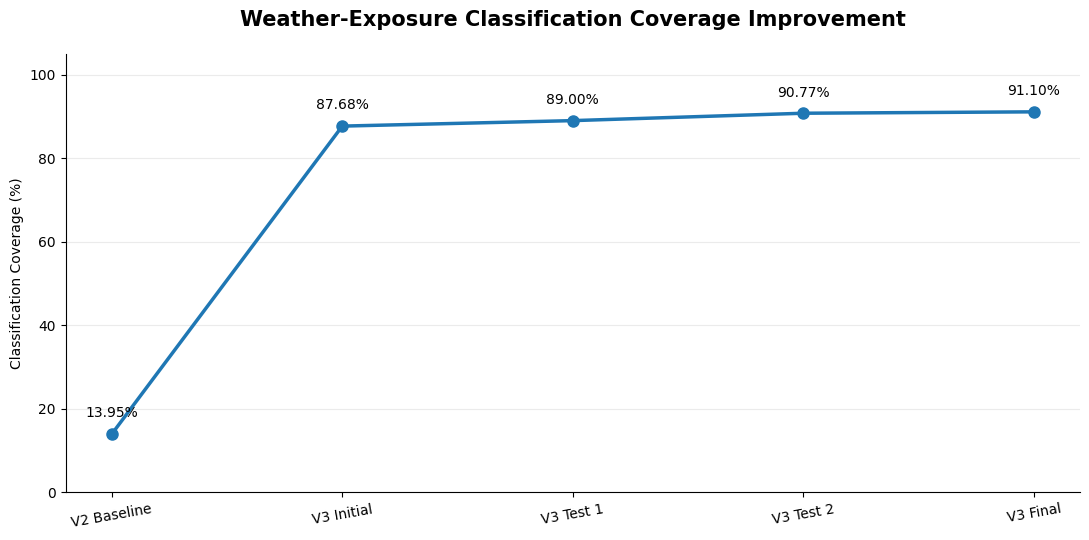


Coverage by version:
V2 Baseline: 13.95%
V3 Initial: 87.68%
V3 Test 1: 89.00%
V3 Test 2: 90.77%
V3 Final: 91.10%

Graph saved to: ../data/processed/weather_coverage_progress.png


In [99]:

import matplotlib.pyplot as plt
import pandas as pd

# Classification stages in development order.
stages = {
    "V2 Baseline": "weather_exposure_v2",
    "V3 Initial": "weather_exposure_v3",
    "V3 Test 1": "weather_exposure_v3_test",
    "V3 Test 2": "weather_exposure_v3_test2",
    "V3 Final": "weather_exposure_v3_test3"
}

# Confirm column names before plotting.
missing = [
    col for col in stages.values()
    if col not in activity_v3.columns
]

if missing:
    print("Missing columns:", missing)
    print("\nAvailable weather columns:")
    print([
        col for col in activity_v3.columns
        if "weather_exposure" in col
    ])
else:
    coverage = [
        (
            activity_v3[col].notna()
            & activity_v3[col].ne("unknown")
        ).mean() * 100
        for col in stages.values()
    ]

    fig, ax = plt.subplots(figsize=(11, 5.5))

    ax.plot(
        list(stages.keys()),
        coverage,
        marker="o",
        linewidth=2.5,
        markersize=8
    )

    for i, value in enumerate(coverage):
        ax.annotate(
            f"{value:.2f}%",
            (i, value),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

    ax.set_title(
        "Weather-Exposure Classification Coverage Improvement",
        fontsize=15,
        fontweight="bold",
        pad=20
    )

    ax.set_ylabel("Classification Coverage (%)")
    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

    plt.xticks(rotation=10)
    plt.tight_layout()

    # Save a high-resolution image for your presentation.
    graph_path = "../data/processed/weather_coverage_progress.png"
    plt.savefig(graph_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("\nCoverage by version:")
    for stage, value in zip(stages, coverage):
        print(f"{stage}: {value:.2f}%")

    print("\nGraph saved to:", graph_path)


### Weather Suitability Scoring Using Final V3 Classifications

The Version 3 weather-exposure classification is complete, with 91.10% classification coverage across 86,354 activities.

The next stage adapts the previously developed weather suitability scoring approach to the final Version 3 exposure labels: indoor, outdoor, mixed, and unknown.

The existing precipitation and temperature scoring logic will be preserved where appropriate. The mixed category will require explicit treatment, and the updated scoring function will be tested against representative weather scenarios before integration into the recommendation ranking.

In [100]:

# Inspect existing weather-related functions and variables.
weather_objects = [
    name for name in globals()
    if any(
        keyword in name.lower()
        for keyword in [
            "weather",
            "suitability",
            "temperature",
            "precipitation",
            "context_score"
        ]
    )
    and not name.startswith("_")
]

print("Existing weather-related objects:")
for name in sorted(weather_objects):
    obj = globals()[name]
    print(f"{name}: {type(obj).__name__}")

print("\nFinal classification column available:")
print("weather_exposure_final" in activity_v3.columns)

print("\nFinal exposure labels:")
print(activity_v3["weather_exposure_final"].value_counts())


Existing weather-related objects:
WEATHER_EXPOSURE_LABELS: set
api_temperature: float
api_weather_condition: str
brooklyn_weather: dict
calculate_combined_weather_score: function
calculate_temperature_factor: function
calculate_weather_score: function
classify_weather_exposure: function
classify_weather_exposure_v2: function
classify_weather_exposure_v3: function
generate_context_scores: function
generate_location_context_scores: function
get_weather_for_location: function
live_temperature: float
live_weather: str
location_weather: dict
manual_weather: dict
map_openweather_condition: function
mapped_weather_condition: str
scenario_temperature: int
scenario_weather: str
temperature: int
test_weather: dict
weather_data: dict
weather_scenario_df: DataFrame
weather_scenarios: list
weather_score_rules: dict
weather_scores: Series
weather_validation: DataFrame
weather_validation_summary: DataFrame
weather_weight: float

Final classification column available:
True

Final exposure labels:
weat

### Review of Existing Weather Suitability Scoring Functions

The original weather suitability functions are available in the current notebook session.

Before adapting the scoring system to the final Version 3 exposure classifications, the existing precipitation rules, temperature adjustments, and combined weather-scoring logic are inspected.

This ensures that previously implemented behavior is preserved where appropriate and that changes for the mixed exposure category are introduced explicitly rather than unintentionally altering established scoring rules.

In [101]:

import inspect
from pprint import pprint

functions_to_review = [
    calculate_weather_score,
    calculate_temperature_factor,
    calculate_combined_weather_score
]

for func in functions_to_review:
    print("\n" + "=" * 65)
    print("FUNCTION:", func.__name__)
    print("=" * 65)

    try:
        print(inspect.getsource(func))
    except (OSError, TypeError):
        print("Source unavailable in current session.")

print("\n" + "=" * 65)
print("EXISTING WEATHER SCORE RULES")
print("=" * 65)

pprint(weather_score_rules)



FUNCTION: calculate_weather_score
def calculate_weather_score(exposure, weather_condition):
    if weather_condition not in weather_score_rules:
        raise ValueError(
            f"Unsupported weather condition: {weather_condition}"
        )

    return weather_score_rules[weather_condition].get(
        exposure, 0.7
    )


FUNCTION: calculate_temperature_factor
def calculate_temperature_factor(temperature_c):
    if temperature_c < 0:
        return 0.2
    elif temperature_c < 10:
        return 0.5
    elif temperature_c < 30:
        return 1.0
    elif temperature_c < 35:
        return 0.6
    else:
        return 0.2


FUNCTION: calculate_combined_weather_score
def calculate_combined_weather_score(
    exposure,
    weather_condition,
    temperature_c
):
    precipitation_score = calculate_weather_score(
        exposure,
        weather_condition
    )

    if exposure == "outdoor":
        temperature_factor = calculate_temperature_factor(
            temperature_c
  

### Extending Weather Suitability Scoring to Mixed-Exposure Activities

The existing weather suitability system assigns precipitation-based scores to indoor, outdoor, and unknown activities, with additional temperature adjustments for outdoor activities.

Version 3 introduces a mixed-exposure category representing activities with meaningful indoor and outdoor options. To accommodate this category, heuristic suitability scores of 0.95 under clear conditions and 0.80 under rainy conditions are proposed.

These scores reflect the flexibility of mixed-exposure venues while acknowledging that weather may still restrict some activities. Existing scores for indoor, outdoor, and unknown activities remain unchanged.

The mixed-exposure scores are initial design assumptions and will be examined through scenario-based testing rather than treated as empirically validated parameters.

In [102]:

# Preserve the existing scoring rules.
weather_score_rules_v3 = {
    condition: scores.copy()
    for condition, scores in weather_score_rules.items()
}

# Add explicit mixed-exposure suitability scores.
weather_score_rules_v3["clear"]["mixed"] = 0.95
weather_score_rules_v3["rain"]["mixed"] = 0.80

# Define V3 scoring functions without overwriting
# the original implementations.
def calculate_weather_score_v3(exposure, weather_condition):
    if weather_condition not in weather_score_rules_v3:
        raise ValueError(
            f"Unsupported weather condition: {weather_condition}"
        )

    if exposure not in {
        "indoor", "outdoor", "mixed", "unknown"
    }:
        raise ValueError(
            f"Unsupported exposure label: {exposure}"
        )

    return weather_score_rules_v3[
        weather_condition
    ][exposure]


def calculate_combined_weather_score_v3(
    exposure,
    weather_condition,
    temperature_c
):
    precipitation_score = calculate_weather_score_v3(
        exposure, weather_condition
    )

    if exposure == "outdoor":
        return round(
            precipitation_score
            * calculate_temperature_factor(temperature_c),
            3
        )

    return precipitation_score


# Inspect the updated rules.
print("V3 weather suitability rules:")

for condition, scores in weather_score_rules_v3.items():
    print(f"\n{condition.upper()}:")
    for exposure, score in scores.items():
        print(f"  {exposure}: {score}")


V3 weather suitability rules:

CLEAR:
  outdoor: 1.0
  indoor: 0.9
  unknown: 0.7
  mixed: 0.95

RAIN:
  outdoor: 0.2
  indoor: 1.0
  unknown: 0.7
  mixed: 0.8


### Scenario-Based Testing of Version 3 Weather Suitability Scores

The updated Version 3 weather suitability function is evaluated using four representative weather scenarios: clear and mild, rainy and mild, clear and cold, and clear and hot.

The tests examine whether outdoor activities are penalized under rain and extreme temperatures, indoor activities remain relatively stable, and mixed-exposure activities retain intermediate suitability.

The scenarios are synthetic and are intended to verify the behavior of the rule-based scoring function rather than establish empirical predictive accuracy.

In [103]:

import pandas as pd

v3_weather_scenarios = [
    ("Clear, mild", "clear", 20),
    ("Rainy, mild", "rain", 20),
    ("Clear, cold", "clear", 5),
    ("Clear, hot", "clear", 36)
]

v3_exposure_labels = [
    "indoor", "outdoor", "mixed", "unknown"
]

scenario_results = []

for scenario_name, condition, temperature_c in v3_weather_scenarios:
    for exposure in v3_exposure_labels:
        score = calculate_combined_weather_score_v3(
            exposure,
            condition,
            temperature_c
        )

        scenario_results.append({
            "scenario": scenario_name,
            "weather_condition": condition,
            "temperature_c": temperature_c,
            "exposure": exposure,
            "suitability_score": score
        })

v3_scenario_results = pd.DataFrame(scenario_results)

v3_scenario_table = v3_scenario_results.pivot(
    index="scenario",
    columns="exposure",
    values="suitability_score"
).reindex(
    index=[s[0] for s in v3_weather_scenarios],
    columns=v3_exposure_labels
)

display(v3_scenario_table)

# Verify expected behavior.
assert (
    v3_scenario_table.loc["Rainy, mild", "outdoor"]
    < v3_scenario_table.loc["Clear, mild", "outdoor"]
)

assert (
    v3_scenario_table.loc["Clear, cold", "outdoor"]
    < v3_scenario_table.loc["Clear, mild", "outdoor"]
)

assert (
    v3_scenario_table.loc["Clear, hot", "outdoor"]
    < v3_scenario_table.loc["Clear, mild", "outdoor"]
)

assert (
    v3_scenario_table.loc["Rainy, mild", "mixed"]
    > v3_scenario_table.loc["Rainy, mild", "outdoor"]
)

print("All V3 weather suitability scenario checks passed.")


exposure,indoor,outdoor,mixed,unknown
scenario,,,,
"Clear, mild",0.9,1.0,0.95,0.7
"Rainy, mild",1.0,0.2,0.80,0.7
"Clear, cold",0.9,0.5,0.95,0.7
"Clear, hot",0.9,0.2,0.95,0.7


All V3 weather suitability scenario checks passed.


### Dataset-Wide Weather Suitability Scoring

The Version 3 weather suitability function passed the initial scenario-based checks for indoor, outdoor, mixed, and unknown activities.

The scoring function is now applied to all classified activities under four synthetic weather scenarios: clear and mild, rainy and mild, clear and cold, and clear and hot.

These scenario-specific scores demonstrate how weather conditions influence activity suitability across the dataset. They are separate from live-weather scores and do not yet incorporate user preferences, operating hours, or recommendation-model predictions.

In [104]:

# Create a separate dataframe for scenario-based scoring.
activity_weather_v3 = activity_v3[
    ["gmap_id", "name", "weather_exposure_final"]
].copy()

# Calculate weather suitability for each scenario.
scenario_columns = {}

for scenario_name, condition, temperature_c in v3_weather_scenarios:
    column_name = (
        "weather_score_"
        + scenario_name.lower().replace(", ", "_").replace(" ", "_")
    )

    activity_weather_v3[column_name] = (
        activity_weather_v3["weather_exposure_final"].apply(
            lambda exposure: calculate_combined_weather_score_v3(
                exposure,
                condition,
                temperature_c
            )
        )
    )

    scenario_columns[scenario_name] = column_name

# Check the resulting scores.
print("Activities scored:", len(activity_weather_v3))

print("\nWeather suitability columns:")
print(list(scenario_columns.values()))

print("\nAverage suitability by exposure:")
display(
    activity_weather_v3.groupby("weather_exposure_final")[
        list(scenario_columns.values())
    ].mean().round(3)
)

print("\nOverall average suitability by scenario:")
display(
    activity_weather_v3[
        list(scenario_columns.values())
    ].mean().round(3)
)

# Verify every activity received a valid score.
assert len(activity_weather_v3) == 86354

assert activity_weather_v3[
    list(scenario_columns.values())
].notna().all().all()

assert activity_weather_v3[
    list(scenario_columns.values())
].between(0, 1).all().all()

print("\nAll activities scored successfully.")


Activities scored: 86354

Weather suitability columns:
['weather_score_clear_mild', 'weather_score_rainy_mild', 'weather_score_clear_cold', 'weather_score_clear_hot']

Average suitability by exposure:


,weather_score_clear_mild,weather_score_rainy_mild,weather_score_clear_cold,weather_score_clear_hot
weather_exposure_final,,,,
indoor,0.90,1.0,0.90,0.90
mixed,0.95,0.8,0.95,0.95
outdoor,1.00,0.2,0.50,0.20
unknown,0.70,0.7,0.70,0.70



Overall average suitability by scenario:


weather_score_clear_mild    0.893
weather_score_rainy_mild    0.892
weather_score_clear_cold    0.844
weather_score_clear_hot     0.814
dtype: float64

AttributeError: 'DataFrame' object has no attribute 'between'

### Validation of Dataset-Wide Weather Suitability Scores

Weather suitability scores were generated for 86,354 activities across four synthetic weather scenarios.

The final validation checks that all activities received non-missing numeric scores within the expected range of 0 to 1.

This step corrects a pandas DataFrame validation method error without modifying the previously calculated suitability scores.

In [105]:

# Select the four scenario score columns.
score_columns = list(scenario_columns.values())

scores_to_check = activity_weather_v3[score_columns]

# Confirm the number of activities and unique IDs.
assert len(activity_weather_v3) == 86354
assert activity_weather_v3["gmap_id"].is_unique

# Confirm no missing scores.
assert scores_to_check.notna().all().all()

# Confirm every score is between 0 and 1.
assert (
    (scores_to_check >= 0)
    & (scores_to_check <= 1)
).all().all()

print("All dataset-wide weather suitability checks passed.")
print("Activities validated:", len(activity_weather_v3))
print("Weather scenarios:", len(score_columns))
print("Total suitability scores:", scores_to_check.size)

print("\nScore ranges:")
display(
    scores_to_check.agg(["min", "max"]).round(3)
)


All dataset-wide weather suitability checks passed.
Activities validated: 86354
Weather scenarios: 4
Total suitability scores: 345416

Score ranges:


,weather_score_clear_mild,weather_score_rainy_mild,weather_score_clear_cold,weather_score_clear_hot
min,0.7,0.2,0.50,0.20
max,1.0,1.0,0.95,0.95


### Review of Existing Weather and Time Context Integration

Version 3 weather suitability scores have been successfully calculated and validated for all 86,354 activities across four representative weather scenarios.

The next stage examines the existing weather and time context integration to determine how the updated suitability scores can replace the earlier weather scores without changing the established time suitability logic.

The review focuses on the combined context score, operating-hours eligibility, and any dependencies on the previous weather-exposure classification.

In [106]:

import inspect

functions_to_inspect = [
    generate_context_scores,
    generate_location_context_scores
]

for func in functions_to_inspect:
    print("\n" + "=" * 70)
    print("FUNCTION:", func.__name__)
    print("=" * 70)

    try:
        print(inspect.getsource(func))
    except (OSError, TypeError):
        print("Source unavailable in current session.")

print("\n" + "=" * 70)
print("EXISTING CONTEXT WEIGHTS")
print("=" * 70)

for variable in ["weather_weight", "time_weight"]:
    if variable in globals():
        print(f"{variable}: {globals()[variable]}")
    else:
        print(f"{variable}: not defined")



FUNCTION: generate_context_scores
def generate_context_scores(
    activities,
    weather_condition,
    temperature_c,
    day,
    hour,
    minute=0
):
    # Work on a separate DataFrame
    result = activities[
        [
            "gmap_id",
            "name",
            "latitude",
            "longitude",
            "weather_exposure_v2",
            "parsed_hours"
        ]
    ].drop_duplicates(subset="gmap_id").copy()

    # Calculate weather suitability
    result["weather_score"] = (
        result["weather_exposure_v2"].apply(
            lambda exposure: calculate_combined_weather_score(
                exposure,
                weather_condition,
                temperature_c
            )
        )
    )

    # Determine operating-hour availability
    result["time_availability"] = (
        result["parsed_hours"].apply(
            lambda hours: check_activity_availability(
                hours, day, hour, minute
            )
        )
    )

    # Convert avai

### Integration of Version 3 Weather Suitability with Time Context

The existing context-scoring system combines weather suitability and time suitability using equal weights:

\[
C_{WT} = 0.5W + 0.5T
\]

Version 3 retains this weighting scheme and the existing operating-hours availability rules.

The integration updates the weather-exposure input from `weather_exposure_v2` to `weather_exposure_final` and uses the new `calculate_combined_weather_score_v3()` function.

Confirmed-closed activities remain ineligible for recommendation. The original context-scoring function is preserved to support comparisons between versions.

In [107]:

def generate_context_scores_v3(
    activities,
    weather_condition,
    temperature_c,
    day,
    hour,
    minute=0
):
    # Work on a separate DataFrame using V3 exposure labels.
    result = activities[
        [
            "gmap_id",
            "name",
            "latitude",
            "longitude",
            "weather_exposure_final",
            "parsed_hours"
        ]
    ].drop_duplicates(subset="gmap_id").copy()

    # Calculate V3 weather suitability.
    result["weather_score"] = (
        result["weather_exposure_final"].apply(
            lambda exposure: calculate_combined_weather_score_v3(
                exposure,
                weather_condition,
                temperature_c
            )
        )
    )

    # Preserve existing operating-hours logic.
    result["time_availability"] = (
        result["parsed_hours"].apply(
            lambda hours: check_activity_availability(
                hours, day, hour, minute
            )
        )
    )

    result["time_score"] = (
        result["time_availability"].map(time_score_rules)
    )

    # Preserve existing 50/50 context weighting.
    result["context_score"] = (
        0.5 * result["weather_score"]
        + 0.5 * result["time_score"]
    )

    # Exclude confirmed-closed activities.
    result["context_eligible"] = (
        result["time_availability"] != "closed"
    )

    return result.reset_index(drop=True)


print("V3 context-scoring function defined successfully.")
print("Original function preserved:",
      callable(generate_context_scores))
print("V3 function available:",
      callable(generate_context_scores_v3))


V3 context-scoring function defined successfully.
Original function preserved: True
V3 function available: True


### Validation of Integrated Weather and Time Context Scoring

The Version 3 context-scoring function is evaluated using a controlled scenario with rainy weather, a temperature of 20°C, and a Wednesday observation time of 2:00 PM.

The test verifies that the updated weather-exposure classifications are used, the existing operating-hours rules remain functional, and the combined context score retains the original equal weighting of weather and time suitability.

Activities classified as closed must remain ineligible for recommendation, regardless of their combined context scores.

In [108]:

# Generate V3 context scores for a controlled scenario.
context_scores_v3_test = generate_context_scores_v3(
    activities=activity_v3,
    weather_condition="rain",
    temperature_c=20,
    day="Wednesday",
    hour=14,
    minute=0
)

print("Activities scored:", len(context_scores_v3_test))

print("\nTime availability distribution:")
print(
    context_scores_v3_test[
        "time_availability"
    ].value_counts(dropna=False)
)

print("\nContext eligibility distribution:")
print(
    context_scores_v3_test[
        "context_eligible"
    ].value_counts(dropna=False)
)

print("\nAverage scores by weather exposure:")
display(
    context_scores_v3_test.groupby(
        "weather_exposure_final"
    )[["weather_score", "time_score", "context_score"]]
    .mean()
    .round(3)
)

# Validate the integrated scoring.
assert len(context_scores_v3_test) == 86354

assert context_scores_v3_test["gmap_id"].is_unique

assert context_scores_v3_test[
    ["weather_score", "time_score", "context_score"]
].notna().all().all()

assert (
    (
        context_scores_v3_test["context_score"]
        - (
            0.5 * context_scores_v3_test["weather_score"]
            + 0.5 * context_scores_v3_test["time_score"]
        )
    ).abs() < 1e-9
).all()

assert (
    ~context_scores_v3_test.loc[
        context_scores_v3_test["time_availability"] == "closed",
        "context_eligible"
    ]
).all()

print("\nAll V3 integrated context-scoring checks passed.")


Activities scored: 86354

Time availability distribution:
time_availability
open       61545
unknown    12487
closed     12322
Name: count, dtype: int64

Context eligibility distribution:
context_eligible
True     74032
False    12322
Name: count, dtype: int64

Average scores by weather exposure:


,weather_score,time_score,context_score
weather_exposure_final,,,
indoor,1.0,0.812,0.906
mixed,0.8,0.601,0.700
outdoor,0.2,0.705,0.452
unknown,0.7,0.661,0.680



All V3 integrated context-scoring checks passed.


### Integration of Version 3 Context Scoring with Live Weather Data

The Version 3 weather and time context-scoring function passed the dataset-wide integration checks.

The existing OpenWeatherMap integration is retained to obtain location-specific weather conditions and temperatures. The observation timestamp is converted to New York local time for operating-hours evaluation.

A Version 3 wrapper is introduced to connect live weather observations to the updated context-scoring function while preserving the original implementation.

The wrapper is defined separately and will be tested without requiring an immediate API request.

In [109]:

def generate_location_context_scores_v3(
    activities,
    latitude,
    longitude,
    api_key
):
    # Retrieve weather using the existing API integration.
    weather_info = get_weather_for_location(
        latitude=latitude,
        longitude=longitude,
        api_key=api_key
    )

    # Preserve the existing New York time conversion.
    local_time = datetime.fromtimestamp(
        weather_info["observation_timestamp"],
        tz=ZoneInfo("America/New_York")
    )

    # Use the updated V3 context-scoring function.
    scores = generate_context_scores_v3(
        activities=activities,
        weather_condition=weather_info["weather_condition"],
        temperature_c=weather_info["temperature_c"],
        day=local_time.strftime("%A"),
        hour=local_time.hour,
        minute=local_time.minute
    )

    return weather_info, scores


print("V3 live-weather context function defined successfully.")

print(
    "Original live-weather function preserved:",
    callable(generate_location_context_scores)
)

print(
    "V3 live-weather function available:",
    callable(generate_location_context_scores_v3)
)


V3 live-weather context function defined successfully.
Original live-weather function preserved: True
V3 live-weather function available: True


### Mock Testing of the Version 3 Live-Weather Integration

The Version 3 location-based context-scoring wrapper is tested using a simulated OpenWeatherMap observation.

The test replaces the weather-retrieval function temporarily with a controlled observation representing rainy conditions at 20°C on a Wednesday at 2:00 PM in New York.

The generated context scores are compared against the previously validated scenario-based results. This verifies integration consistency without requiring an external API request.

The original weather-retrieval function is restored after the test. Successful mock testing does not establish that the external API is currently available or functioning.

In [110]:

from datetime import datetime
from zoneinfo import ZoneInfo

# Create a controlled local observation timestamp.
mock_local_time = datetime(
    2026, 11, 11, 14, 0,
    tzinfo=ZoneInfo("America/New_York")
)

mock_weather_info = {
    "weather_condition": "rain",
    "temperature_c": 20,
    "observation_timestamp": int(mock_local_time.timestamp())
}

# Preserve the real API function.
original_weather_fetcher = get_weather_for_location

def mock_get_weather_for_location(latitude, longitude, api_key):
    return mock_weather_info.copy()

try:
    # Temporarily replace the API call.
    get_weather_for_location = mock_get_weather_for_location

    mock_weather_result, mock_context_scores = (
        generate_location_context_scores_v3(
            activities=activity_v3,
            latitude=40.7,
            longitude=-73.9,
            api_key="MOCK_KEY"
        )
    )

finally:
    # Always restore the real API function.
    get_weather_for_location = original_weather_fetcher

# Compare mock results with Step 72.
assert len(mock_context_scores) == 86354

comparison = mock_context_scores[
    ["gmap_id", "weather_score", "time_score",
     "context_score", "context_eligible"]
].merge(
    context_scores_v3_test[
        ["gmap_id", "weather_score", "time_score",
         "context_score", "context_eligible"]
    ],
    on="gmap_id",
    suffixes=("_mock", "_reference"),
    validate="one_to_one"
)

for column in ["weather_score", "time_score", "context_score"]:
    assert (
        comparison[f"{column}_mock"]
        - comparison[f"{column}_reference"]
    ).abs().lt(1e-9).all()

assert (
    comparison["context_eligible_mock"]
    == comparison["context_eligible_reference"]
).all()

print("Mock weather observation:", mock_weather_result)
print("Activities scored:", len(mock_context_scores))
print("Activities compared:", len(comparison))
print(
    "Eligible activities:",
    int(mock_context_scores["context_eligible"].sum())
)
print(
    "Original API function restored:",
    get_weather_for_location is original_weather_fetcher
)
print("\nAll V3 live-weather mock integration checks passed.")


Mock weather observation: {'weather_condition': 'rain', 'temperature_c': 20, 'observation_timestamp': 1794423600}
Activities scored: 86354
Activities compared: 86354
Eligible activities: 74032
Original API function restored: True

All V3 live-weather mock integration checks passed.


### Preparation for Live OpenWeatherMap Integration Testing

The Version 3 live-weather integration passed the controlled mock test, producing context scores consistent with the previously validated results for all 86,354 activities.

The next stage verifies the integration using an actual OpenWeatherMap observation.

Before requesting live weather data, the notebook environment is inspected for existing API credentials and location variables. Credential values are not displayed.

Successful live testing will confirm that the weather retrieval, timestamp conversion, weather suitability calculation, time suitability calculation, and eligibility filtering operate together using an external weather observation.

In [111]:

# Inspect existing variables without displaying secrets.
import os

possible_api_key_names = [
    "OPENWEATHER_API_KEY",
    "OPENWEATHERMAP_API_KEY",
    "openweather_api_key",
    "openweathermap_api_key",
    "api_key",
    "weather_api_key"
]

possible_location_names = [
    "user_latitude",
    "user_longitude",
    "latitude",
    "longitude",
    "lat",
    "lon"
]

print("API key variables:")
for name in possible_api_key_names:
    if name in globals():
        value = globals()[name]
        print(f"  {name}: defined, nonempty={bool(value)}")
    elif os.getenv(name):
        print(f"  {name}: available in environment")

print("\nLocation variables:")
for name in possible_location_names:
    if name in globals():
        value = globals()[name]
        if isinstance(value, (int, float)):
            print(f"  {name}: numeric value available")
        else:
            print(f"  {name}: defined ({type(value).__name__})")

print("\nLive-weather function ready:",
      callable(generate_location_context_scores_v3))


API key variables:
  api_key: defined, nonempty=True

Location variables:
  latitude: numeric value available
  longitude: numeric value available

Live-weather function ready: True


### Live OpenWeatherMap Testing of the Version 3 Context-Scoring Pipeline

The Version 3 context-scoring pipeline is tested using an actual weather observation retrieved from OpenWeatherMap.

The existing API credentials and location coordinates are reused without displaying sensitive information.

The test evaluates the complete workflow, including weather retrieval, local-time conversion, weather suitability scoring, operating-hours evaluation, combined context scoring, and recommendation eligibility.

The resulting scores are checked for completeness, valid ranges, and consistency with the established 50/50 weighting scheme.

In [112]:

# Retrieve live weather and calculate V3 context scores.
live_weather_v3, live_context_scores_v3 = (
    generate_location_context_scores_v3(
        activities=activity_v3,
        latitude=latitude,
        longitude=longitude,
        api_key=api_key
    )
)

# Display non-sensitive weather information.
print("LIVE WEATHER OBSERVATION")
print("Weather condition:", live_weather_v3["weather_condition"])
print("Temperature (°C):", live_weather_v3["temperature_c"])

observation_local_time = datetime.fromtimestamp(
    live_weather_v3["observation_timestamp"],
    tz=ZoneInfo("America/New_York")
)

print("Observation time (New York):", observation_local_time)

print("\nACTIVITY SCORING")
print("Activities scored:", len(live_context_scores_v3))

print("\nTime availability:")
print(
    live_context_scores_v3["time_availability"]
    .value_counts(dropna=False)
)

print("\nRecommendation eligibility:")
print(
    live_context_scores_v3["context_eligible"]
    .value_counts(dropna=False)
)

print("\nAverage scores by exposure:")
display(
    live_context_scores_v3.groupby("weather_exposure_final")[
        ["weather_score", "time_score", "context_score"]
    ].mean().round(3)
)

# Validate the live scoring results.
assert len(live_context_scores_v3) == 86354
assert live_context_scores_v3["gmap_id"].is_unique

score_cols = ["weather_score", "time_score", "context_score"]

assert live_context_scores_v3[score_cols].notna().all().all()

assert (
    (live_context_scores_v3[score_cols] >= 0)
    & (live_context_scores_v3[score_cols] <= 1)
).all().all()

assert (
    (
        live_context_scores_v3["context_score"]
        - (
            0.5 * live_context_scores_v3["weather_score"]
            + 0.5 * live_context_scores_v3["time_score"]
        )
    ).abs() < 1e-9
).all()

assert (
    ~live_context_scores_v3.loc[
        live_context_scores_v3["time_availability"] == "closed",
        "context_eligible"
    ]
).all()

print("\nAll live V3 context-scoring checks passed.")


LIVE WEATHER OBSERVATION
Weather condition: clear
Temperature (°C): 11.53
Observation time (New York): 2026-11-17 19:38:23-05:00

ACTIVITY SCORING
Activities scored: 86354

Time availability:
time_availability
open       51741
closed     22126
unknown    12487
Name: count, dtype: int64

Recommendation eligibility:
context_eligible
True     64228
False    22126
Name: count, dtype: int64

Average scores by exposure:


,weather_score,time_score,context_score
weather_exposure_final,,,
indoor,0.90,0.698,0.799
mixed,0.95,0.760,0.855
outdoor,1.00,0.588,0.794
unknown,0.70,0.512,0.606



All live V3 context-scoring checks passed.


### Export and Verification of Version 3 Live Context Scores

The Version 3 context-scoring pipeline successfully processed 86,354 activities using a real OpenWeatherMap observation.

The resulting dataset includes weather suitability, time suitability, combined context scores, and recommendation eligibility.

The live scoring results are exported as a timestamped snapshot to preserve the weather and observation time associated with the scores. The exported file is then reloaded and validated to ensure that all activities and scoring fields have been preserved.

These scores represent the observed weather and time context at the moment of retrieval and should be recalculated for future recommendation requests.

In [113]:

from pathlib import Path
import pandas as pd

# Create the output directory if needed.
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Build a timestamped filename.
observation_stamp = observation_local_time.strftime(
    "%Y%m%d_%H%M%S"
)

output_path = output_dir / (
    f"activities_context_scores_v3_{observation_stamp}.csv"
)

# Preserve observation metadata in the exported snapshot.
live_context_export_v3 = live_context_scores_v3.copy()

live_context_export_v3["weather_condition"] = (
    live_weather_v3["weather_condition"]
)

live_context_export_v3["temperature_c"] = (
    live_weather_v3["temperature_c"]
)

live_context_export_v3["observation_time_ny"] = (
    observation_local_time.isoformat()
)

# Export the complete scoring snapshot.
live_context_export_v3.to_csv(
    output_path,
    index=False
)

# Reload and validate the exported file.
verified_context_v3 = pd.read_csv(
    output_path,
    low_memory=False
)

assert len(verified_context_v3) == 86354
assert verified_context_v3["gmap_id"].is_unique

required_columns = [
    "weather_exposure_final",
    "weather_score",
    "time_availability",
    "time_score",
    "context_score",
    "context_eligible",
    "weather_condition",
    "temperature_c",
    "observation_time_ny"
]

assert set(required_columns).issubset(
    verified_context_v3.columns
)

assert verified_context_v3[
    ["weather_score", "time_score", "context_score"]
].notna().all().all()

assert (
    verified_context_v3["context_eligible"]
    .astype(str).str.lower().eq("true").sum()
    == int(live_context_scores_v3["context_eligible"].sum())
)

print("Export successful:", output_path)
print("File size (MB):", round(
    output_path.stat().st_size / (1024 ** 2), 2
))
print("Verified activities:", len(verified_context_v3))
print("Verified eligible activities:",
      int(live_context_scores_v3["context_eligible"].sum()))
print("Observation:", observation_local_time.isoformat())
print("\nV3 live-context export verification passed.")


Export successful: ../data/processed/activities_context_scores_v3_20261117_193823.csv
File size (MB): 25.07
Verified activities: 86354
Verified eligible activities: 64228
Observation: 2026-11-17T19:38:23-05:00

V3 live-context export verification passed.


### Comparison of Version 2 and Version 3 Weather-Context Scoring

The completed Version 3 weather-context pipeline is compared against the original Version 2 implementation under identical simulated conditions.

Both versions use rainy weather at 20°C on Wednesday at 2:00 PM. The comparison measures changes in weather suitability, combined context scores, and recommendation eligibility.

This analysis assesses the effect of the updated exposure classification and scoring rules. It does not measure recommendation accuracy or establish that the Version 3 scores are empirically superior.

In [114]:

# Generate original V2 scores under identical conditions.
context_scores_v2_comparison = generate_context_scores(
    activities=activity_v3,
    weather_condition="rain",
    temperature_c=20,
    day="Wednesday",
    hour=14,
    minute=0
)

# Reuse the previously validated V3 scenario.
v3_comparison = context_scores_v3_test.copy()

comparison_v2_v3 = context_scores_v2_comparison[
    ["gmap_id", "weather_score", "time_score",
     "context_score", "context_eligible"]
].merge(
    v3_comparison[
        ["gmap_id", "weather_score", "time_score",
         "context_score", "context_eligible"]
    ],
    on="gmap_id",
    suffixes=("_v2", "_v3"),
    validate="one_to_one"
)

comparison_v2_v3["weather_score_change"] = (
    comparison_v2_v3["weather_score_v3"]
    - comparison_v2_v3["weather_score_v2"]
)

comparison_v2_v3["context_score_change"] = (
    comparison_v2_v3["context_score_v3"]
    - comparison_v2_v3["context_score_v2"]
)

# Check that time scoring and eligibility remain unchanged.
assert len(comparison_v2_v3) == 86354

assert (
    comparison_v2_v3["time_score_v2"]
    == comparison_v2_v3["time_score_v3"]
).all()

assert (
    comparison_v2_v3["context_eligible_v2"]
    == comparison_v2_v3["context_eligible_v3"]
).all()

print("Activities compared:", len(comparison_v2_v3))

print("\nMean weather suitability:")
print(
    comparison_v2_v3[
        ["weather_score_v2", "weather_score_v3"]
    ].mean().round(3)
)

print("\nMean combined context suitability:")
print(
    comparison_v2_v3[
        ["context_score_v2", "context_score_v3"]
    ].mean().round(3)
)

print("\nActivities with changed weather scores:")
print(
    int(
        comparison_v2_v3["weather_score_change"]
        .abs().gt(1e-9).sum()
    )
)

print("\nWeather score change distribution:")
print(
    comparison_v2_v3["weather_score_change"]
    .round(3).value_counts().sort_index()
)

print("\nTime scores and eligibility unchanged: True")
print("V2 versus V3 comparison completed successfully.")


Activities compared: 86354

Mean weather suitability:
weather_score_v2    0.671
weather_score_v3    0.892
dtype: float64

Mean combined context suitability:
context_score_v2    0.728
context_score_v3    0.838
dtype: float64

Activities with changed weather scores:
66624

Weather score change distribution:
weather_score_change
-0.5      898
 0.0    19730
 0.1     1169
 0.3    64557
Name: count, dtype: int64

Time scores and eligibility unchanged: True
V2 versus V3 comparison completed successfully.


### Export of Version 2 and Version 3 Context-Scoring Comparison

The Version 2 and Version 3 context-scoring systems were compared across 86,354 activities under identical rainy-weather and time conditions.

Version 3 changed weather suitability scores for 66,624 activities (77.15%). Mean weather suitability increased from approximately 0.671 to 0.892, while mean combined context suitability increased from approximately 0.728 to 0.838.

Time suitability and recommendation eligibility remained unchanged, confirming that the observed differences arose from the updated weather-exposure classification and scoring rules.

These changes demonstrate the effect of the revised scoring system but do not establish improved recommendation accuracy or user satisfaction.

In [115]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

comparison_path = (
    output_dir / "weather_context_v2_v3_comparison.csv"
)

summary_path = (
    output_dir / "weather_context_v2_v3_summary.csv"
)

# Export activity-level comparisons.
comparison_v2_v3.to_csv(comparison_path, index=False)

# Create an aggregate comparison summary.
comparison_summary = pd.DataFrame({
    "metric": [
        "activities_compared",
        "activities_with_changed_weather_scores",
        "proportion_with_changed_weather_scores",
        "mean_weather_score_v2",
        "mean_weather_score_v3",
        "mean_context_score_v2",
        "mean_context_score_v3"
    ],
    "value": [
        len(comparison_v2_v3),
        comparison_v2_v3[
            "weather_score_change"
        ].abs().gt(1e-9).sum(),
        comparison_v2_v3[
            "weather_score_change"
        ].abs().gt(1e-9).mean(),
        comparison_v2_v3["weather_score_v2"].mean(),
        comparison_v2_v3["weather_score_v3"].mean(),
        comparison_v2_v3["context_score_v2"].mean(),
        comparison_v2_v3["context_score_v3"].mean()
    ]
})

comparison_summary.to_csv(summary_path, index=False)

# Verify both exports.
verified_comparison = pd.read_csv(comparison_path)
verified_summary = pd.read_csv(summary_path)

assert len(verified_comparison) == 86354
assert verified_comparison["gmap_id"].is_unique
assert len(verified_summary) == 7

print("Comparison export:", comparison_path)
print("Summary export:", summary_path)
print("Verified activities:", len(verified_comparison))
print("\nSummary:")
display(verified_summary.round(4))
print("\nV2–V3 comparison exports verified.")


Comparison export: ../data/processed/weather_context_v2_v3_comparison.csv
Summary export: ../data/processed/weather_context_v2_v3_summary.csv
Verified activities: 86354

Summary:


,metric,value
0,activities_compared,86354.0000
1,activities_with_changed_weather_scores,66624.0000
2,proportion_with_changed_weather_scores,0.7715
3,mean_weather_score_v2,0.6715
4,mean_weather_score_v3,0.8919
5,mean_context_score_v2,0.7282
6,mean_context_score_v3,0.8384



V2–V3 comparison exports verified.


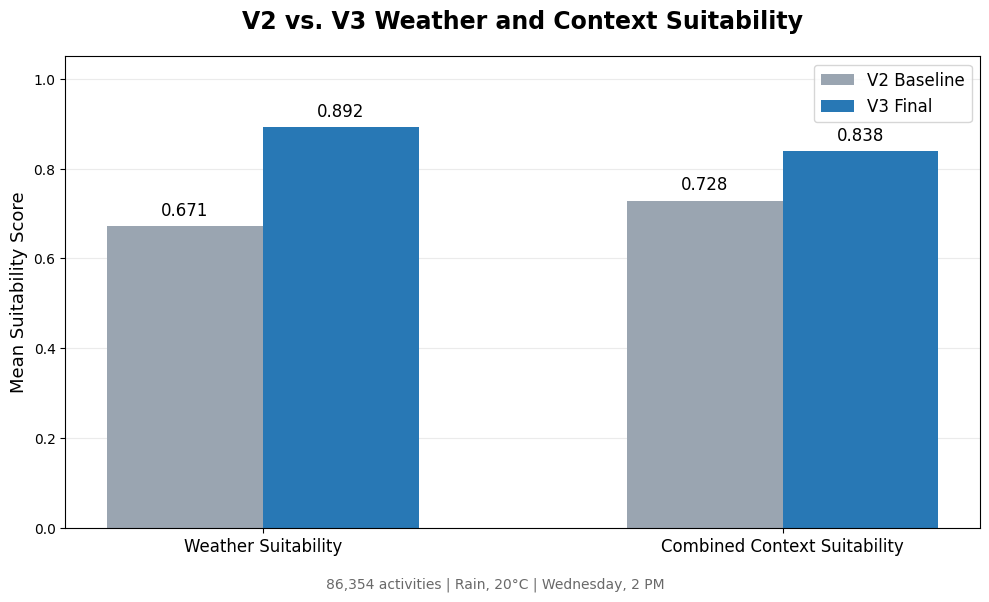

Chart saved to: ../data/processed/weather_context_v2_v3_comparison.png
File exists: True


In [116]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Use the actual V2 and V3 comparison results.
metrics = [
    "Weather Suitability",
    "Combined Context Suitability"
]

v2_scores = [
    comparison_v2_v3["weather_score_v2"].mean(),
    comparison_v2_v3["context_score_v2"].mean()
]

v3_scores = [
    comparison_v2_v3["weather_score_v3"].mean(),
    comparison_v2_v3["context_score_v3"].mean()
]

x = np.arange(len(metrics))
width = 0.30

fig, ax = plt.subplots(figsize=(10, 6))

bars_v2 = ax.bar(
    x - width / 2,
    v2_scores,
    width,
    label="V2 Baseline",
    color="#9AA5B1"
)

bars_v3 = ax.bar(
    x + width / 2,
    v3_scores,
    width,
    label="V3 Final",
    color="#2878B5"
)

# Display score labels above each bar.
for bars in [bars_v2, bars_v3]:
    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=5,
        fontsize=12
    )

ax.set_title(
    "V2 vs. V3 Weather and Context Suitability",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Mean Suitability Score", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylim(0, 1.05)

ax.legend(fontsize=12)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    "86,354 activities | Rain, 20°C | Wednesday, 2 PM",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save a high-resolution image.
output_path = Path(
    "../data/processed/weather_context_v2_v3_comparison.png"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", output_path)
print("File exists:", output_path.exists())


# Weather/Time BPR Reranking Experiments

In [120]:

import pandas as pd

from pathlib import Path

bpr_path = Path.home() / "Downloads" / "shared_bpr_candidates.csv"

print("File exists:", bpr_path.exists())

bpr_candidates = pd.read_csv(
    bpr_path,
    dtype={"user_id": str, "gmap_id": str}
)

# Check the shared candidate dataset.
print("BPR candidate rows:", len(bpr_candidates))
print("Unique users:", bpr_candidates["user_id"].nunique())

print("\nCandidates per user:")
print(
    bpr_candidates.groupby("user_id")
    .size().describe()
)

# Match candidates against your V3 activity dataset.
activity_ids = set(
    activity_v3["gmap_id"].dropna().astype(str)
)

matched = bpr_candidates["gmap_id"].isin(activity_ids)

print("\nMatched candidate rows:", matched.sum())
print("Unmatched candidate rows:", (~matched).sum())
print("Match rate:", f"{matched.mean():.2%}")

print("\nUnique matched activities:")
print(
    bpr_candidates.loc[matched, "gmap_id"].nunique()
)


File exists: True
BPR candidate rows: 10000
Unique users: 50

Candidates per user:
count     50.0
mean     200.0
std        0.0
min      200.0
25%      200.0
50%      200.0
75%      200.0
max      200.0
dtype: float64

Matched candidate rows: 10000
Unmatched candidate rows: 0
Match rate: 100.00%

Unique matched activities:
5796


###  Load BPR candidates

In [121]:


bpr_candidates = pd.read_csv(
    bpr_path,
    dtype={"user_id": str, "gmap_id": str}
)

print("BPR candidate rows:", len(bpr_candidates))
print("Unique users:", bpr_candidates["user_id"].nunique())
print("Unique activities:", bpr_candidates["gmap_id"].nunique())

print("\nColumns:")
print(bpr_candidates.columns.tolist())

print("\nFirst five rows:")
display(bpr_candidates.head())


BPR candidate rows: 10000
Unique users: 50
Unique activities: 5796

Columns:
['user_id', 'gmap_id', 'bpr_rank', 'bpr_score', 'bpr_normalized']

First five rows:


,user_id,gmap_id,bpr_rank,bpr_score,bpr_normalized
0,100388958952721979686,0x89c2f3747f378f7d:0x61caa819e454f065,1,2.857783,1.000000
1,100388958952721979686,0x89c2f4e9f911e9d9:0x63082da1140b9e66,2,2.832877,0.937595
2,100388958952721979686,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,3,2.815485,0.894019
3,100388958952721979686,0x89c2f3926691fd75:0xae683d2e5147a9a8,4,2.800888,0.857444
4,100388958952721979686,0x89c28cba56f51c3d:0xe19c58eeca84032f,5,2.792721,0.836982


In [122]:

# Get activity IDs from your V3 dataset
v3_activity_ids = set(
    activity_v3["gmap_id"].dropna().astype(str)
)

# Check which BPR candidates match
matched = bpr_candidates["gmap_id"].isin(v3_activity_ids)

print("Total BPR candidates:", len(bpr_candidates))
print("Matched candidates:", matched.sum())
print("Unmatched candidates:", (~matched).sum())
print("Match rate:", f"{matched.mean():.2%}")

print("\nUnique matched activities:")
print(
    bpr_candidates.loc[matched, "gmap_id"].nunique()
)


Total BPR candidates: 10000
Matched candidates: 10000
Unmatched candidates: 0
Match rate: 100.00%

Unique matched activities:
5796


In [123]:

# Check available weather and time columns
context_columns = [
    col for col in activity_v3.columns
    if any(keyword in col.lower() for keyword in [
        "weather", "exposure", "time",
        "availability", "eligible", "context"
    ])
]

print("Available weather/time columns:")
for col in context_columns:
    print("-", col)

print("\nTotal V3 activities:", len(activity_v3))


Available weather/time columns:
- weather_exposure
- weather_exposure_v2
- weather_score_clear
- weather_score_rain
- time_availability
- time_score
- scenario_weather_score
- context_score
- context_eligible
- context_clear_comfortable
- context_rainy_cold
- weather_exposure_v3
- weather_exposure_v3_test
- weather_exposure_v3_test2
- weather_exposure_v3_test3
- weather_exposure_final

Total V3 activities: 86354


In [124]:

# Check the columns in the final weather and time scoring DataFrames

for name in ["activity_weather_v3", "activity_v3"]:
    df = globals().get(name)

    if df is not None:
        print(f"\n{name}:")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
    else:
        print(f"\n{name} is not defined")



activity_weather_v3:
Shape: (86354, 7)
Columns: ['gmap_id', 'name', 'weather_exposure_final', 'weather_score_clear_mild', 'weather_score_rainy_mild', 'weather_score_clear_cold', 'weather_score_clear_hot']

activity_v3:
Shape: (86354, 38)
Columns: ['name', 'address', 'gmap_id', 'description', 'latitude', 'longitude', 'category', 'avg_rating', 'num_of_reviews', 'price', 'hours', 'MISC', 'state', 'relative_results', 'url', 'is_activity', 'activity_groups', 'parsed_activity_groups', 'parsed_categories', 'weather_exposure', 'weather_exposure_v2', 'weather_score_clear', 'weather_score_rain', 'parsed_hours', 'time_availability', 'time_score', 'scenario_weather_score', 'context_score', 'context_eligible', 'context_clear_comfortable', 'context_rainy_cold', 'weather_exposure_v3', 'v3_rule', 'v3_confidence', 'weather_exposure_v3_test', 'weather_exposure_v3_test2', 'weather_exposure_v3_test3', 'weather_exposure_final']


In [125]:

# Attach final V3 weather scores to BPR candidates

weather_columns = [
    "gmap_id",
    "weather_exposure_final",
    "weather_score_clear_mild",
    "weather_score_rainy_mild",
    "weather_score_clear_cold",
    "weather_score_clear_hot"
]

bpr_weather = bpr_candidates.merge(
    activity_weather_v3[weather_columns],
    on="gmap_id",
    how="left",
    validate="many_to_one"
)

print("Rows after merging:", len(bpr_weather))

print("\nMissing weather scores:")
print(
    bpr_weather[
        weather_columns[2:]
    ].isna().sum()
)

print("\nFirst five rows:")
display(bpr_weather.head())


Rows after merging: 10000

Missing weather scores:
weather_score_clear_mild    0
weather_score_rainy_mild    0
weather_score_clear_cold    0
weather_score_clear_hot     0
dtype: int64

First five rows:


,user_id,gmap_id,bpr_rank,bpr_score,bpr_normalized,weather_exposure_final,weather_score_clear_mild,weather_score_rainy_mild,weather_score_clear_cold,weather_score_clear_hot
0,100388958952721979686,0x89c2f3747f378f7d:0x61caa819e454f065,1,2.857783,1.000000,outdoor,1.0,0.2,0.5,0.2
1,100388958952721979686,0x89c2f4e9f911e9d9:0x63082da1140b9e66,2,2.832877,0.937595,indoor,0.9,1.0,0.9,0.9
2,100388958952721979686,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,3,2.815485,0.894019,indoor,0.9,1.0,0.9,0.9
3,100388958952721979686,0x89c2f3926691fd75:0xae683d2e5147a9a8,4,2.800888,0.857444,indoor,0.9,1.0,0.9,0.9
4,100388958952721979686,0x89c28cba56f51c3d:0xe19c58eeca84032f,5,2.792721,0.836982,indoor,0.9,1.0,0.9,0.9


### Experiment 1: BPR vs. BPR + Weather.

In [127]:

# Experiment 1: BPR + Weather (rainy, mild scenario)

weather_weight = 0.30
bpr_weight = 0.70

bpr_weather["bpr_weather_score"] = (
    bpr_weight * bpr_weather["bpr_normalized"]
    + weather_weight * bpr_weather["weather_score_rainy_mild"]
)

# Rank activities separately for each user
bpr_weather["bpr_weather_rank"] = (
    bpr_weather.groupby("user_id")["bpr_weather_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Inspect one user's top 10 recommendations
example_user = bpr_weather["user_id"].iloc[0]

display(
    bpr_weather[
        bpr_weather["user_id"] == example_user
    ]
    .sort_values("bpr_weather_rank")
    [[
        "gmap_id",
        "weather_exposure_final",
        "bpr_rank",
        "bpr_normalized",
        "weather_score_rainy_mild",
        "bpr_weather_score",
        "bpr_weather_rank"
    ]]
    .head(10)
)


,gmap_id,weather_exposure_final,bpr_rank,bpr_normalized,weather_score_rainy_mild,bpr_weather_score,bpr_weather_rank
1,0x89c2f4e9f911e9d9:0x63082da1140b9e66,indoor,2,0.937595,1.0,0.956317,1
2,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,indoor,3,0.894019,1.0,0.925813,2
3,0x89c2f3926691fd75:0xae683d2e5147a9a8,indoor,4,0.857444,1.0,0.900211,3
4,0x89c28cba56f51c3d:0xe19c58eeca84032f,indoor,5,0.836982,1.0,0.885887,4
5,0x89c2f475382671b5:0xba3e30bc6b46ce72,indoor,6,0.738152,1.0,0.816706,5
6,0x89c2f48036d65f93:0xc5a253c27b0d884b,indoor,7,0.733548,1.0,0.813483,6
7,0x89c2f38f07a99cc1:0xa2b82e65b3b2a94b,indoor,8,0.706234,1.0,0.794363,7
9,0x89c2f396c9fea93b:0x4ce63bab0b0eaeb0,indoor,10,0.660372,1.0,0.762260,8
10,0x89c2f4b5ccf17095:0x543106b8d21b4908,indoor,11,0.660189,1.0,0.762132,9
0,0x89c2f3747f378f7d:0x61caa819e454f065,outdoor,1,1.000000,0.2,0.760000,10


In [128]:

# Compare average weather suitability in the top 10

original_top10 = bpr_weather[
    bpr_weather["bpr_rank"] <= 10
]

weather_top10 = bpr_weather[
    bpr_weather["bpr_weather_rank"] <= 10
]

original_avg = original_top10[
    "weather_score_rainy_mild"
].mean()

weather_avg = weather_top10[
    "weather_score_rainy_mild"
].mean()

print("Original BPR top-10 weather suitability:", round(original_avg, 4))
print("BPR + Weather top-10 suitability:", round(weather_avg, 4))
print("Absolute improvement:", round(weather_avg - original_avg, 4))
print(
    "Relative improvement:",
    f"{(weather_avg - original_avg) / original_avg * 100:.2f}%"
)


Original BPR top-10 weather suitability: 0.9074
BPR + Weather top-10 suitability: 0.9656
Absolute improvement: 0.0582
Relative improvement: 6.41%


In [129]:

# Calculate top-10 overlap for each user

overlap_results = []

for user_id, group in bpr_weather.groupby("user_id"):
    original_ids = set(
        group.loc[group["bpr_rank"] <= 10, "gmap_id"]
    )

    weather_ids = set(
        group.loc[group["bpr_weather_rank"] <= 10, "gmap_id"]
    )

    overlap = len(original_ids & weather_ids)

    overlap_results.append({
        "user_id": user_id,
        "overlap_count": overlap,
        "changed_count": 10 - overlap
    })

overlap_df = pd.DataFrame(overlap_results)

print("Average top-10 overlap:",
      round(overlap_df["overlap_count"].mean(), 2))

print("Average recommendations replaced:",
      round(overlap_df["changed_count"].mean(), 2))

print("Users evaluated:", len(overlap_df))


Average top-10 overlap: 8.9
Average recommendations replaced: 1.1
Users evaluated: 50


In [130]:

# Compare average BPR preference scores in the top 10

original_preference = original_top10["bpr_normalized"].mean()

weather_preference = weather_top10["bpr_normalized"].mean()

print("Original BPR top-10 preference:", round(original_preference, 4))
print("BPR + Weather top-10 preference:", round(weather_preference, 4))
print(
    "Absolute preference change:",
    round(weather_preference - original_preference, 4)
)
print(
    "Relative preference change:",
    f"{(weather_preference - original_preference) / original_preference * 100:.2f}%"
)


Original BPR top-10 preference: 0.7617
BPR + Weather top-10 preference: 0.7536
Absolute preference change: -0.008
Relative preference change: -1.06%


In [131]:

weather_scenarios = {
    "Clear, mild": "weather_score_clear_mild",
    "Rainy, mild": "weather_score_rainy_mild",
    "Clear, cold": "weather_score_clear_cold",
    "Clear, hot": "weather_score_clear_hot"
}

results = []

for scenario, weather_col in weather_scenarios.items():
    df = bpr_weather.copy()

    df["combined_score"] = (
        0.70 * df["bpr_normalized"]
        + 0.30 * df[weather_col]
    )

    df["combined_rank"] = (
        df.groupby("user_id")["combined_score"]
        .rank(method="first", ascending=False)
    )

    original = df[df["bpr_rank"] <= 10]
    reranked = df[df["combined_rank"] <= 10]

    results.append({
        "Scenario": scenario,
        "Original suitability": original[weather_col].mean(),
        "Reranked suitability": reranked[weather_col].mean(),
        "Suitability improvement %": (
            (reranked[weather_col].mean() /
             original[weather_col].mean() - 1) * 100
        ),
        "Preference change %": (
            (reranked["bpr_normalized"].mean() /
             original["bpr_normalized"].mean() - 1) * 100
        )
    })

weather_results = pd.DataFrame(results)

display(weather_results.round(2))


,Scenario,Original suitability,Reranked suitability,Suitability improvement %,Preference change %
0,"Clear, mild",0.89,0.90,1.05,-0.22
1,"Rainy, mild",0.91,0.97,6.41,-1.06
2,"Clear, cold",0.86,0.88,2.86,-0.58
3,"Clear, hot",0.83,0.88,5.12,-0.77


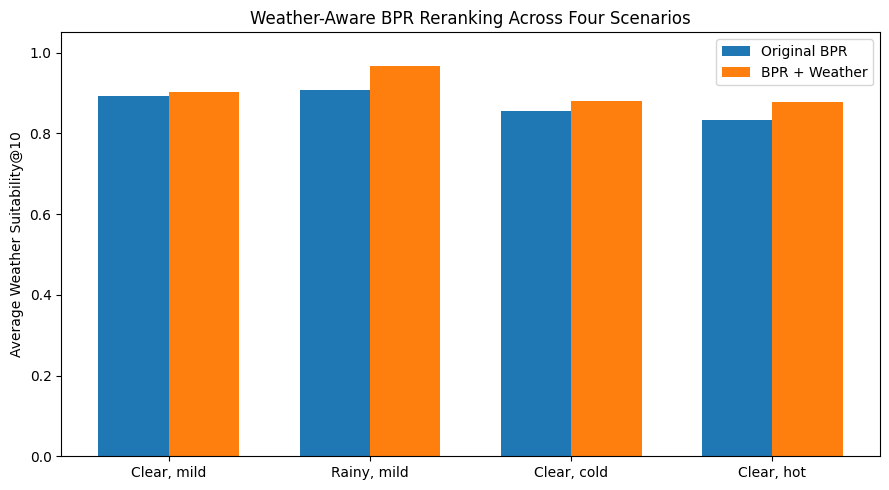

In [132]:

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(weather_results))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    weather_results["Original suitability"],
    width,
    label="Original BPR"
)

ax.bar(
    x + width / 2,
    weather_results["Reranked suitability"],
    width,
    label="BPR + Weather"
)

ax.set_xticks(x)
ax.set_xticklabels(weather_results["Scenario"])
ax.set_ylabel("Average Weather Suitability@10")
ax.set_ylim(0, 1.05)
ax.set_title("Weather-Aware BPR Reranking Across Four Scenarios")
ax.legend()

plt.tight_layout()
plt.show()


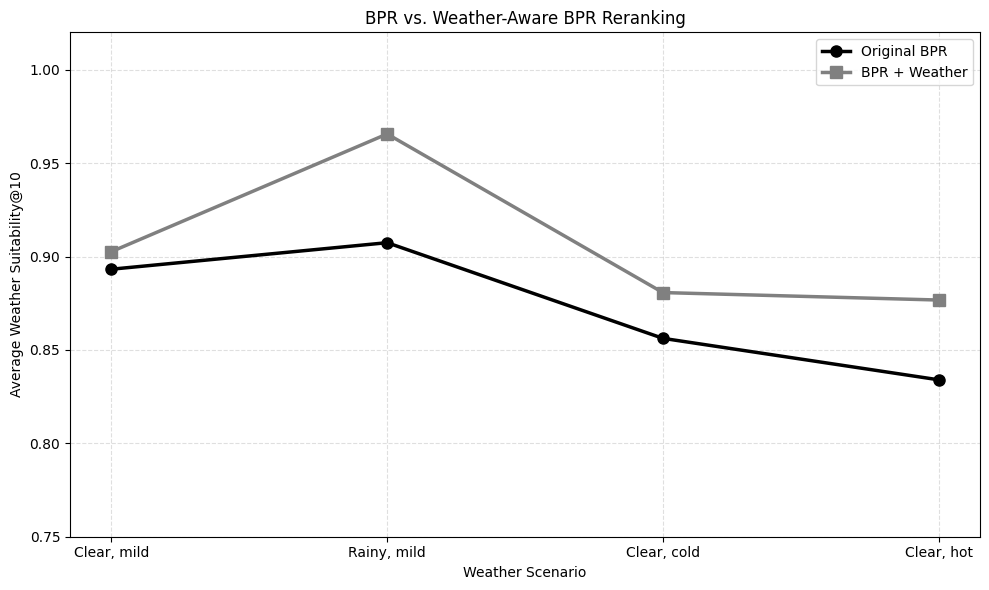

In [162]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    weather_results["Scenario"],
    weather_results["Original suitability"],
    color="black",
    marker="o",
    linewidth=2.5,
    markersize=8,
    label="Original BPR"
)

plt.plot(
    weather_results["Scenario"],
    weather_results["Reranked suitability"],
    color="gray",
    marker="s",
    linewidth=2.5,
    markersize=8,
    label="BPR + Weather"
)

plt.xlabel("Weather Scenario")
plt.ylabel("Average Weather Suitability@10")
plt.title("BPR vs. Weather-Aware BPR Reranking")

plt.ylim(0.75, 1.02)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()


In [163]:
plt.show()

In [164]:

# Save the graph for your presentation
graph_path = project / "data" / "processed" / "weather_reranking_line_graph.png"

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved to:", graph_path)


<Figure size 640x480 with 0 Axes>

Graph saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/weather_reranking_line_graph.png


In [165]:

# Save weather reranking experiment results

results_path = project / "data" / "processed" / "weather_reranking_results.csv"

weather_results.to_csv(results_path, index=False)

print("Results saved to:", results_path)
print("File exists:", results_path.exists())


Results saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/weather_reranking_results.csv
File exists: True


### Experiment 2: BPR vs. BPR + Time

In [137]:

# Inspect time availability and scoring

print("Time availability values:")
print(activity_v3["time_availability"].value_counts(dropna=False))

print("\nTime score values:")
print(activity_v3["time_score"].value_counts(dropna=False))

print("\nSample activities:")
display(
    activity_v3[
        ["gmap_id", "time_availability", "time_score"]
    ].head(10)
)


Time availability values:
time_availability
open       62503
unknown    12487
closed     11364
Name: count, dtype: int64

Time score values:
time_score
1.0    62503
0.5    12487
0.0    11364
Name: count, dtype: int64

Sample activities:


,gmap_id,time_availability,time_score
0,0x89d0be3bcc338707:0x3e3d9bf1247ba191,open,1.0
1,0x89c244688b7609cd:0x205e2d8d173dd35e,open,1.0
2,0x89d13fd0bc4468e1:0x1a81c620f5086b11,unknown,0.5
3,0x89c25923cbb1c20d:0xd9edcb0a146ba104,open,1.0
4,0x89c261f60bdf13db:0x38da730e4687a97b,open,1.0
5,0x89de391de9c094f5:0x13dfa43c3c56ca2d,unknown,0.5
6,0x89dfc6ffff74dfa9:0x57f299acd5653253,unknown,0.5
7,0x89dda1ebdac5b47f:0x2956ad04df07ee38,unknown,0.5
8,0x89c258ffaeaba947:0x8355860772a595a9,unknown,0.5
9,0x89c244427d3e2c19:0xc1dbf7d8e71d7201,open,1.0


In [138]:

print("Time availability distribution:")
print(activity_v3["time_availability"].value_counts(dropna=False))

print("\nTime score distribution:")
print(activity_v3["time_score"].value_counts(dropna=False))


Time availability distribution:
time_availability
open       62503
unknown    12487
closed     11364
Name: count, dtype: int64

Time score distribution:
time_score
1.0    62503
0.5    12487
0.0    11364
Name: count, dtype: int64


In [139]:

# Inspect existing time-related notebook variables

for name, value in globals().copy().items():
    if any(word in name.lower() for word in [
        "target_day", "target_time",
        "current_day", "current_time",
        "scenario_day", "scenario_time"
    ]):
        if not callable(value):
            print(name, "=", repr(value))


In [140]:

# Attach time availability and scores to BPR candidates

bpr_time = bpr_candidates.merge(
    activity_v3[
        ["gmap_id", "time_availability", "time_score"]
    ],
    on="gmap_id",
    how="left",
    validate="many_to_one"
)

print("Rows after merging:", len(bpr_time))

print("\nMissing time scores:")
print(bpr_time["time_score"].isna().sum())

print("\nTime availability among BPR candidates:")
print(bpr_time["time_availability"].value_counts(dropna=False))

print("\nFirst five rows:")
display(bpr_time.head())


Rows after merging: 10000

Missing time scores:
0

Time availability among BPR candidates:
time_availability
open       8503
closed      803
unknown     694
Name: count, dtype: int64

First five rows:


,user_id,gmap_id,bpr_rank,bpr_score,bpr_normalized,time_availability,time_score
0,100388958952721979686,0x89c2f3747f378f7d:0x61caa819e454f065,1,2.857783,1.000000,open,1.0
1,100388958952721979686,0x89c2f4e9f911e9d9:0x63082da1140b9e66,2,2.832877,0.937595,open,1.0
2,100388958952721979686,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,3,2.815485,0.894019,open,1.0
3,100388958952721979686,0x89c2f3926691fd75:0xae683d2e5147a9a8,4,2.800888,0.857444,open,1.0
4,100388958952721979686,0x89c28cba56f51c3d:0xe19c58eeca84032f,5,2.792721,0.836982,open,1.0


In [141]:

# Experiment 2: BPR + Time
# Scenario: Saturday at 2:00 PM

# Exclude closed activities
bpr_time_eligible = bpr_time[
    bpr_time["time_availability"] != "closed"
].copy()

# Calculate combined preference and time score
bpr_time_eligible["bpr_time_score"] = (
    0.70 * bpr_time_eligible["bpr_normalized"]
    + 0.30 * bpr_time_eligible["time_score"]
)

# Rank eligible activities separately for each user
bpr_time_eligible["bpr_time_rank"] = (
    bpr_time_eligible.groupby("user_id")["bpr_time_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

print("Original BPR candidates:", len(bpr_time))
print("Eligible candidates:", len(bpr_time_eligible))
print("Closed activities excluded:",
      len(bpr_time) - len(bpr_time_eligible))

print("\nUsers retained:",
      bpr_time_eligible["user_id"].nunique())

print("\nMinimum eligible candidates per user:",
      bpr_time_eligible.groupby("user_id").size().min())

print("\nExample user's top 10:")
example_user = bpr_time_eligible["user_id"].iloc[0]

display(
    bpr_time_eligible[
        bpr_time_eligible["user_id"] == example_user
    ]
    .sort_values("bpr_time_rank")
    [[
        "gmap_id",
        "time_availability",
        "bpr_rank",
        "bpr_normalized",
        "time_score",
        "bpr_time_score",
        "bpr_time_rank"
    ]]
    .head(10)
)


Original BPR candidates: 10000
Eligible candidates: 9197
Closed activities excluded: 803

Users retained: 50

Minimum eligible candidates per user: 153

Example user's top 10:


,gmap_id,time_availability,bpr_rank,bpr_normalized,time_score,bpr_time_score,bpr_time_rank
0,0x89c2f3747f378f7d:0x61caa819e454f065,open,1,1.000000,1.0,1.000000,1
1,0x89c2f4e9f911e9d9:0x63082da1140b9e66,open,2,0.937595,1.0,0.956317,2
2,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,open,3,0.894019,1.0,0.925813,3
3,0x89c2f3926691fd75:0xae683d2e5147a9a8,open,4,0.857444,1.0,0.900211,4
4,0x89c28cba56f51c3d:0xe19c58eeca84032f,open,5,0.836982,1.0,0.885887,5
5,0x89c2f475382671b5:0xba3e30bc6b46ce72,open,6,0.738152,1.0,0.816706,6
6,0x89c2f48036d65f93:0xc5a253c27b0d884b,open,7,0.733548,1.0,0.813483,7
7,0x89c2f38f07a99cc1:0xa2b82e65b3b2a94b,open,8,0.706234,1.0,0.794363,8
8,0x89c2f3868be16e11:0x91ed6a50bd941b37,open,9,0.673620,1.0,0.771534,9
9,0x89c2f396c9fea93b:0x4ce63bab0b0eaeb0,open,10,0.660372,1.0,0.762260,10


In [142]:

# Compare time suitability in the top 10

original_time_top10 = bpr_time[
    bpr_time["bpr_rank"] <= 10
]

reranked_time_top10 = bpr_time_eligible[
    bpr_time_eligible["bpr_time_rank"] <= 10
]

original_avg_time = original_time_top10["time_score"].mean()
reranked_avg_time = reranked_time_top10["time_score"].mean()

print("Original BPR time suitability@10:",
      round(original_avg_time, 4))

print("BPR + Time suitability@10:",
      round(reranked_avg_time, 4))

print("Absolute improvement:",
      round(reranked_avg_time - original_avg_time, 4))

print("Relative improvement:",
      f"{(reranked_avg_time / original_avg_time - 1) * 100:.2f}%")

print("\nClosed activities in original top 10:",
      (original_time_top10["time_availability"] == "closed").sum())

print("Closed activities in reranked top 10:",
      (reranked_time_top10["time_availability"] == "closed").sum())


Original BPR time suitability@10: 0.878
BPR + Time suitability@10: 0.981
Absolute improvement: 0.103
Relative improvement: 11.73%

Closed activities in original top 10: 37
Closed activities in reranked top 10: 0


In [143]:

# Compare BPR preference scores before and after time reranking

original_preference_time = original_time_top10[
    "bpr_normalized"
].mean()

reranked_preference_time = reranked_time_top10[
    "bpr_normalized"
].mean()

print("Original BPR preference@10:",
      round(original_preference_time, 4))

print("BPR + Time preference@10:",
      round(reranked_preference_time, 4))

print("Absolute preference change:",
      round(reranked_preference_time - original_preference_time, 4))

print("Relative preference change:",
      f"{(reranked_preference_time / original_preference_time - 1) * 100:.2f}%")


Original BPR preference@10: 0.7617
BPR + Time preference@10: 0.7456
Absolute preference change: -0.016
Relative preference change: -2.10%


In [144]:

# Compare original and time-aware top-10 recommendations

time_overlap_results = []

for user_id in bpr_time["user_id"].unique():
    original_ids = set(
        original_time_top10.loc[
            original_time_top10["user_id"] == user_id,
            "gmap_id"
        ]
    )

    reranked_ids = set(
        reranked_time_top10.loc[
            reranked_time_top10["user_id"] == user_id,
            "gmap_id"
        ]
    )

    overlap = len(original_ids & reranked_ids)

    time_overlap_results.append({
        "user_id": user_id,
        "overlap_count": overlap,
        "changed_count": 10 - overlap
    })

time_overlap_df = pd.DataFrame(time_overlap_results)

print("Average top-10 overlap:",
      round(time_overlap_df["overlap_count"].mean(), 2))

print("Average recommendations replaced:",
      round(time_overlap_df["changed_count"].mean(), 2))

print("Users evaluated:", len(time_overlap_df))


Average top-10 overlap: 8.68
Average recommendations replaced: 1.32
Users evaluated: 50


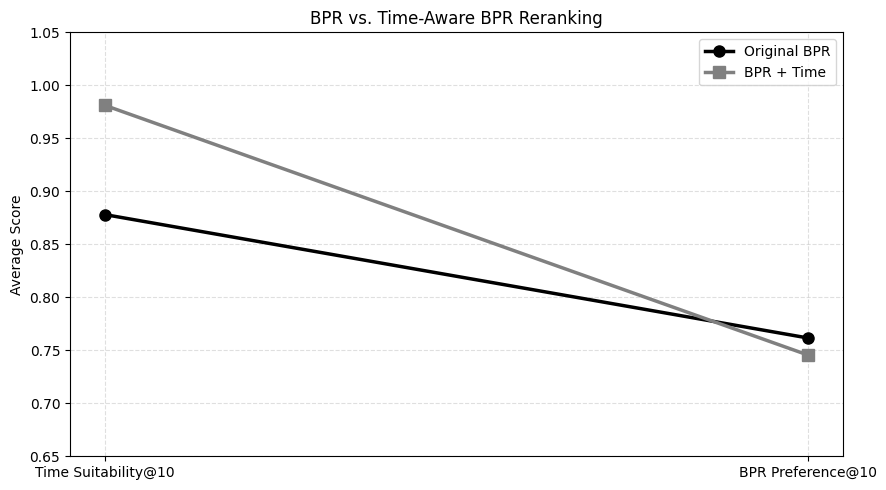

In [160]:

import matplotlib.pyplot as plt

metrics = ["Time Suitability@10", "BPR Preference@10"]

original_values = [
    original_avg_time,
    original_preference_time
]

reranked_values = [
    reranked_avg_time,
    reranked_preference_time
]

plt.figure(figsize=(9, 5))

plt.plot(
    metrics,
    original_values,
    color="black",
    marker="o",
    linewidth=2.5,
    markersize=8,
    label="Original BPR"
)

plt.plot(
    metrics,
    reranked_values,
    color="gray",
    marker="s",
    linewidth=2.5,
    markersize=8,
    label="BPR + Time"
)

plt.ylabel("Average Score")
plt.title("BPR vs. Time-Aware BPR Reranking")
plt.ylim(0.65, 1.05)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()


In [161]:

# Save time reranking graph
graph_path = project / "data" / "processed" / "time_reranking_line_graph.png"

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved to:", graph_path)
print("File exists:", graph_path.exists())


<Figure size 640x480 with 0 Axes>

Graph saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/time_reranking_line_graph.png
File exists: True


In [147]:

# Save Experiment 2: BPR vs. BPR + Time results

time_results = pd.DataFrame([{
    "scenario": "Saturday, 2:00 PM",
    "original_time_suitability": original_avg_time,
    "reranked_time_suitability": reranked_avg_time,
    "time_improvement_pct": (
        (reranked_avg_time / original_avg_time - 1) * 100
    ),
    "original_bpr_preference": original_preference_time,
    "reranked_bpr_preference": reranked_preference_time,
    "preference_change_pct": (
        (reranked_preference_time / original_preference_time - 1) * 100
    ),
    "average_top10_overlap": time_overlap_df["overlap_count"].mean(),
    "average_recommendations_replaced": time_overlap_df["changed_count"].mean(),
    "original_closed_top10": (
        original_time_top10["time_availability"] == "closed"
    ).sum(),
    "reranked_closed_top10": (
        reranked_time_top10["time_availability"] == "closed"
    ).sum()
}])

time_results_path = (
    project / "data" / "processed" / "time_reranking_results.csv"
)

time_results.to_csv(time_results_path, index=False)

display(time_results)

print("File exists:", time_results_path.exists())


,scenario,original_time_suitability,reranked_time_suitability,time_improvement_pct,original_bpr_preference,reranked_bpr_preference,preference_change_pct,average_top10_overlap,average_recommendations_replaced,original_closed_top10,reranked_closed_top10
0,"Saturday, 2:00 PM",0.878,0.981,11.731207,0.761677,0.745649,-2.10435,8.68,1.32,37,0


File exists: True


### Experiment 3: BPR + Weather + Time

In [148]:

# Experiment 3: Combine BPR, Weather, and Time data

bpr_weather_time = bpr_weather.merge(
    activity_v3[
        ["gmap_id", "time_availability", "time_score"]
    ],
    on="gmap_id",
    how="left",
    validate="many_to_one"
)

print("Total candidates:", len(bpr_weather_time))
print("Users:", bpr_weather_time["user_id"].nunique())

print("\nMissing time scores:",
      bpr_weather_time["time_score"].isna().sum())

print("Missing rainy weather scores:",
      bpr_weather_time["weather_score_rainy_mild"].isna().sum())

print("\nTime availability distribution:")
print(bpr_weather_time["time_availability"].value_counts())


Total candidates: 10000
Users: 50

Missing time scores: 0
Missing rainy weather scores: 0

Time availability distribution:
time_availability
open       8503
closed      803
unknown     694
Name: count, dtype: int64


In [149]:

# Experiment 3: BPR + Weather + Time
# Scenario: Rainy, mild weather — Saturday at 2:00 PM

# Exclude closed activities
bpr_weather_time_eligible = bpr_weather_time[
    bpr_weather_time["time_availability"] != "closed"
].copy()

# Calculate combined contextual score
bpr_weather_time_eligible["combined_score"] = (
    0.70 * bpr_weather_time_eligible["bpr_normalized"]
    + 0.15 * bpr_weather_time_eligible["weather_score_rainy_mild"]
    + 0.15 * bpr_weather_time_eligible["time_score"]
)

# Rank activities separately for each user
bpr_weather_time_eligible["combined_rank"] = (
    bpr_weather_time_eligible.groupby("user_id")["combined_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

print("Eligible candidates:", len(bpr_weather_time_eligible))
print("Users retained:",
      bpr_weather_time_eligible["user_id"].nunique())

print("\nMinimum eligible candidates per user:",
      bpr_weather_time_eligible.groupby("user_id").size().min())

print("\nCombined score range:")
print(
    bpr_weather_time_eligible["combined_score"].min(),
    bpr_weather_time_eligible["combined_score"].max()
)

print("\nExample user's top 10:")
example_user = bpr_weather_time_eligible["user_id"].iloc[0]

display(
    bpr_weather_time_eligible[
        bpr_weather_time_eligible["user_id"] == example_user
    ]
    .sort_values("combined_rank")
    [[
        "gmap_id",
        "bpr_rank",
        "weather_score_rainy_mild",
        "time_availability",
        "time_score",
        "combined_score",
        "combined_rank"
    ]]
    .head(10)
)


Eligible candidates: 9197
Users retained: 50

Minimum eligible candidates per user: 153

Combined score range:
0.105 1.0

Example user's top 10:


,gmap_id,bpr_rank,weather_score_rainy_mild,time_availability,time_score,combined_score,combined_rank
1,0x89c2f4e9f911e9d9:0x63082da1140b9e66,2,1.0,open,1.0,0.956317,1
2,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,3,1.0,open,1.0,0.925813,2
3,0x89c2f3926691fd75:0xae683d2e5147a9a8,4,1.0,open,1.0,0.900211,3
4,0x89c28cba56f51c3d:0xe19c58eeca84032f,5,1.0,open,1.0,0.885887,4
0,0x89c2f3747f378f7d:0x61caa819e454f065,1,0.2,open,1.0,0.880000,5
5,0x89c2f475382671b5:0xba3e30bc6b46ce72,6,1.0,open,1.0,0.816706,6
6,0x89c2f48036d65f93:0xc5a253c27b0d884b,7,1.0,open,1.0,0.813483,7
7,0x89c2f38f07a99cc1:0xa2b82e65b3b2a94b,8,1.0,open,1.0,0.794363,8
9,0x89c2f396c9fea93b:0x4ce63bab0b0eaeb0,10,1.0,open,1.0,0.762260,9
10,0x89c2f4b5ccf17095:0x543106b8d21b4908,11,1.0,open,1.0,0.762132,10


In [150]:

# Experiment 3: Evaluate combined contextual suitability

original_combined_top10 = bpr_weather_time[
    bpr_weather_time["bpr_rank"] <= 10
].copy()

reranked_combined_top10 = bpr_weather_time_eligible[
    bpr_weather_time_eligible["combined_rank"] <= 10
].copy()

# Average rainy-weather suitability
original_weather_avg = original_combined_top10[
    "weather_score_rainy_mild"
].mean()

reranked_weather_avg = reranked_combined_top10[
    "weather_score_rainy_mild"
].mean()

# Average time suitability
original_time_avg = original_combined_top10[
    "time_score"
].mean()

reranked_time_avg = reranked_combined_top10[
    "time_score"
].mean()

print("WEATHER SUITABILITY@10")
print("Original BPR:", round(original_weather_avg, 4))
print("Combined model:", round(reranked_weather_avg, 4))
print("Improvement:",
      f"{(reranked_weather_avg / original_weather_avg - 1) * 100:.2f}%")

print("\nTIME SUITABILITY@10")
print("Original BPR:", round(original_time_avg, 4))
print("Combined model:", round(reranked_time_avg, 4))
print("Improvement:",
      f"{(reranked_time_avg / original_time_avg - 1) * 100:.2f}%")

print("\nCLOSED ACTIVITIES IN TOP 10")
print("Original BPR:",
      (original_combined_top10["time_availability"] == "closed").sum())
print("Combined model:",
      (reranked_combined_top10["time_availability"] == "closed").sum())


WEATHER SUITABILITY@10
Original BPR: 0.9074
Combined model: 0.953
Improvement: 5.03%

TIME SUITABILITY@10
Original BPR: 0.878
Combined model: 0.969
Improvement: 10.36%

CLOSED ACTIVITIES IN TOP 10
Original BPR: 37
Combined model: 0


In [152]:

# Experiment 3: Compare BPR preference before and after
# combined weather + time reranking

original_combined_preference = original_combined_top10[
    "bpr_normalized"
].mean()

reranked_combined_preference = reranked_combined_top10[
    "bpr_normalized"
].mean()

print("Original BPR preference@10:",
      round(original_combined_preference, 4))

print("Combined model preference@10:",
      round(reranked_combined_preference, 4))

print("Absolute preference change:",
      round(
          reranked_combined_preference - original_combined_preference,
          4
      ))

print("Relative preference change:",
      f"{(reranked_combined_preference / original_combined_preference - 1) * 100:.2f}%")


Original BPR preference@10: 0.7617
Combined model preference@10: 0.746
Absolute preference change: -0.0157
Relative preference change: -2.06%


In [153]:

# Experiment 3: Top-10 recommendation overlap

combined_overlap_results = []

for user_id in bpr_weather_time["user_id"].unique():

    original_ids = set(
        original_combined_top10.loc[
            original_combined_top10["user_id"] == user_id,
            "gmap_id"
        ]
    )

    combined_ids = set(
        reranked_combined_top10.loc[
            reranked_combined_top10["user_id"] == user_id,
            "gmap_id"
        ]
    )

    overlap = len(original_ids & combined_ids)

    combined_overlap_results.append({
        "user_id": user_id,
        "overlap_count": overlap,
        "changed_count": 10 - overlap
    })

combined_overlap_df = pd.DataFrame(combined_overlap_results)

print("Average top-10 overlap:",
      round(combined_overlap_df["overlap_count"].mean(), 2))

print("Average recommendations replaced:",
      round(combined_overlap_df["changed_count"].mean(), 2))

print("Users evaluated:", len(combined_overlap_df))


Average top-10 overlap: 8.44
Average recommendations replaced: 1.56
Users evaluated: 50


In [154]:

# Save Experiment 3: BPR + Weather + Time results

combined_results = pd.DataFrame([{
    "scenario": "Rainy, mild - Saturday, 2:00 PM",
    "original_weather_suitability": original_weather_avg,
    "combined_weather_suitability": reranked_weather_avg,
    "weather_improvement_pct": (
        (reranked_weather_avg / original_weather_avg - 1) * 100
    ),
    "original_time_suitability": original_time_avg,
    "combined_time_suitability": reranked_time_avg,
    "time_improvement_pct": (
        (reranked_time_avg / original_time_avg - 1) * 100
    ),
    "original_bpr_preference": original_combined_preference,
    "combined_bpr_preference": reranked_combined_preference,
    "preference_change_pct": (
        (reranked_combined_preference / original_combined_preference - 1) * 100
    ),
    "average_top10_overlap": combined_overlap_df["overlap_count"].mean(),
    "average_recommendations_replaced": combined_overlap_df["changed_count"].mean(),
    "original_closed_top10": (
        original_combined_top10["time_availability"] == "closed"
    ).sum(),
    "combined_closed_top10": (
        reranked_combined_top10["time_availability"] == "closed"
    ).sum()
}])

combined_results_path = (
    project / "data" / "processed" / "combined_reranking_results.csv"
)

combined_results.to_csv(combined_results_path, index=False)

display(combined_results)

print("File exists:", combined_results_path.exists())


,scenario,original_weather_suitability,combined_weather_suitability,weather_improvement_pct,original_time_suitability,combined_time_suitability,time_improvement_pct,original_bpr_preference,combined_bpr_preference,preference_change_pct,average_top10_overlap,average_recommendations_replaced,original_closed_top10,combined_closed_top10
0,"Rainy, mild - Saturday, 2:00 PM",0.9074,0.953,5.025347,0.878,0.969,10.364465,0.761677,0.745956,-2.064037,8.44,1.56,37,0


File exists: True


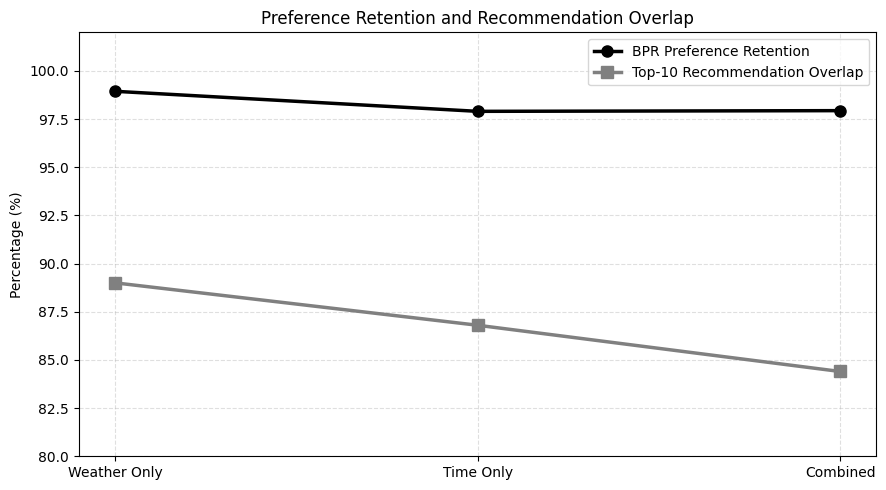

In [158]:

import matplotlib.pyplot as plt

models = ["Weather Only", "Time Only", "Combined"]

preference_retention = [
    100 - 1.06,
    100 - 2.10,
    100 - 2.064037
]

top10_overlap = [89.0, 86.8, 84.4]

plt.figure(figsize=(9, 5))

plt.plot(
    models,
    preference_retention,
    color="black",
    marker="o",
    linewidth=2.5,
    markersize=8,
    label="BPR Preference Retention"
)

plt.plot(
    models,
    top10_overlap,
    color="gray",
    marker="s",
    linewidth=2.5,
    markersize=8,
    label="Top-10 Recommendation Overlap"
)

plt.ylabel("Percentage (%)")
plt.title("Preference Retention and Recommendation Overlap")
plt.ylim(80, 102)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()


In [159]:

# Save final experiment comparison graph

comparison_graph_path = (
    project / "data" / "processed" /
    "final_experiment_comparison.png"
)

plt.savefig(
    comparison_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved to:", comparison_graph_path)
print("File exists:", comparison_graph_path.exists())


<Figure size 640x480 with 0 Axes>

Graph saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/final_experiment_comparison.png
File exists: True


In [157]:

# Final comparison of all three experiments

final_comparison = pd.DataFrame({
    "Model": [
        "BPR + Weather",
        "BPR + Time",
        "BPR + Weather + Time"
    ],
    "Weather_Improvement_Pct": [
        6.41, None, 5.03
    ],
    "Time_Improvement_Pct": [
        None, 11.73, 10.36
    ],
    "Preference_Change_Pct": [
        -1.06, -2.10, -2.06
    ],
    "Top10_Overlap_Pct": [
        89.0, 86.8, 84.4
    ]
})

comparison_path = (
    project / "data" / "processed" /
    "final_experiment_comparison.csv"
)

final_comparison.to_csv(comparison_path, index=False)

display(final_comparison)

print("File exists:", comparison_path.exists())


,Model,Weather_Improvement_Pct,Time_Improvement_Pct,Preference_Change_Pct,Top10_Overlap_Pct
0,BPR + Weather,6.41,NaN,-1.06,89.0
1,BPR + Time,NaN,11.73,-2.10,86.8
2,BPR + Weather + Time,5.03,10.36,-2.06,84.4


File exists: True


### Weather and Time Contextual Reranking Results

Three experiments were conducted to evaluate the effectiveness of incorporating weather conditions and temporal availability into a Bayesian Personalized Ranking (BPR) recommendation baseline. The evaluation used 50 synthetic users, each with 200 candidate activities, producing 10,000 user–activity candidate pairs.

The first experiment evaluated weather-aware reranking under four weather scenarios. Under rainy, mild conditions, weather suitability@10 improved by 6.41%, while the average predicted BPR preference score decreased by 1.06%.

The second experiment evaluated time-aware reranking for Saturday at 2:00 PM. Time suitability@10 improved by 11.73%, while predicted preference decreased by 2.10%. Additionally, all 37 closed activities appearing in the original top-10 recommendation lists were eliminated.

The third experiment combined weather and temporal context using a weighted ranking function consisting of 70% BPR preference, 15% weather suitability, and 15% time suitability, with closed activities excluded. Under rainy, mild weather on Saturday at 2:00 PM, weather suitability improved by 5.03% and time suitability improved by 10.36%. The average predicted preference score decreased by 2.06%, while 84.4% of the original top-10 recommendations were retained.

Overall, the findings demonstrate that contextual reranking can improve the suitability of activity recommendations while largely preserving preference-based ranking scores. These results are based on synthetic-user evaluations and predefined contextual suitability measures rather than observed user satisfaction.

### Weight sensitivity analysis for weather and time

In [166]:

# Weight sensitivity analysis: BPR + Weather
# Scenario: Rainy, mild

weather_weight_results = []

for weather_weight in [0.10, 0.20, 0.30, 0.40, 0.50]:

    bpr_weight = 1.0 - weather_weight

    test = bpr_weather.copy()

    test["weighted_score"] = (
        bpr_weight * test["bpr_normalized"]
        + weather_weight * test["weather_score_rainy_mild"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    weather_weight_results.append({
        "bpr_weight": bpr_weight,
        "weather_weight": weather_weight,
        "weather_suitability": top10[
            "weather_score_rainy_mild"
        ].mean(),
        "bpr_preference": top10["bpr_normalized"].mean()
    })

weather_weight_df = pd.DataFrame(weather_weight_results)

display(weather_weight_df.round(4))


,bpr_weight,weather_weight,weather_suitability,bpr_preference
0,0.9,0.1,0.9366,0.7602
1,0.8,0.2,0.9544,0.7572
2,0.7,0.3,0.9656,0.7536
3,0.6,0.4,0.9850,0.7430
4,0.5,0.5,0.9948,0.7349


In [167]:

# Weather weight sensitivity: Top-10 overlap

weather_overlap_results = []

for weather_weight in [0.10, 0.20, 0.30, 0.40, 0.50]:

    bpr_weight = 1.0 - weather_weight

    test = bpr_weather.copy()

    test["weighted_score"] = (
        bpr_weight * test["bpr_normalized"]
        + weather_weight * test["weather_score_rainy_mild"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    overlaps = []

    for user_id in test["user_id"].unique():
        original_ids = set(
            test.loc[
                (test["user_id"] == user_id)
                & (test["bpr_rank"] <= 10),
                "gmap_id"
            ]
        )

        reranked_ids = set(
            top10.loc[top10["user_id"] == user_id, "gmap_id"]
        )

        overlaps.append(len(original_ids & reranked_ids) / 10 * 100)

    weather_overlap_results.append({
        "weather_weight": weather_weight,
        "top10_overlap_pct": sum(overlaps) / len(overlaps)
    })

weather_overlap_df = pd.DataFrame(weather_overlap_results)

weather_weight_df = weather_weight_df.merge(
    weather_overlap_df,
    on="weather_weight",
    validate="one_to_one"
)

display(weather_weight_df.round(4))


,bpr_weight,weather_weight,weather_suitability,bpr_preference,top10_overlap_pct
0,0.9,0.1,0.9366,0.7602,95.4
1,0.8,0.2,0.9544,0.7572,91.6
2,0.7,0.3,0.9656,0.7536,89.0
3,0.6,0.4,0.9850,0.7430,84.8
4,0.5,0.5,0.9948,0.7349,82.0


In [168]:

# Save weather weight sensitivity results

weather_weights_path = (
    project / "data" / "processed" /
    "weather_weight_sensitivity.csv"
)

weather_weight_df.to_csv(weather_weights_path, index=False)

print("File exists:", weather_weights_path.exists())
print("Saved to:", weather_weights_path)


File exists: True
Saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/weather_weight_sensitivity.csv


In [169]:

# Weight sensitivity analysis: BPR + Time
# Scenario: Saturday at 2:00 PM

time_weight_results = []

for time_weight in [0.10, 0.20, 0.30, 0.40, 0.50]:

    bpr_weight = 1.0 - time_weight

    test = bpr_time[
        bpr_time["time_availability"] != "closed"
    ].copy()

    test["weighted_score"] = (
        bpr_weight * test["bpr_normalized"]
        + time_weight * test["time_score"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    time_weight_results.append({
        "bpr_weight": bpr_weight,
        "time_weight": time_weight,
        "time_suitability": top10["time_score"].mean(),
        "bpr_preference": top10["bpr_normalized"].mean()
    })

time_weight_df = pd.DataFrame(time_weight_results)

display(time_weight_df.round(4))


,bpr_weight,time_weight,time_suitability,bpr_preference
0,0.9,0.1,0.961,0.7509
1,0.8,0.2,0.969,0.7495
2,0.7,0.3,0.981,0.7456
3,0.6,0.4,0.992,0.7395
4,0.5,0.5,0.998,0.7346


In [170]:

# Time weight sensitivity: Top-10 overlap

time_overlap_results_weights = []

for time_weight in [0.10, 0.20, 0.30, 0.40, 0.50]:

    bpr_weight = 1.0 - time_weight

    test = bpr_time[
        bpr_time["time_availability"] != "closed"
    ].copy()

    test["weighted_score"] = (
        bpr_weight * test["bpr_normalized"]
        + time_weight * test["time_score"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    overlaps = []

    for user_id in bpr_time["user_id"].unique():

        original_ids = set(
            bpr_time.loc[
                (bpr_time["user_id"] == user_id)
                & (bpr_time["bpr_rank"] <= 10),
                "gmap_id"
            ]
        )

        reranked_ids = set(
            top10.loc[
                top10["user_id"] == user_id,
                "gmap_id"
            ]
        )

        overlaps.append(
            len(original_ids & reranked_ids) / 10 * 100
        )

    time_overlap_results_weights.append({
        "time_weight": time_weight,
        "top10_overlap_pct": sum(overlaps) / len(overlaps)
    })

time_overlap_weights_df = pd.DataFrame(
    time_overlap_results_weights
)

time_weight_df = time_weight_df.merge(
    time_overlap_weights_df,
    on="time_weight",
    validate="one_to_one"
)

display(time_weight_df.round(4))


,bpr_weight,time_weight,time_suitability,bpr_preference,top10_overlap_pct
0,0.9,0.1,0.961,0.7509,90.8
1,0.8,0.2,0.969,0.7495,89.2
2,0.7,0.3,0.981,0.7456,86.8
3,0.6,0.4,0.992,0.7395,84.6
4,0.5,0.5,0.998,0.7346,83.4


In [171]:

# Save time weight sensitivity results

time_weights_path = (
    project / "data" / "processed" /
    "time_weight_sensitivity.csv"
)

time_weight_df.to_csv(time_weights_path, index=False)

print("File exists:", time_weights_path.exists())
print("Saved to:", time_weights_path)


File exists: True
Saved to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed/time_weight_sensitivity.csv


In [172]:

# Combined weight sensitivity: BPR + Weather + Time
# Scenario: Rainy, mild weather — Saturday at 2 PM

combined_weight_results = []

weight_combinations = [
    (0.90, 0.05, 0.05),
    (0.80, 0.10, 0.10),
    (0.70, 0.15, 0.15),
    (0.60, 0.20, 0.20),
    (0.50, 0.25, 0.25)
]

for bpr_w, weather_w, time_w in weight_combinations:

    test = bpr_weather_time[
        bpr_weather_time["time_availability"] != "closed"
    ].copy()

    test["weighted_score"] = (
        bpr_w * test["bpr_normalized"]
        + weather_w * test["weather_score_rainy_mild"]
        + time_w * test["time_score"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    combined_weight_results.append({
        "bpr_weight": bpr_w,
        "weather_weight": weather_w,
        "time_weight": time_w,
        "weather_suitability": top10[
            "weather_score_rainy_mild"
        ].mean(),
        "time_suitability": top10["time_score"].mean(),
        "bpr_preference": top10["bpr_normalized"].mean()
    })

combined_weight_df = pd.DataFrame(combined_weight_results)

display(combined_weight_df.round(4))


,bpr_weight,weather_weight,time_weight,weather_suitability,time_suitability,bpr_preference
0,0.9,0.05,0.05,0.9252,0.959,0.7508
1,0.8,0.10,0.10,0.9370,0.963,0.7495
2,0.7,0.15,0.15,0.9530,0.969,0.7460
3,0.6,0.20,0.20,0.9628,0.981,0.7399
4,0.5,0.25,0.25,0.9752,0.988,0.7317


In [173]:

# Combined weight sensitivity: Top-10 overlap

combined_overlap_results = []

for bpr_w, weather_w, time_w in weight_combinations:

    test = bpr_weather_time[
        bpr_weather_time["time_availability"] != "closed"
    ].copy()

    test["weighted_score"] = (
        bpr_w * test["bpr_normalized"]
        + weather_w * test["weather_score_rainy_mild"]
        + time_w * test["time_score"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    overlaps = []

    for user_id in test["user_id"].unique():

        original_ids = set(
            test.loc[
                (test["user_id"] == user_id)
                & (test["bpr_rank"] <= 10),
                "gmap_id"
            ]
        )

        reranked_ids = set(
            top10.loc[
                top10["user_id"] == user_id,
                "gmap_id"
            ]
        )

        overlaps.append(
            len(original_ids & reranked_ids) / 10 * 100
        )

    combined_overlap_results.append({
        "bpr_weight": bpr_w,
        "weather_weight": weather_w,
        "time_weight": time_w,
        "eligible_bpr_overlap_pct": sum(overlaps) / len(overlaps)
    })

combined_overlap_df = pd.DataFrame(combined_overlap_results)

combined_weight_df = combined_weight_df.merge(
    combined_overlap_df,
    on=["bpr_weight", "weather_weight", "time_weight"],
    validate="one_to_one"
)

display(combined_weight_df.round(4))


,bpr_weight,weather_weight,time_weight,weather_suitability,time_suitability,bpr_preference,eligible_bpr_overlap_pct
0,0.9,0.05,0.05,0.9252,0.959,0.7508,89.8
1,0.8,0.10,0.10,0.9370,0.963,0.7495,87.6
2,0.7,0.15,0.15,0.9530,0.969,0.7460,84.4
3,0.6,0.20,0.20,0.9628,0.981,0.7399,80.6
4,0.5,0.25,0.25,0.9752,0.988,0.7317,77.6


In [174]:

# Unequal weather and time weight sensitivity
# Keep BPR weight fixed at 0.70

unequal_weight_results = []

unequal_combinations = [
    (0.70, 0.05, 0.25),
    (0.70, 0.10, 0.20),
    (0.70, 0.15, 0.15),
    (0.70, 0.20, 0.10),
    (0.70, 0.25, 0.05)
]

for bpr_w, weather_w, time_w in unequal_combinations:

    test = bpr_weather_time[
        bpr_weather_time["time_availability"] != "closed"
    ].copy()

    test["weighted_score"] = (
        bpr_w * test["bpr_normalized"]
        + weather_w * test["weather_score_rainy_mild"]
        + time_w * test["time_score"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    unequal_weight_results.append({
        "bpr_weight": bpr_w,
        "weather_weight": weather_w,
        "time_weight": time_w,
        "weather_suitability": top10[
            "weather_score_rainy_mild"
        ].mean(),
        "time_suitability": top10["time_score"].mean(),
        "bpr_preference": top10["bpr_normalized"].mean()
    })

unequal_weight_df = pd.DataFrame(unequal_weight_results)

display(unequal_weight_df.round(4))


,bpr_weight,weather_weight,time_weight,weather_suitability,time_suitability,bpr_preference
0,0.7,0.05,0.25,0.9318,0.978,0.7463
1,0.7,0.10,0.20,0.9452,0.976,0.7455
2,0.7,0.15,0.15,0.9530,0.969,0.7460
3,0.7,0.20,0.10,0.9576,0.968,0.7450
4,0.7,0.25,0.05,0.9608,0.961,0.7447


In [175]:

# Top-10 overlap for unequal weather/time weights

unequal_overlap_results = []

for bpr_w, weather_w, time_w in unequal_combinations:

    test = bpr_weather_time[
        bpr_weather_time["time_availability"] != "closed"
    ].copy()

    test["weighted_score"] = (
        bpr_w * test["bpr_normalized"]
        + weather_w * test["weather_score_rainy_mild"]
        + time_w * test["time_score"]
    )

    test["weighted_rank"] = (
        test.groupby("user_id")["weighted_score"]
        .rank(method="first", ascending=False)
    )

    top10 = test[test["weighted_rank"] <= 10]

    overlaps = []

    for user_id in test["user_id"].unique():

        original_ids = set(
            bpr_weather_time.loc[
                (bpr_weather_time["user_id"] == user_id)
                & (bpr_weather_time["bpr_rank"] <= 10),
                "gmap_id"
            ]
        )

        reranked_ids = set(
            top10.loc[top10["user_id"] == user_id, "gmap_id"]
        )

        overlaps.append(
            len(original_ids & reranked_ids) / 10 * 100
        )

    unequal_overlap_results.append({
        "bpr_weight": bpr_w,
        "weather_weight": weather_w,
        "time_weight": time_w,
        "top10_overlap_pct": sum(overlaps) / len(overlaps)
    })

unequal_overlap_df = pd.DataFrame(unequal_overlap_results)

unequal_weight_df = unequal_weight_df.merge(
    unequal_overlap_df,
    on=["bpr_weight", "weather_weight", "time_weight"],
    validate="one_to_one"
)

display(unequal_weight_df.round(4))


,bpr_weight,weather_weight,time_weight,weather_suitability,time_suitability,bpr_preference,top10_overlap_pct
0,0.7,0.05,0.25,0.9318,0.978,0.7463,86.0
1,0.7,0.10,0.20,0.9452,0.976,0.7455,84.4
2,0.7,0.15,0.15,0.9530,0.969,0.7460,84.4
3,0.7,0.20,0.10,0.9576,0.968,0.7450,83.2
4,0.7,0.25,0.05,0.9608,0.961,0.7447,83.0


In [176]:

# Save combined weight sensitivity results

output_dir = project / "data" / "processed"

combined_path = output_dir / "combined_weight_sensitivity.csv"
unequal_path = output_dir / "unequal_weight_sensitivity.csv"

combined_weight_df.to_csv(combined_path, index=False)
unequal_weight_df.to_csv(unequal_path, index=False)

print("Combined weights saved:", combined_path.exists())
print("Unequal weights saved:", unequal_path.exists())


Combined weights saved: True
Unequal weights saved: True


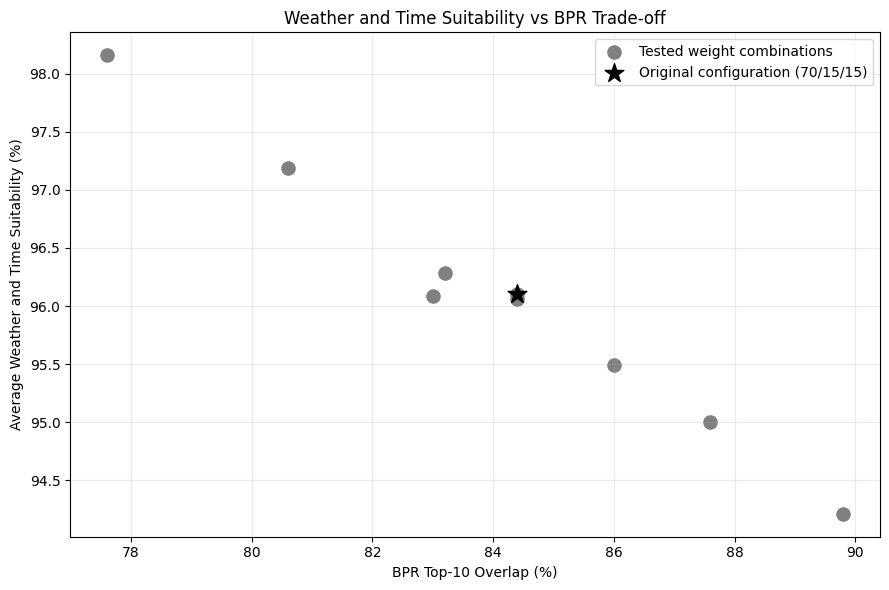

Configurations plotted: 9
Original configuration found: 1


In [178]:

# Fix overlap column names and recreate the trade-off graph

combined_plot = combined_weight_df.rename(
    columns={"eligible_bpr_overlap_pct": "top10_overlap_pct"}
)

tradeoff_df = pd.concat(
    [combined_plot, unequal_weight_df],
    ignore_index=True
).drop_duplicates(
    subset=["bpr_weight", "weather_weight", "time_weight"]
)

tradeoff_df["joint_suitability_pct"] = (
    tradeoff_df["weather_suitability"]
    + tradeoff_df["time_suitability"]
) / 2 * 100

plt.figure(figsize=(9, 6))

plt.scatter(
    tradeoff_df["top10_overlap_pct"],
    tradeoff_df["joint_suitability_pct"],
    color="gray",
    s=90,
    label="Tested weight combinations"
)

selected = tradeoff_df[
    (tradeoff_df["bpr_weight"].round(2) == 0.70)
    & (tradeoff_df["weather_weight"].round(2) == 0.15)
    & (tradeoff_df["time_weight"].round(2) == 0.15)
]

plt.scatter(
    selected["top10_overlap_pct"],
    selected["joint_suitability_pct"],
    color="black",
    marker="*",
    s=200,
    label="Original configuration (70/15/15)",
    zorder=5
)

plt.xlabel("BPR Top-10 Overlap (%)")
plt.ylabel("Average Weather and Time Suitability (%)")
plt.title("Weather and Time Suitability vs BPR Trade-off")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Configurations plotted:", len(tradeoff_df))
print("Original configuration found:", len(selected))


In [179]:
import numpy as np
import pandas as pd

# Generate a grid of weather and time weights

weight_grid = []

weather_weights = np.arange(0.00, 0.51, 0.05)
time_weights = np.arange(0.00, 0.51, 0.05)

for weather_w in weather_weights:
    for time_w in time_weights:

        bpr_w = 1.0 - weather_w - time_w

        if bpr_w >= -1e-9:

            weight_grid.append({
                "bpr_weight": round(max(0, bpr_w), 2),
                "weather_weight": round(weather_w, 2),
                "time_weight": round(time_w, 2)
            })

weight_grid_df = pd.DataFrame(weight_grid)

print("Total weight combinations:", len(weight_grid_df))

display(weight_grid_df.head(15))

Total weight combinations: 121


,bpr_weight,weather_weight,time_weight
0,1.00,0.00,0.00
1,0.95,0.00,0.05
2,0.90,0.00,0.10
3,0.85,0.00,0.15
4,0.80,0.00,0.20
5,0.75,0.00,0.25
6,0.70,0.00,0.30
7,0.65,0.00,0.35
8,0.60,0.00,0.40
9,0.55,0.00,0.45


## Redo

In [180]:
# RESTARTED EVALUATION
# Step 1: Verify the shared BPR candidate pool

import pandas as pd

evaluation_candidates = bpr_weather_time.copy()

print("Total candidate rows:", len(evaluation_candidates))
print("Number of users:", evaluation_candidates["user_id"].nunique())
print(
    "Candidates per user:",
    evaluation_candidates.groupby("user_id").size().unique()
)

print("\nAvailable columns:")
print(evaluation_candidates.columns.tolist())

print("\nMissing values in evaluation columns:")

required_columns = [
    "user_id",
    "gmap_id",
    "bpr_rank",
    "bpr_normalized",
    "weather_score_rainy_mild",
    "time_score",
    "time_availability"
]

print(evaluation_candidates[required_columns].isna().sum())

Total candidate rows: 10000
Number of users: 50
Candidates per user: [200]

Available columns:
['user_id', 'gmap_id', 'bpr_rank', 'bpr_score', 'bpr_normalized', 'weather_exposure_final', 'weather_score_clear_mild', 'weather_score_rainy_mild', 'weather_score_clear_cold', 'weather_score_clear_hot', 'bpr_weather_score', 'bpr_weather_rank', 'time_availability', 'time_score']

Missing values in evaluation columns:
user_id                     0
gmap_id                     0
bpr_rank                    0
bpr_normalized              0
weather_score_rainy_mild    0
time_score                  0
time_availability           0
dtype: int64


In [183]:

# EXPERIMENT 1: BPR vs Weather
# Step 2: Original BPR-only baseline
# Scenario: Rainy, mild weather

original_bpr_top10 = evaluation_candidates[
    evaluation_candidates["bpr_rank"] <= 10
].copy()

bpr_weather_baseline = {
    "model": "BPR only",
    "weather_weight": 0.0,
    "weather_suitability": original_bpr_top10[
        "weather_score_rainy_mild"
    ].mean(),
    "bpr_preference": original_bpr_top10[
        "bpr_normalized"
    ].mean(),
    "top10_overlap_pct": 100.0
}

print("Total top-10 recommendations:", len(original_bpr_top10))
print("Users represented:", original_bpr_top10["user_id"].nunique())

display(
    pd.DataFrame([bpr_weather_baseline]).round(4)
)


Total top-10 recommendations: 500
Users represented: 50


,model,weather_weight,weather_suitability,bpr_preference,top10_overlap_pct
0,BPR only,0.0,0.9074,0.7617,100.0


In [184]:

# EXPERIMENT 1: Weather-only weight sensitivity
# Rainy, mild weather

import numpy as np

weather_experiment_results = []

original_ids = {
    user_id: set(group["gmap_id"])
    for user_id, group in original_bpr_top10.groupby("user_id")
}

for weather_w in np.round(np.arange(0.00, 0.51, 0.05), 2):

    bpr_w = round(1.0 - weather_w, 2)

    test = evaluation_candidates.copy()

    test["rerank_score"] = (
        bpr_w * test["bpr_normalized"]
        + weather_w * test["weather_score_rainy_mild"]
    )

    # Use original BPR rank to break score ties consistently
    test = test.sort_values(
        ["user_id", "rerank_score", "bpr_rank"],
        ascending=[True, False, True]
    )

    top10 = test.groupby("user_id", sort=False).head(10)

    overlaps = [
        len(
            original_ids[user_id]
            & set(group["gmap_id"])
        ) / 10 * 100
        for user_id, group in top10.groupby("user_id")
    ]

    weather_experiment_results.append({
        "bpr_weight": bpr_w,
        "weather_weight": weather_w,
        "weather_suitability": top10[
            "weather_score_rainy_mild"
        ].mean(),
        "bpr_preference": top10["bpr_normalized"].mean(),
        "top10_overlap_pct": np.mean(overlaps)
    })

weather_experiment_df = pd.DataFrame(weather_experiment_results)

print("Configurations tested:", len(weather_experiment_df))
display(weather_experiment_df.round(4))


Configurations tested: 11


,bpr_weight,weather_weight,weather_suitability,bpr_preference,top10_overlap_pct
0,1.00,0.00,0.9074,0.7617,100.0
1,0.95,0.05,0.9208,0.7614,97.8
2,0.90,0.10,0.9366,0.7602,95.4
3,0.85,0.15,0.9460,0.7589,93.4
4,0.80,0.20,0.9544,0.7572,91.6
5,0.75,0.25,0.9604,0.7555,89.8
6,0.70,0.30,0.9656,0.7536,89.0
7,0.65,0.35,0.9748,0.7492,86.8
8,0.60,0.40,0.9850,0.7430,84.8
9,0.55,0.45,0.9894,0.7398,83.6


In [185]:

# EXPERIMENT 2: BPR vs Time
# Step 4: Unfiltered BPR-only baseline
# Scenario: Saturday at 2 PM

time_baseline = pd.DataFrame([{
    "model": "BPR only",
    "time_weight": 0.0,
    "time_suitability": original_bpr_top10["time_score"].mean(),
    "bpr_preference": original_bpr_top10["bpr_normalized"].mean(),
    "top10_overlap_pct": 100.0,
    "closed_count": (
        original_bpr_top10["time_availability"] == "closed"
    ).sum(),
    "open_count": (
        original_bpr_top10["time_availability"] == "open"
    ).sum(),
    "unknown_count": (
        original_bpr_top10["time_availability"] == "unknown"
    ).sum()
}])

display(time_baseline.round(4))


,model,time_weight,time_suitability,bpr_preference,top10_overlap_pct,closed_count,open_count,unknown_count
0,BPR only,0.0,0.878,0.7617,100.0,37,415,48


In [186]:

# EXPERIMENT 2: Filtered BPR baseline
# Remove closed activities without changing BPR scores

time_eligible = evaluation_candidates[
    evaluation_candidates["time_availability"] != "closed"
].copy()

filtered_bpr_top10 = (
    time_eligible
    .sort_values(
        ["user_id", "bpr_rank"],
        ascending=[True, True]
    )
    .groupby("user_id", sort=False)
    .head(10)
)

filtered_overlaps = [
    len(
        original_ids[user_id] & set(group["gmap_id"])
    ) / 10 * 100
    for user_id, group in filtered_bpr_top10.groupby("user_id")
]

filtered_time_baseline = pd.DataFrame([{
    "model": "BPR + closed-activity filter",
    "time_weight": 0.0,
    "time_suitability": filtered_bpr_top10["time_score"].mean(),
    "bpr_preference": filtered_bpr_top10["bpr_normalized"].mean(),
    "top10_overlap_pct": np.mean(filtered_overlaps),
    "closed_count": (
        filtered_bpr_top10["time_availability"] == "closed"
    ).sum()
}])

display(filtered_time_baseline.round(4))


,model,time_weight,time_suitability,bpr_preference,top10_overlap_pct,closed_count
0,BPR + closed-activity filter,0.0,0.95,0.7514,92.6,0


In [187]:

# EXPERIMENT 2: Time-only weight sensitivity
# Scenario: Saturday at 2 PM
# Closed activities excluded in every configuration

time_experiment_results = []

for time_w in np.round(np.arange(0.00, 0.51, 0.05), 2):

    bpr_w = round(1.0 - time_w, 2)

    test = time_eligible.copy()

    test["rerank_score"] = (
        bpr_w * test["bpr_normalized"]
        + time_w * test["time_score"]
    )

    test = test.sort_values(
        ["user_id", "rerank_score", "bpr_rank"],
        ascending=[True, False, True]
    )

    top10 = test.groupby("user_id", sort=False).head(10)

    overlaps = [
        len(
            original_ids[user_id] & set(group["gmap_id"])
        ) / 10 * 100
        for user_id, group in top10.groupby("user_id")
    ]

    time_experiment_results.append({
        "bpr_weight": bpr_w,
        "time_weight": time_w,
        "time_suitability": top10["time_score"].mean(),
        "bpr_preference": top10["bpr_normalized"].mean(),
        "top10_overlap_pct": np.mean(overlaps),
        "closed_count": (
            top10["time_availability"] == "closed"
        ).sum()
    })

time_experiment_df = pd.DataFrame(time_experiment_results)

print("Configurations tested:", len(time_experiment_df))
display(time_experiment_df.round(4))


Configurations tested: 11


,bpr_weight,time_weight,time_suitability,bpr_preference,top10_overlap_pct,closed_count
0,1.00,0.00,0.950,0.7514,92.6,0
1,0.95,0.05,0.955,0.7513,91.6,0
2,0.90,0.10,0.961,0.7509,90.8,0
3,0.85,0.15,0.966,0.7501,89.8,0
4,0.80,0.20,0.969,0.7495,89.2,0
5,0.75,0.25,0.977,0.7473,87.6,0
6,0.70,0.30,0.981,0.7456,86.8,0
7,0.65,0.35,0.986,0.7433,85.8,0
8,0.60,0.40,0.992,0.7395,84.6,0
9,0.55,0.45,0.994,0.7382,84.2,0


In [188]:

# EXPERIMENT 3: Combined weather and time
# Create 36 weight combinations

combined_weight_grid = []

weight_values = np.round(np.arange(0.00, 0.51, 0.10), 2)

for weather_w in weight_values:
    for time_w in weight_values:

        bpr_w = round(1.0 - weather_w - time_w, 2)

        combined_weight_grid.append({
            "bpr_weight": bpr_w,
            "weather_weight": weather_w,
            "time_weight": time_w
        })

combined_grid_df = pd.DataFrame(combined_weight_grid)

print("Total combinations:", len(combined_grid_df))
print("Minimum BPR weight:", combined_grid_df["bpr_weight"].min())
print("Maximum BPR weight:", combined_grid_df["bpr_weight"].max())

display(combined_grid_df.head(12))


Total combinations: 36
Minimum BPR weight: 0.0
Maximum BPR weight: 1.0


,bpr_weight,weather_weight,time_weight
0,1.0,0.0,0.0
1,0.9,0.0,0.1
2,0.8,0.0,0.2
3,0.7,0.0,0.3
4,0.6,0.0,0.4
5,0.5,0.0,0.5
6,0.9,0.1,0.0
7,0.8,0.1,0.1
8,0.7,0.1,0.2
9,0.6,0.1,0.3


In [189]:

# EXPERIMENT 3: Evaluate 36 weather/time weight combinations

combined_experiment_results = []

for _, weights in combined_grid_df.iterrows():

    bpr_w = weights["bpr_weight"]
    weather_w = weights["weather_weight"]
    time_w = weights["time_weight"]

    test = time_eligible.copy()

    test["rerank_score"] = (
        bpr_w * test["bpr_normalized"]
        + weather_w * test["weather_score_rainy_mild"]
        + time_w * test["time_score"]
    )

    test = test.sort_values(
        ["user_id", "rerank_score", "bpr_rank"],
        ascending=[True, False, True]
    )

    top10 = test.groupby("user_id", sort=False).head(10)

    overlaps = [
        len(original_ids[user_id] & set(group["gmap_id"])) / 10 * 100
        for user_id, group in top10.groupby("user_id")
    ]

    # Both weather-suitable and confirmed open
    joint_compatible = (
        (top10["weather_score_rainy_mild"] >= 0.8)
        & (top10["time_availability"] == "open")
    )

    combined_experiment_results.append({
        "bpr_weight": bpr_w,
        "weather_weight": weather_w,
        "time_weight": time_w,
        "weather_suitability": top10["weather_score_rainy_mild"].mean(),
        "time_suitability": top10["time_score"].mean(),
        "joint_compatibility_pct": joint_compatible.mean() * 100,
        "bpr_preference": top10["bpr_normalized"].mean(),
        "top10_overlap_pct": np.mean(overlaps)
    })

combined_experiment_df = pd.DataFrame(combined_experiment_results)

print("Configurations evaluated:", len(combined_experiment_df))
display(combined_experiment_df.head(12).round(4))


Configurations evaluated: 36


,bpr_weight,weather_weight,time_weight,weather_suitability,time_suitability,joint_compatibility_pct,bpr_preference,top10_overlap_pct
0,1.0,0.0,0.0,0.9064,0.950,79.0,0.7514,92.6
1,0.9,0.0,0.1,0.9120,0.961,80.4,0.7509,90.8
2,0.8,0.0,0.2,0.9136,0.969,81.6,0.7495,89.2
3,0.7,0.0,0.3,0.9160,0.981,83.8,0.7456,86.8
4,0.6,0.0,0.4,0.9166,0.992,85.4,0.7395,84.6
5,0.5,0.0,0.5,0.9164,0.998,86.2,0.7346,83.4
6,0.9,0.1,0.0,0.9362,0.956,82.8,0.7499,88.4
7,0.8,0.1,0.1,0.9370,0.963,84.0,0.7495,87.6
8,0.7,0.1,0.2,0.9452,0.976,87.2,0.7455,84.4
9,0.6,0.1,0.3,0.9490,0.985,89.0,0.7412,82.4


In [190]:

# EXPERIMENT 3: Examine all 36 configurations
# Sort by joint compatibility, highest first

ranked_combined_results = combined_experiment_df.sort_values(
    ["joint_compatibility_pct", "top10_overlap_pct"],
    ascending=[False, False]
).reset_index(drop=True)

print("Top 15 configurations by joint compatibility:")
display(ranked_combined_results.head(15).round(4))

print("\nOriginal 70/15/15 configuration:")
print(
    "Not included in this 0.10-step grid; "
    "we will evaluate it separately."
)


Top 15 configurations by joint compatibility:


,bpr_weight,weather_weight,time_weight,weather_suitability,time_suitability,joint_compatibility_pct,bpr_preference,top10_overlap_pct
0,0.2,0.4,0.4,0.9992,1.000,100.0,0.7043,69.0
1,0.2,0.5,0.3,0.9996,1.000,100.0,0.7034,68.8
2,0.1,0.4,0.5,1.0000,1.000,100.0,0.7023,68.6
3,0.1,0.5,0.4,1.0000,1.000,100.0,0.7023,68.6
4,0.0,0.5,0.5,1.0000,1.000,100.0,0.7023,68.6
5,0.2,0.3,0.5,0.9980,1.000,99.6,0.7064,69.4
6,0.3,0.4,0.3,0.9980,0.999,99.4,0.7074,69.6
7,0.3,0.3,0.4,0.9960,1.000,99.2,0.7088,70.2
8,0.3,0.5,0.2,0.9986,0.993,98.4,0.7115,70.6
9,0.3,0.2,0.5,0.9880,1.000,97.4,0.7153,72.4



Original 70/15/15 configuration:
Not included in this 0.10-step grid; we will evaluate it separately.


In [191]:

# EXPERIMENT 3: Baseline and balanced weight selection

# Original BPR joint compatibility (no closed-activity filter)
original_joint_compatibility = (
    (
        (original_bpr_top10["weather_score_rainy_mild"] >= 0.8)
        & (original_bpr_top10["time_availability"] == "open")
    ).mean() * 100
)

# Select highest compatibility subject to >=80% BPR overlap
eligible_configs = combined_experiment_df[
    combined_experiment_df["top10_overlap_pct"] >= 80
].copy()

balanced_candidate = eligible_configs.sort_values(
    ["joint_compatibility_pct", "top10_overlap_pct", "bpr_preference"],
    ascending=[False, False, False]
).head(1)

print("Original unfiltered BPR joint compatibility:",
      round(original_joint_compatibility, 2), "%")

print("\nConfigurations meeting >=80% overlap:",
      len(eligible_configs))

print("\nBalanced candidate:")
display(balanced_candidate.round(4))


Original unfiltered BPR joint compatibility: 72.6 %

Configurations meeting >=80% overlap: 15

Balanced candidate:


,bpr_weight,weather_weight,time_weight,weather_suitability,time_suitability,joint_compatibility_pct,bpr_preference,top10_overlap_pct
14,0.6,0.2,0.2,0.9628,0.981,90.2,0.7399,80.6


In [192]:

# Step 11: Build Stacey-style model comparison table

model_specs = [
    ("BPR only", 1.0, 0.0, 0.0, False),
    ("Weather only", 0.8, 0.2, 0.0, False),
    ("Time only", 0.8, 0.0, 0.2, True),
    ("Selected combined", 0.6, 0.2, 0.2, True),
    ("Maximum compatibility", 0.2, 0.4, 0.4, True)
]

comparison_results = []

for name, bpr_w, weather_w, time_w, filter_closed in model_specs:

    test = evaluation_candidates.copy()

    if filter_closed:
        test = test[
            test["time_availability"] != "closed"
        ].copy()

    test["rerank_score"] = (
        bpr_w * test["bpr_normalized"]
        + weather_w * test["weather_score_rainy_mild"]
        + time_w * test["time_score"]
    )

    test = test.sort_values(
        ["user_id", "rerank_score", "bpr_rank"],
        ascending=[True, False, True]
    )

    top10 = test.groupby("user_id", sort=False).head(10)

    joint_fit = (
        (top10["weather_score_rainy_mild"] >= 0.8)
        & (top10["time_availability"] == "open")
    ).mean() * 100

    overlaps = [
        len(original_ids[user_id] & set(group["gmap_id"])) / 10 * 100
        for user_id, group in top10.groupby("user_id")
    ]

    comparison_results.append({
        "model": name,
        "weather_weight": weather_w,
        "time_weight": time_w,
        "joint_compatibility_pct": joint_fit,
        "bpr_overlap_pct": np.mean(overlaps),
        "bpr_preference": top10["bpr_normalized"].mean()
    })

model_comparison_df = pd.DataFrame(comparison_results)

display(model_comparison_df.round(4))


,model,weather_weight,time_weight,joint_compatibility_pct,bpr_overlap_pct,bpr_preference
0,BPR only,0.0,0.0,72.6,100.0,0.7617
1,Weather only,0.2,0.0,78.0,91.6,0.7572
2,Time only,0.0,0.2,81.6,89.2,0.7495
3,Selected combined,0.2,0.2,90.2,80.6,0.7399
4,Maximum compatibility,0.4,0.4,100.0,69.0,0.7043


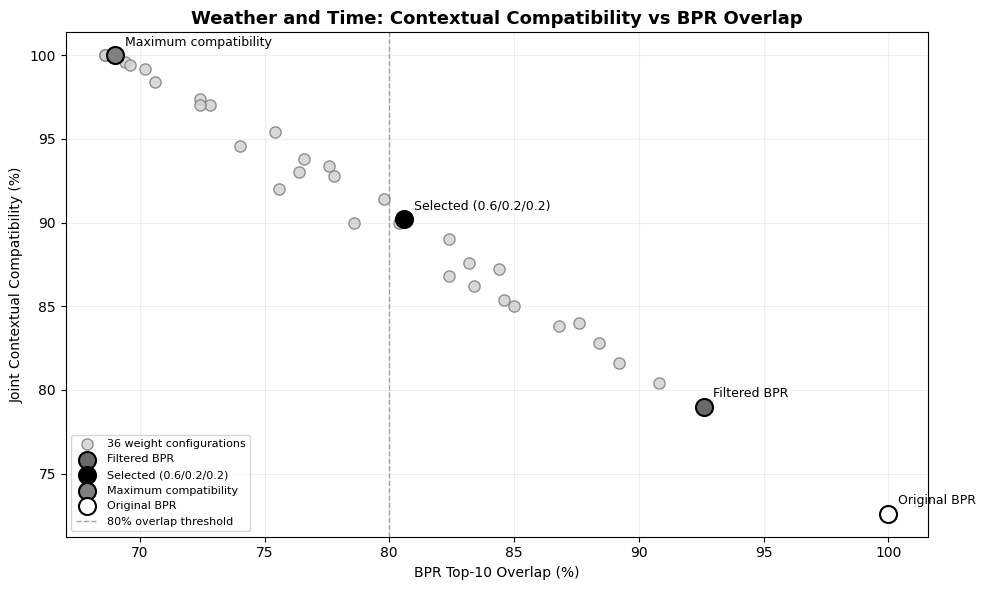

In [193]:

# EXPERIMENT 3: Joint compatibility vs BPR overlap
# Black-and-gray scatterplot for presentation

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

# All 36 configurations
ax.scatter(
    combined_experiment_df["top10_overlap_pct"],
    combined_experiment_df["joint_compatibility_pct"],
    color="lightgray",
    edgecolor="gray",
    s=65,
    alpha=0.85,
    label="36 weight configurations"
)

# Highlight important configurations
highlights = [
    ("Filtered BPR", 92.6, 79.0, "dimgray"),
    ("Selected (0.6/0.2/0.2)", 80.6, 90.2, "black"),
    ("Maximum compatibility", 69.0, 100.0, "gray"),
    ("Original BPR", 100.0, 72.6, "white")
]

for label, overlap, compatibility, color in highlights:
    ax.scatter(
        overlap,
        compatibility,
        color=color,
        edgecolor="black",
        linewidth=1.5,
        s=150,
        zorder=5,
        label=label
    )

    ax.annotate(
        label,
        (overlap, compatibility),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9
    )

ax.axvline(
    x=80,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    label="80% overlap threshold"
)

ax.set_title(
    "Weather and Time: Contextual Compatibility vs BPR Overlap",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("BPR Top-10 Overlap (%)")
ax.set_ylabel("Joint Contextual Compatibility (%)")

ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()

plt.show()


In [194]:

# STEP 13: Save weather/time evaluation results

output_dir = project / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

weather_experiment_df.to_csv(
    output_dir / "weather_weight_sensitivity_final.csv",
    index=False
)

time_experiment_df.to_csv(
    output_dir / "time_weight_sensitivity_final.csv",
    index=False
)

combined_experiment_df.to_csv(
    output_dir / "combined_weather_time_36_configs.csv",
    index=False
)

model_comparison_df.to_csv(
    output_dir / "weather_time_model_comparison.csv",
    index=False
)

fig.savefig(
    output_dir / "weather_time_tradeoff_final.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved 5 files to:", output_dir)


Saved 5 files to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed


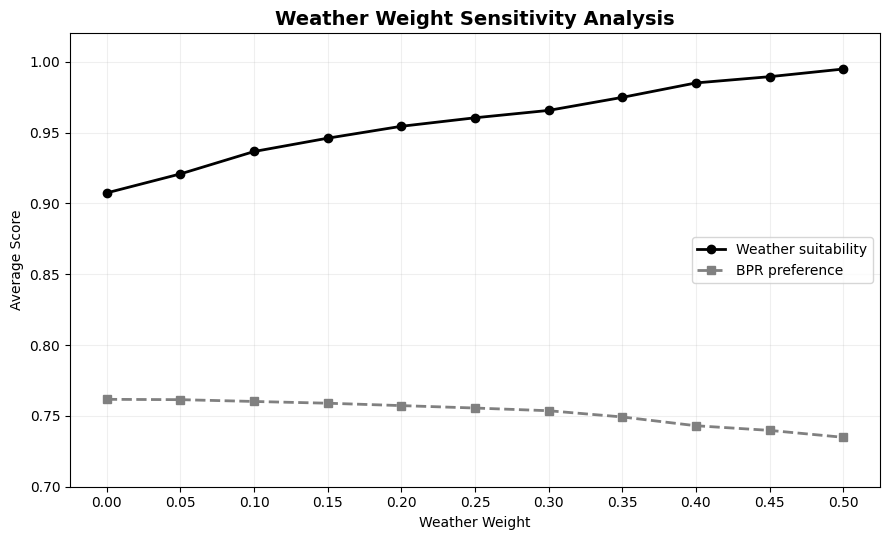

In [195]:

# STEP 15: Weather weight sensitivity line graph

import matplotlib.pyplot as plt

fig_weather, ax1 = plt.subplots(figsize=(9, 5.5))

ax1.plot(
    weather_experiment_df["weather_weight"],
    weather_experiment_df["weather_suitability"],
    color="black",
    marker="o",
    linewidth=2,
    label="Weather suitability"
)

ax1.plot(
    weather_experiment_df["weather_weight"],
    weather_experiment_df["bpr_preference"],
    color="gray",
    marker="s",
    linestyle="--",
    linewidth=2,
    label="BPR preference"
)

ax1.set_title(
    "Weather Weight Sensitivity Analysis",
    fontsize=14,
    fontweight="bold"
)

ax1.set_xlabel("Weather Weight")
ax1.set_ylabel("Average Score")
ax1.set_xticks(weather_experiment_df["weather_weight"])
ax1.set_ylim(0.70, 1.02)
ax1.grid(alpha=0.2)
ax1.legend(loc="center right")

plt.tight_layout()
plt.show()


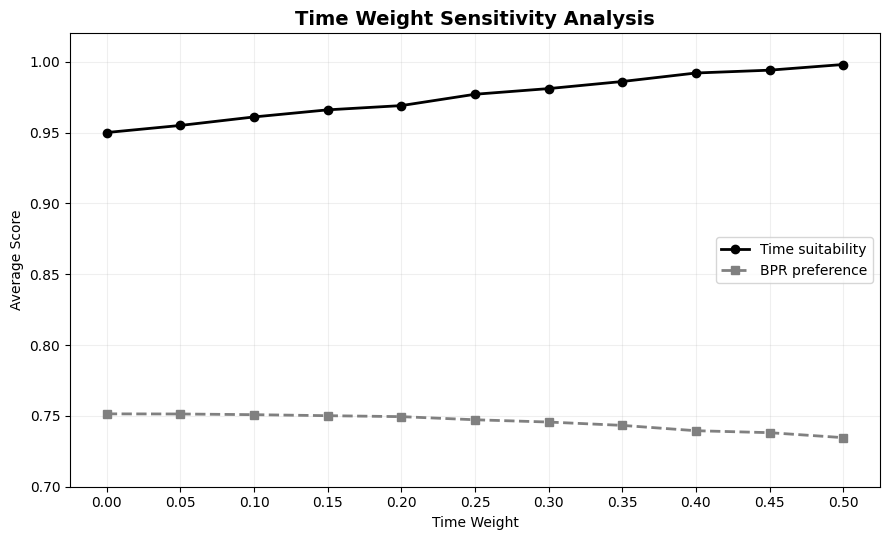

In [196]:

# STEP 16: Time weight sensitivity line graph

fig_time, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    time_experiment_df["time_weight"],
    time_experiment_df["time_suitability"],
    color="black",
    marker="o",
    linewidth=2,
    label="Time suitability"
)

ax.plot(
    time_experiment_df["time_weight"],
    time_experiment_df["bpr_preference"],
    color="gray",
    marker="s",
    linestyle="--",
    linewidth=2,
    label="BPR preference"
)

ax.set_title(
    "Time Weight Sensitivity Analysis",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Time Weight")
ax.set_ylabel("Average Score")
ax.set_xticks(time_experiment_df["time_weight"])
ax.set_ylim(0.70, 1.02)

ax.grid(alpha=0.2)
ax.legend(loc="center right")

plt.tight_layout()
plt.show()


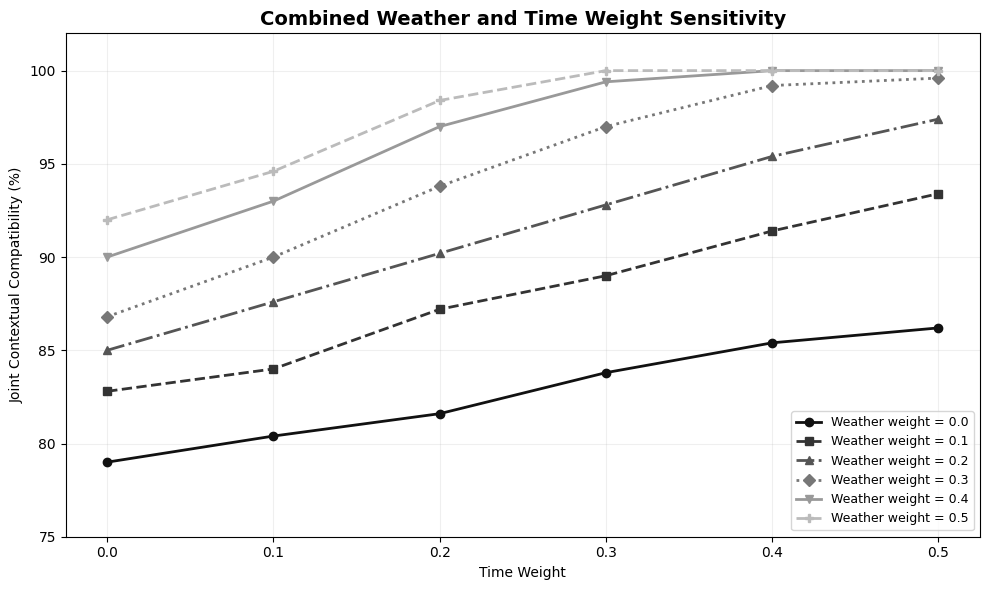

In [197]:

# STEP 17: Combined weather and time sensitivity
# Six lines representing six weather weights

fig_combined, ax = plt.subplots(figsize=(10, 6))

line_styles = ["-", "--", "-.", ":", "-", "--"]
markers = ["o", "s", "^", "D", "v", "P"]
gray_colors = ["#111111", "#333333", "#555555",
               "#777777", "#999999", "#BBBBBB"]

for i, weather_w in enumerate(
    sorted(combined_experiment_df["weather_weight"].unique())
):
    subset = combined_experiment_df[
        combined_experiment_df["weather_weight"] == weather_w
    ].sort_values("time_weight")

    ax.plot(
        subset["time_weight"],
        subset["joint_compatibility_pct"],
        color=gray_colors[i],
        linestyle=line_styles[i],
        marker=markers[i],
        linewidth=2,
        markersize=6,
        label=f"Weather weight = {weather_w:.1f}"
    )

ax.set_title(
    "Combined Weather and Time Weight Sensitivity",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Time Weight")
ax.set_ylabel("Joint Contextual Compatibility (%)")

ax.set_xticks(np.arange(0, 0.51, 0.1))
ax.set_ylim(75, 102)

ax.grid(alpha=0.2)
ax.legend(fontsize=9, loc="lower right")

plt.tight_layout()
plt.show()


In [198]:

# STEP 18: Save sensitivity analysis line graphs

output_dir = project / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

fig_weather.savefig(
    output_dir / "weather_weight_sensitivity_line.png",
    dpi=300,
    bbox_inches="tight"
)

fig_time.savefig(
    output_dir / "time_weight_sensitivity_line.png",
    dpi=300,
    bbox_inches="tight"
)

fig_combined.savefig(
    output_dir / "combined_weather_time_sensitivity_line.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved 3 line graphs to:", output_dir)


Saved 3 line graphs to: /Users/ogechikaesedebe/Downloads/Activity-Recommendation-System/data/processed


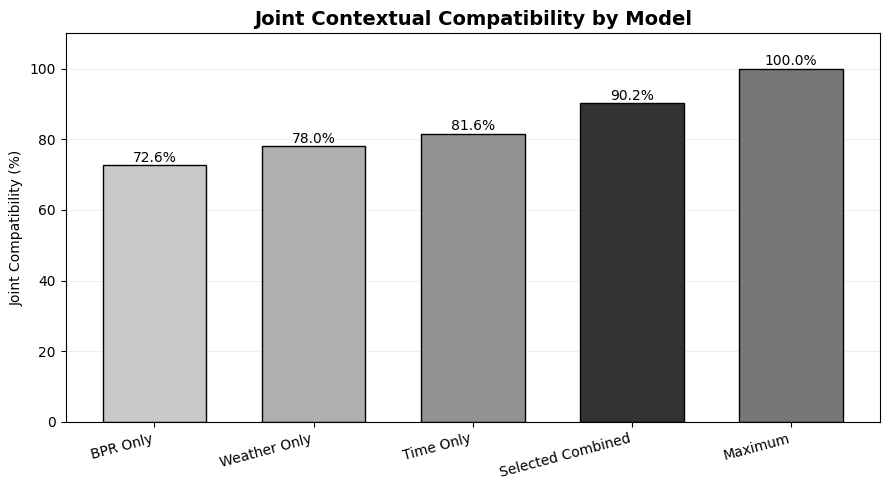

In [199]:

import matplotlib.pyplot as plt

# Use actual results from your notebook
results = model_comparison_df.copy()

fig_findings, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    results["model"],
    results["joint_compatibility_pct"],
    color=["#C9C9C9", "#AFAFAF", "#929292", "#333333", "#777777"],
    edgecolor="black",
    width=0.65
)

# Display values above each bar
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}%",
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Joint Contextual Compatibility by Model",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Joint Compatibility (%)")
ax.set_ylim(0, 110)

ax.set_xticks(range(len(results)))
ax.set_xticklabels(
    ["BPR Only", "Weather Only", "Time Only",
     "Selected Combined", "Maximum"],
    rotation=15,
    ha="right"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


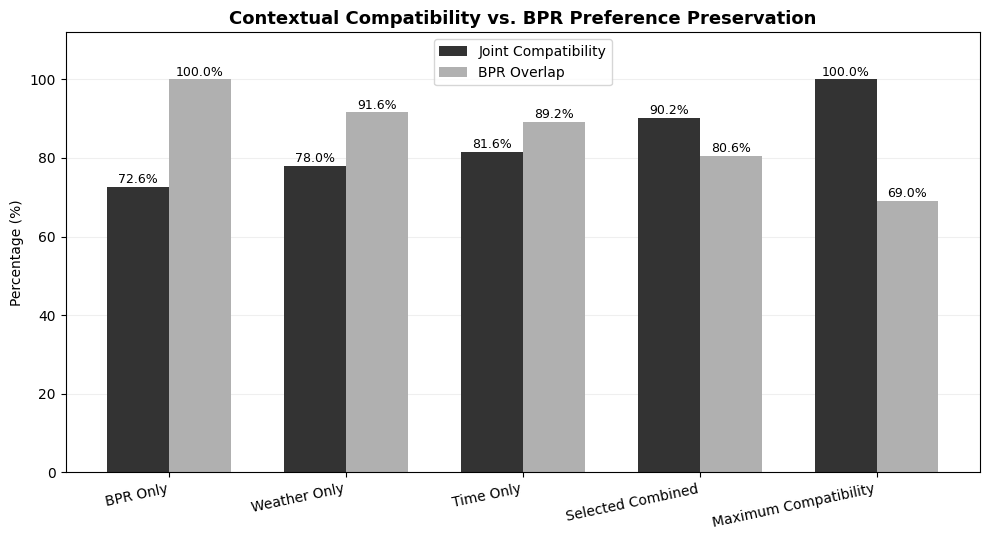

In [200]:

import numpy as np
import matplotlib.pyplot as plt

# Use the actual model comparison results
results = model_comparison_df.copy()

labels = [
    "BPR Only",
    "Weather Only",
    "Time Only",
    "Selected Combined",
    "Maximum Compatibility"
]

x = np.arange(len(labels))
width = 0.35

fig_preference, ax = plt.subplots(figsize=(10, 5.5))

bars1 = ax.bar(
    x - width/2,
    results["joint_compatibility_pct"],
    width,
    label="Joint Compatibility",
    color="#333333"
)

bars2 = ax.bar(
    x + width/2,
    results["bpr_overlap_pct"],
    width,
    label="BPR Overlap",
    color="#B0B0B0"
)

# Add percentage labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f"{height:.1f}%",
            ha="center",
            fontsize=9
        )

ax.set_title(
    "Contextual Compatibility vs. BPR Preference Preservation",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Percentage (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=12, ha="right")
ax.set_ylim(0, 112)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
